# Mutual Fund Analytics - Exploratory Data Analysis (EDA)

### Project Objective

Explore mutual fund scheme data, historical Net Asset Value (NAV), scheme performance, fund-house Assets Under Management (AUM), industry SIP inflows, investor transactions, portfolio holdings, and benchmark indices.

### Goals

- Understand the structure, coverage, and quality of the available datasets.
- Explore historical NAV behaviour and scheme performance.
- Analyse industry-level SIP inflows, AUM, and investor activity.
- Examine portfolio holdings and benchmark data where coverage permits.
- Identify meaningful patterns and limitations before building the final        analytics layer.

### Important limitations

- Ivestor transaction data is synthetic and wil be treated accordingly.
- Supplied scheme performance metrics will be compared with independently calculated returns; discrepancies will be documented rather than silently overwritten.
- AUM is available at fund-house level, so it will not be treated as scheme-level AUM.
- Findings are descriptive and historical, not investment recommendations.

In [1]:
import sys
print(sys.executable)

c:\Users\ASUS\Desktop\potfolio\Mutual_Fund_Project_V2\V2env\Scripts\python.exe


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
PROJECT_ROOT = Path.cwd().parent

In [4]:
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

In [5]:
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

In [6]:
print("Project root:", PROJECT_ROOT)
print("Raw data directory:", RAW_DATA_DIR)
print("Raw data directory exists:", RAW_DATA_DIR.exists())
print("Processed data directory exists:", PROCESSED_DATA_DIR.exists())

Project root: c:\Users\ASUS\Desktop\potfolio\Mutual_Fund_Project_V2
Raw data directory: c:\Users\ASUS\Desktop\potfolio\Mutual_Fund_Project_V2\data\raw
Raw data directory exists: True
Processed data directory exists: True


In [7]:

csv_files = sorted(RAW_DATA_DIR.glob("*.csv"))
inventory = []
for file_path in csv_files:
    df_sample = pd.read_csv(file_path, nrows=5)
    with open(file_path, encoding="utf-8") as file:
        row_count = sum(1 for _ in file) - 1
    inventory.append({
        "file_name": file_path.name,
        "rows": row_count,
        "columns": len(df_sample.columns),
        "size_kb": round(file_path.stat().st_size / 1024, 2),
        "column_names": ", ".join(df_sample.columns)
    })
dataset_inventory = pd.DataFrame(inventory)
print(f"Raw datasets found: {len(dataset_inventory)}")
display(dataset_inventory)

Raw datasets found: 10


,file_name,rows,columns,size_kb,column_names
0,01_fund_master.csv,40,15,6.66,"amfi_code, fund_house, scheme_name, category, ..."
1,02_nav_history.csv,46000,3,1190.99,"amfi_code, date, nav"
2,03_aum_by_fund_house.csv,90,5,3.92,"date, fund_house, aum_lakh_crore, aum_crore, n..."
3,04_monthly_sip_inflows.csv,48,6,1.63,"month, sip_inflow_crore, active_sip_accounts_c..."
4,05_category_inflows.csv,144,3,3.58,"month, category, net_inflow_crore"
5,06_industry_folio_count.csv,21,6,0.80,"month, total_folios_crore, equity_folios_crore..."
6,07_scheme_performance.csv,40,19,6.44,"amfi_code, scheme_name, fund_house, category, ..."
7,08_investor_transactions.csv,32778,13,3054.61,"investor_id, transaction_date, amfi_code, tran..."
8,09_portfolio_holdings.csv,322,8,23.35,"amfi_code, stock_symbol, stock_name, sector, w..."
9,10_benchmark_indices.csv,8050,3,245.09,"date, index_name, close_value"


In [8]:
datasets = {}
for file_path in csv_files:
    datasets[file_path.stem] = pd.read_csv(file_path)
print("Loaded datasets:", len(datasets))
for name, df in datasets.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Data types:")
    print(df.dtypes.to_string())

Loaded datasets: 10

01_fund_master
Shape: (40, 15)
Data types:
amfi_code               int64
fund_house                str
scheme_name               str
category                  str
sub_category              str
plan                      str
launch_date               str
benchmark                 str
expense_ratio_pct     float64
exit_load_pct         float64
min_sip_amount          int64
min_lumpsum_amount      int64
fund_manager              str
risk_category             str
sebi_category_code        str

02_nav_history
Shape: (46000, 3)
Data types:
amfi_code      int64
date             str
nav          float64

03_aum_by_fund_house
Shape: (90, 5)
Data types:
date                  str
fund_house            str
aum_lakh_crore    float64
aum_crore           int64
num_schemes         int64

04_monthly_sip_inflows
Shape: (48, 6)
Data types:
month                            str
sip_inflow_crore               int64
active_sip_accounts_crore    float64
new_sip_accounts_lakh        float64

In [9]:
quality_summary = []
for name, df in datasets.items():
    quality_summary.append({
        "dataset": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "memory_mb": round(df.memory_usage(deep=True).sum() / (1024 ** 2), 3)
    })
quality_summary = pd.DataFrame(quality_summary)
display(
    quality_summary.sort_values(
        "missing_cells",
        ascending=False
    ).reset_index(drop=True)
)

,dataset,rows,columns,missing_cells,duplicate_rows,memory_mb
0,04_monthly_sip_inflows,48,6,12,0,0.005
1,01_fund_master,40,15,0,0,0.025
2,02_nav_history,46000,3,0,0,3.290
3,03_aum_by_fund_house,90,5,0,0,0.013
4,05_category_inflows,144,3,0,0,0.017
5,06_industry_folio_count,21,6,0,0,0.002
6,07_scheme_performance,40,19,0,0,0.017
7,08_investor_transactions,32778,13,0,0,18.188
8,09_portfolio_holdings,322,8,0,0,0.083
9,10_benchmark_indices,8050,3,0,0,0.972


## 1. Dataset Loading and Data Quality

In [10]:
sip_df = datasets["04_monthly_sip_inflows"]
missing_by_column = (sip_df.isna().sum().sort_values(ascending=False))
print("Missing_by_column[missing_by_column > 0]")

print("\nRows containing missing values:")
display(sip_df[sip_df.isna().any(axis=1)])

Missing_by_column[missing_by_column > 0]

Rows containing missing values:


,month,sip_inflow_crore,active_sip_accounts_crore,new_sip_accounts_lakh,sip_aum_lakh_crore,yoy_growth_pct
0,2022-01,11517,4.91,9.10,4.80,NaN
1,2022-02,11438,4.93,8.20,4.85,NaN
2,2022-03,12328,5.09,10.50,5.01,NaN
3,2022-04,11863,5.48,9.52,5.12,NaN
4,2022-05,12286,5.55,8.10,5.15,NaN
5,2022-06,12276,5.60,7.50,5.18,NaN
6,2022-07,12140,5.65,9.21,5.25,NaN
7,2022-08,12694,5.71,8.90,5.31,NaN
8,2022-09,12976,5.80,9.40,5.41,NaN
9,2022-10,13040,5.93,9.52,5.55,NaN


In [11]:
blank_summary = []
for name, df in datasets.items():
    blank_cells = (df.astype("string").apply(lambda col: col.str.strip().eq("").sum()).sum())
    blank_summary.append({
        "dataset": name,
        "blank_string_cells": int(blank_cells)
    })
blank_summary = pd.DataFrame(blank_summary)
display(blank_summary.sort_values("blank_string_cells", ascending=False).reset_index(drop=True))


,dataset,blank_string_cells
0,01_fund_master,0
1,02_nav_history,0
2,03_aum_by_fund_house,0
3,04_monthly_sip_inflows,0
4,05_category_inflows,0
5,06_industry_folio_count,0
6,07_scheme_performance,0
7,08_investor_transactions,0
8,09_portfolio_holdings,0
9,10_benchmark_indices,0


In [12]:
column_profile = []
for name, df in datasets.items():
    for col in df.columns:
        column_profile.append({
            "dataset": name,
            "column": col,
            "dtype": str(df[col].dtype),
            "missing_values": int(df[col].isna().sum()),
            "unique_values": int(df[col].nunique(dropna=True))
        })
column_profile = pd.DataFrame(column_profile)
display(
    column_profile[
        (column_profile["missing_values"] > 0)
        | (column_profile["dtype"] == "str")
        | (column_profile["dtype"] == "object")
    ].reset_index(drop=True)
)        

,dataset,column,dtype,missing_values,unique_values
0,01_fund_master,fund_house,str,0,10
1,01_fund_master,scheme_name,str,0,40
2,01_fund_master,category,str,0,2
3,01_fund_master,sub_category,str,0,12
4,01_fund_master,plan,str,0,2
5,01_fund_master,launch_date,str,0,34
6,01_fund_master,benchmark,str,0,10
7,01_fund_master,fund_manager,str,0,29
8,01_fund_master,risk_category,str,0,5
9,01_fund_master,sebi_category_code,str,0,9


In [13]:
date_columns = {
    "01_fund_master": ["launch_date"],
    "02_nav_history": ["date"],
    "03_aum_by_fund_house": ["date"],
    "04_monthly_sip_inflows": ["month"],
    "05_category_inflows": ["month"],
    "06_industry_folio_count": ["month"],
    "08_investor_transactions": ["transaction_date"],
    "09_portfolio_holdings": ["portfolio_date"],
    "10_benchmark_indices": ["date"],
}
date_check_results = []
for dataset_name, columns in date_columns.items():
    df = datasets[dataset_name]
    for column in columns:
        parsed_dates = pd.to_datetime(df[column], errors="coerce")
        date_check_results.append({
            "dataset": dataset_name,
            "column": column,
            "rows": len(df),
            "unparseable_values": int(parsed_dates.isna().sum()),
            "earliest_date": parsed_dates.min(),
            "latest_date": parsed_dates.max()
        })
date_check_results = pd.DataFrame(date_check_results)
display(date_check_results)

,dataset,column,rows,unparseable_values,earliest_date,latest_date
0,01_fund_master,launch_date,40,0,1996-09-11,2015-12-28
1,02_nav_history,date,46000,0,2022-01-03,2026-05-29
2,03_aum_by_fund_house,date,90,0,2022-03-31,2025-12-31
3,04_monthly_sip_inflows,month,48,0,2022-01-01,2025-12-01
4,05_category_inflows,month,144,0,2024-04-01,2025-03-01
5,06_industry_folio_count,month,21,0,2022-01-01,2025-12-01
6,08_investor_transactions,transaction_date,32778,0,2024-01-01,2025-05-30
7,09_portfolio_holdings,portfolio_date,322,0,2025-12-31,2025-12-31
8,10_benchmark_indices,date,8050,0,2022-01-03,2026-05-29


In [14]:
numeric_summary = []
for name, df in datasets.items():
    numeric_df = df.select_dtypes(include="number")
    for column in numeric_df.columns:
        numeric_summary.append({
            "dataset": name,
            "column": column,
            "min": numeric_df[column].min(),
            "max": numeric_df[column].max(),
            "negative_values": int((numeric_df[column] < 0).sum()),
            "zero_values": int((numeric_df[column] == 0).sum())
        })
numeric_summary = pd.DataFrame(numeric_summary)
display(numeric_summary)

,dataset,column,min,max,negative_values,zero_values
0,01_fund_master,amfi_code,100016.0000,1.493240e+05,0,0
1,01_fund_master,expense_ratio_pct,0.5500,1.640000e+00,0,0
2,01_fund_master,exit_load_pct,0.0000,1.000000e+00,0,7
3,01_fund_master,min_sip_amount,500.0000,5.000000e+02,0,0
4,01_fund_master,min_lumpsum_amount,100.0000,5.000000e+03,0,0
5,02_nav_history,amfi_code,100016.0000,1.493240e+05,0,0
6,02_nav_history,nav,26.1366,4.268550e+03,0,0
7,03_aum_by_fund_house,aum_lakh_crore,1.0500,1.250000e+01,0,0
8,03_aum_by_fund_house,aum_crore,105000.0000,1.250000e+06,0,0
9,03_aum_by_fund_house,num_schemes,56.0000,2.160000e+02,0,0


In [15]:
performance_df = datasets["07_scheme_performance"]
drawdown_check = performance_df[["scheme_name", "max_drawdown_pct"]].copy()
print("Maximum drawdown summary:")
display(drawdown_check["max_drawdown_pct"].describe())
print("\nSample of maximum drawdown vakues:")
display(drawdown_check.head(10))

Maximum drawdown summary:


count    40.000000
mean    -19.200250
std       8.819164
min     -33.500000
25%     -25.062500
50%     -20.600000
75%     -14.255000
max      -2.230000
Name: max_drawdown_pct, dtype: float64


Sample of maximum drawdown vakues:


,scheme_name,max_drawdown_pct
0,SBI Bluechip Fund - Regular Plan - Growth,-21.70
1,SBI Bluechip Fund - Direct Plan - Growth,-24.43
2,SBI Small Cap Fund - Regular Plan - Growth,-13.35
3,SBI Small Cap Fund - Direct Plan - Growth,-24.78
4,SBI Magnum Gilt Fund - Regular Plan - Growth,-2.30
5,HDFC Top 100 Fund - Regular Plan - Growth,-17.41
6,HDFC Top 100 Fund - Direct Plan - Growth,-33.50
7,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,-13.67
8,HDFC Mid-Cap Opportunities Fund - Direct - Growth,-32.22
9,HDFC Short Term Debt Fund - Regular - Growth,-6.01


In [16]:
performance_numeric = performance_df.select_dtypes(include="number")
performance_stats = performance_numeric.describe().T
performance_stats["missing_values"] = performance_numeric.isna().sum()
performance_stats["zero_values"] = (performance_numeric == 0).sum()
display(
    performance_stats[
        ["count", "mean", "std", "min", "25%", "50%", "75%", "max", "missing_values", "zero_values"]
    ].round(3)
)

,count,mean,std,min,25%,50%,75%,max,missing_values,zero_values
amfi_code,40.0,120247.000,14534.999,100016.00,118632.750,119551.500,120842.250,149324.00,0,0
return_1yr_pct,40.0,14.376,4.883,4.26,11.735,14.620,16.393,24.93,0,0
return_3yr_pct,40.0,14.089,4.617,5.14,12.035,14.205,15.882,23.39,0,0
return_5yr_pct,40.0,14.517,4.454,5.43,12.340,14.185,17.585,23.80,0,0
benchmark_3yr_pct,40.0,12.836,4.741,3.96,10.690,13.090,14.775,22.16,0,0
alpha,40.0,1.254,0.447,0.51,0.888,1.205,1.700,1.98,0,0
beta,40.0,0.873,0.225,0.22,0.890,0.960,1.000,1.04,0,0
sharpe_ratio,40.0,1.362,1.476,0.80,0.865,0.925,0.985,7.68,0,0
sortino_ratio,40.0,2.082,2.203,1.03,1.270,1.445,1.638,10.37,0,0
std_dev_ann_pct,40.0,14.962,6.669,0.50,14.000,14.000,19.000,25.00,0,0


## 2. Fund Master, NAV and Benchmark Analysis

In [1]:
fund_master_df = datasets["01_fund_master"]
print("Schemes by category:")
display(fund_master_df["category"].value_counts().rename_axis("category").reset_index(name="scheme_count"))
print("\nCategory-plan combinations:")
display(
    pd.crosstab(
        fund_master_df["category"],
        fund_master_df["plan"]
    )
)

NameError: name 'datasets' is not defined

In [ ]:
print("Schemes by category and subcategory:")
display(
    fund_master_df.groupby(["category", "sub_category"], dropna=False).size()
    .reset_index(name="scheme_count")
    .sort_values(["category", "scheme_count"], ascending=[True, False])
    .reset_index(drop=True)
)

Schemes by category and subcategory:


,category,sub_category,scheme_count
0,Debt,Liquid,3
1,Debt,Gilt,2
2,Debt,Short Duration,1
3,Equity,Large Cap,14
4,Equity,Mid Cap,7
5,Equity,Small Cap,6
6,Equity,Flexi Cap,2
7,Equity,ELSS,1
8,Equity,Index,1
9,Equity,Index/ETF,1


In [ ]:
print("Schemes by benchmark:")
display(fund_master_df["benchmark"]
.value_counts(dropna=False)
.rename_axis("benchmark")
.reset_index(name="scheme_count"))

Schemes by benchmark:


,benchmark,scheme_count
0,NIFTY 100 TRI,14
1,BSE 250 SmallCap TRI,6
2,NIFTY Midcap 150 TRI,6
3,NIFTY 500 TRI,4
4,CRISIL Liquid Fund AI Index,3
5,CRISIL Dynamic Gilt Index,2
6,NIFTY 50 TRI,2
7,CRISIL Short Term Bond Index,1
8,NIFTY Midcap 50 TRI,1
9,NIFTY Large Midcap 250 TRI,1


In [ ]:
benchmark_df = datasets["10_benchmark_indices"]
print("Available benchmark index names:")
display(benchmark_df["index_name"]
.value_counts()
.rename_axis("index_name")
.reset_index(name="observations"))

Available benchmark index names:


,index_name,observations
0,NIFTY50,1150
1,NIFTY100,1150
2,NIFTY_MIDCAP150,1150
3,BSE_SMALLCAP,1150
4,NIFTY500,1150
5,CRISIL_LIQUID,1150
6,CRISIL_GILT,1150


In [ ]:
benchmark_df["date"] = pd.to_datetime(benchmark_df["date"])

In [ ]:
display(
    benchmark_df.loc[
        (benchmark_df["index_name"] == "BSE_SMALLCAP")
        & benchmark_df["date"].between(
            pd.Timestamp("2023-09-13"),
            pd.Timestamp("2023-09-18")
        ),
        ["date", "index_name", "close_value"]
    ].sort_values("date")
)

,date,index_name,close_value
3892,2023-09-13,BSE_SMALLCAP,28822.07
3893,2023-09-14,BSE_SMALLCAP,28635.46
3894,2023-09-15,BSE_SMALLCAP,29601.16
3895,2023-09-18,BSE_SMALLCAP,29673.85


In [ ]:
previous_close = 28635.46
current_close = 29601.16
benchmark_return = (
    current_close / previous_close - 1
) * 100
print(f"Calculated benchmark return: {benchmark_return:.3f}%")

Calculated benchmark return: 3.372%


In [ ]:
benchmark_returns = (benchmark_df.loc[benchmark_df["index_name"] == "BSE_SMALLCAP"].copy().sort_values("date"))
benchmark_returns["date"] = pd.to_datetime(benchmark_returns["date"])
benchmark_returns["close_value"] = pd.to_numeric(benchmark_returns["close_value"], errors="coerce")
benchmark_returns["benchmark_daily_return_pct"] = (benchmark_returns["close_value"].pct_change() * 100)
display(benchmark_returns[["date", "close_value", "benchmark_daily_return_pct"]].head(10).round(3))

C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\1512112494.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(benchmark_returns[["date", "close_value", "benchmark_daily_return_pct"]].head(10).round(3))


,date,close_value,benchmark_daily_return_pct
3450,2022-01-03,26554.60,NaN
3451,2022-01-04,27079.92,1.978
3452,2022-01-05,27313.35,0.862
3453,2022-01-06,27377.05,0.233
3454,2022-01-07,26316.86,-3.873
3455,2022-01-10,26476.06,0.605
3456,2022-01-11,26462.96,-0.049
3457,2022-01-12,26090.99,-1.406
3458,2022-01-13,26085.36,-0.022
3459,2022-01-14,26081.45,-0.015


In [ ]:
fund_benchmarks = (fund_master_df["benchmark"].value_counts().rename_axis("fund_master_benchmark").reset_index(name="scheme_count"))
available_indices = (benchmark_df["index_name"].drop_duplicates().sort_values().tolist())
print("Fund-master benchmark labels:")
display(fund_benchmarks)
print("\nAvailable index labels:")
display(pd.DataFrame({"index_name": available_indices}))

Fund-master benchmark labels:


,fund_master_benchmark,scheme_count
0,NIFTY 100 TRI,14
1,BSE 250 SmallCap TRI,6
2,NIFTY Midcap 150 TRI,6
3,NIFTY 500 TRI,4
4,CRISIL Liquid Fund AI Index,3
5,CRISIL Dynamic Gilt Index,2
6,NIFTY 50 TRI,2
7,CRISIL Short Term Bond Index,1
8,NIFTY Midcap 50 TRI,1
9,NIFTY Large Midcap 250 TRI,1



Available index labels:


,index_name
0,BSE_SMALLCAP
1,CRISIL_GILT
2,CRISIL_LIQUID
3,NIFTY100
4,NIFTY50
5,NIFTY500
6,NIFTY_MIDCAP150


In [ ]:
benchmark_mapping = pd.DataFrame([
    {
        "fund_master_benchmark": "NIFTY 100 TRI",
        "index_name": "NIFTY100",
        "mapping_status": "Candidate - verify index methodology",
    },
    {
        "fund_master_benchmark": "BSE 250 SmallCap TRI",
        "index_name": "BSE_SMALLCAP",
        "mapping_status": "Candidate - verify index methodology",
    },
    {
        "fund_master_benchmark": "NIFTY_Midcap 150 TRI",
        "index_name": "NIFTY_MIDCAP150",
        "mapping_status": "Candidate - verify index methodology",
    },
    {
        "fund_master_benchmark": "NIFTY 500 TRI",
        "index_name": "NIFTY500",
        "mapping_status": "Candidate - verify index methodology",
    },
    {
        "fund_master_benchmark": "CRISIL Liquid Fund All Index",
        "index_name": "CRISIL_LIQUID",
        "mapping_status": "Candidate - verify index methodology",
    },
    {
        "fund_master_benchmark": "CRISIL Dynamic Gilt Index",
        "index_name": "CRISIL_GILT",
        "mapping_status": "Candidate - verify index methodology",
    },
    {
        "fund_master_benchmark": "NIFTY 50 TRI",
        "index_name": "NIFTY50",
        "mapping_status": "Candidate - verify index methodology",
    },
    {
        "fund_master_benchmark": "CRISIL Short Term Bond Index",
        "index_name": None,
        "mapping_status": "Candidate - verify index methodology",
    },
    {
        "fund_master_benchmark": "NIFTY Midcap 50 TRI",
        "index_name": None,
        "mapping_status": "Candidate - verify index methodology",
    },  
    {
        "fund_master_benchmark": "NIFTY Large Midcap 250 TRI",
        "index_name": None,
        "mapping_status": "Candidate - verify index methodology",
    }                          
])
display(benchmark_mapping)

,fund_master_benchmark,index_name,mapping_status
0,NIFTY 100 TRI,NIFTY100,Candidate - verify index methodology
1,BSE 250 SmallCap TRI,BSE_SMALLCAP,Candidate - verify index methodology
2,NIFTY_Midcap 150 TRI,NIFTY_MIDCAP150,Candidate - verify index methodology
3,NIFTY 500 TRI,NIFTY500,Candidate - verify index methodology
4,CRISIL Liquid Fund All Index,CRISIL_LIQUID,Candidate - verify index methodology
5,CRISIL Dynamic Gilt Index,CRISIL_GILT,Candidate - verify index methodology
6,NIFTY 50 TRI,NIFTY50,Candidate - verify index methodology
7,CRISIL Short Term Bond Index,NaN,Candidate - verify index methodology
8,NIFTY Midcap 50 TRI,NaN,Candidate - verify index methodology
9,NIFTY Large Midcap 250 TRI,NaN,Candidate - verify index methodology


In [ ]:
unresolved_benchmarks = [
    "CRISIL Short Term Bond Index",
    "NIFTY Midcap 50 TRI",
    "NIFTY Large Midcap 250 TRI"
]
benchmark_mapping.loc[
    benchmark_mapping["fund_master_benchmark"].isin(unresolved_benchmarks),
    "mapping_status"
] = "Unresolved - no matching label"
display(benchmark_mapping)

,fund_master_benchmark,index_name,mapping_status
0,NIFTY 100 TRI,NIFTY100,Candidate - verify index methodology
1,BSE 250 SmallCap TRI,BSE_SMALLCAP,Candidate - verify index methodology
2,NIFTY_Midcap 150 TRI,NIFTY_MIDCAP150,Candidate - verify index methodology
3,NIFTY 500 TRI,NIFTY500,Candidate - verify index methodology
4,CRISIL Liquid Fund All Index,CRISIL_LIQUID,Candidate - verify index methodology
5,CRISIL Dynamic Gilt Index,CRISIL_GILT,Candidate - verify index methodology
6,NIFTY 50 TRI,NIFTY50,Candidate - verify index methodology
7,CRISIL Short Term Bond Index,NaN,Unresolved - no matching label
8,NIFTY Midcap 50 TRI,NaN,Unresolved - no matching label
9,NIFTY Large Midcap 250 TRI,NaN,Unresolved - no matching label


In [ ]:
nav_df = datasets["02_nav_history"].copy()
nav_df["date"] = pd.to_datetime(nav_df["date"], errors="coerce")
nav_df["nav"] = pd.to_numeric(nav_df["nav"], errors="coerce")
nav_coverage = (nav_df.groupby("amfi_code")
                .agg(
        observations=("nav", "count"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        unique_date=("date", "nunique")
    ).reset_index()
)
nav_coverage["date_span_days"] = (nav_coverage["last_date"] - nav_coverage["first_date"]).dt.days
print("NAV coverage summary across funds:")
display(nav_coverage[["observations", "date_span_days"]].describe().round(1))
print("\nFunds with the fewest NAV observatons:")
display(nav_coverage.sort_values("observations").head(10).reset_index(drop=True))

NAV coverage summary across funds:


,observations,date_span_days
count,40.0,40.0
mean,1150.0,1607.0
std,0.0,0.0
min,1150.0,1607.0
25%,1150.0,1607.0
50%,1150.0,1607.0
75%,1150.0,1607.0
max,1150.0,1607.0



Funds with the fewest NAV observatons:


,amfi_code,observations,first_date,last_date,unique_date,date_span_days
0,100016,1150,2022-01-03,2026-05-29,1150,1607
1,100025,1150,2022-01-03,2026-05-29,1150,1607
2,100033,1150,2022-01-03,2026-05-29,1150,1607
3,101206,1150,2022-01-03,2026-05-29,1150,1607
4,101207,1150,2022-01-03,2026-05-29,1150,1607
5,101208,1150,2022-01-03,2026-05-29,1150,1607
6,102885,1150,2022-01-03,2026-05-29,1150,1607
7,102886,1150,2022-01-03,2026-05-29,1150,1607
8,102887,1150,2022-01-03,2026-05-29,1150,1607
9,118632,1150,2022-01-03,2026-05-29,1150,1607


In [ ]:
nav_dates = (nav_df[["date"]].drop_duplicates().sort_values("date").copy())
nav_dates["gap_days"] = nav_dates["date"].diff().dt.days
print("Gap between consecutive NAV dates(calender days):")
display(nav_dates["gap_days"].describe().round(1))
print("\nLargest calender-date gaps:")
display(nav_dates.nlargest(10, "gap_days")
        [["date", "gap_days"]].reset_index(drop=True))

Gap between consecutive NAV dates(calender days):


count    1149.0
mean        1.4
std         0.8
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         3.0
Name: gap_days, dtype: float64


Largest calender-date gaps:


,date,gap_days
0,2022-01-10,3.0
1,2022-01-17,3.0
2,2022-01-24,3.0
3,2022-01-31,3.0
4,2022-02-07,3.0
5,2022-02-14,3.0
6,2022-02-21,3.0
7,2022-02-28,3.0
8,2022-03-07,3.0
9,2022-03-14,3.0


In [ ]:
fund_returns = (nav_df.loc[nav_df["amfi_code"] == 119598].copy().sort_values("date"))
fund_returns["date"] = pd.to_datetime(fund_returns["date"])
fund_returns["nav"] = pd.to_numeric(fund_returns["nav"], errors="coerce")
fund_returns["fund_daily_return_pct"] = (fund_returns["nav"].pct_change() * 100)
comparison = fund_returns[
    ["date", "nav", "fund_daily_return_pct"]
].merge(
    benchmark_returns[
        ["date", "benchmark_daily_return_pct"]
    ],
    on="date",
    how="inner",
    validate="one_to_one"
)
comparison["return_difference_pct_points"] = (comparison["fund_daily_return_pct"] - comparison["benchmark_daily_return_pct"])
display(
    comparison.loc[
        comparison["date"].isin(
            pd.to_datetime(["2024-04-12", "2024-04-15", "2024-04-16"])
        )
    ].round(3)
)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\941601667.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,date,nav,fund_daily_return_pct,benchmark_daily_return_pct,return_difference_pct_points
594,2024-04-12,177.582,0.892,-0.635,1.527
595,2024-04-15,189.074,6.471,1.137,5.334
596,2024-04-16,183.129,-3.144,2.077,-5.222


In [ ]:
fund_return_summary = (comparison["fund_daily_return_pct"].dropna().describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]))
display(fund_return_summary.round(3))

count    1149.000
mean        0.120
std         1.584
min        -4.518
1%         -3.340
5%         -2.451
50%         0.125
95%         2.773
99%         3.742
max         6.471
Name: fund_daily_return_pct, dtype: float64

In [ ]:
comparison_summary = comparison[
    [
        "fund_daily_return_pct",
        "benchmark_daily_return_pct",
        "return_difference_pct_points"
    ]
].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]).T
display(comparison_summary.round(3))

,count,mean,std,min,1%,5%,50%,95%,99%,max
fund_daily_return_pct,1149.0,0.120,1.584,-4.518,-3.340,-2.451,0.125,2.773,3.742,6.471
benchmark_daily_return_pct,1149.0,0.104,1.395,-3.972,-3.042,-2.195,0.081,2.483,3.316,4.185
return_difference_pct_points,1149.0,0.016,2.154,-7.194,-4.488,-3.610,0.037,3.655,5.248,7.156


In [ ]:
largest_differences = (
    comparison.dropna(
        subset=[
            "fund_daily_return_pct",
            "benchmark_daily_return_pct"
        ]
    )
    .assign(
        absolute_difference=lambda df:
            df["return_difference_pct_points"].abs()
    )
    .nlargest(10, "absolute_difference")
    [
        [
            "date",
            "nav",
            "fund_daily_return_pct",
            "benchmark_daily_return_pct",
            "return_difference_pct_points"
        ]
    ]
    .copy()
)

largest_differences["date"] = (
    largest_differences["date"].dt.strftime("%Y-%m-%d")
)

display(largest_differences.round(3))

,date,nav,fund_daily_return_pct,benchmark_daily_return_pct,return_difference_pct_points
444,2023-09-15,211.454,-3.821,3.372,-7.194
4,2022-01-07,91.424,3.283,-3.873,7.156
171,2022-08-30,115.342,3.884,-2.987,6.870
1012,2025-11-19,240.573,3.430,-2.697,6.127
420,2023-08-14,181.328,3.215,-2.874,6.089
865,2025-04-28,172.871,-2.636,3.440,-6.076
375,2023-06-12,147.379,-2.959,3.032,-5.991
1134,2026-05-08,313.520,3.734,-2.187,5.921
1098,2026-03-19,271.946,3.732,-2.050,5.782
717,2024-10-02,197.405,-4.279,1.441,-5.719


In [ ]:
largest_absolute_differences = (
    comparison.assign(
        abs_difference=(
            comparison["return_difference_pct_points"].abs()
        )
    )
    .nlargest(10, "abs_difference")
    [
        [
            "date",
            "fund_daily_return_pct",
            "benchmark_daily_return_pct",
            "return_difference_pct_points",
            "abs_difference"
        ]
    ]
    .copy()
)

display(largest_absolute_differences.round(3))

C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\1006937590.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(largest_absolute_differences.round(3))


,date,fund_daily_return_pct,benchmark_daily_return_pct,return_difference_pct_points,abs_difference
444,2023-09-15,-3.821,3.372,-7.194,7.194
4,2022-01-07,3.283,-3.873,7.156,7.156
171,2022-08-30,3.884,-2.987,6.870,6.870
1012,2025-11-19,3.430,-2.697,6.127,6.127
420,2023-08-14,3.215,-2.874,6.089,6.089
865,2025-04-28,-2.636,3.440,-6.076,6.076
375,2023-06-12,-2.959,3.032,-5.991,5.991
1134,2026-05-08,3.734,-2.187,5.921,5.921
1098,2026-03-19,3.732,-2.050,5.782,5.782
717,2024-10-02,-4.279,1.441,-5.719,5.719


In [ ]:
expected_dates = set(nav_df["date"].drop_duplicates())

fund_date_check = (
    nav_df.groupby("amfi_code")["date"]
    .agg(
        observations="count",
        unique_dates="nunique",
        first_date="min",
        last_date="max",
    )
    .reset_index()
)

fund_date_check["missing_dates"] = (
    len(expected_dates) - fund_date_check["unique_dates"]
)

print("Funds with missing NAV dates:", (fund_date_check["missing_dates"] > 0).sum())
print("Funds with duplicate dates:", (
    fund_date_check["observations"] != fund_date_check["unique_dates"]
).sum())

display(fund_date_check[fund_date_check["missing_dates"] > 0])

Funds with missing NAV dates: 0
Funds with duplicate dates: 0


,amfi_code,observations,unique_dates,first_date,last_date,missing_dates


In [ ]:
expected_dates = set(nav_df["date"].drop_duplicates())
date_set_check = (nav_df.groupby("amfi_code")["date"].apply(lambda dates: set(dates) == expected_dates))
print("Funds matching the complete NAV date set:", date_set_check.sum())
print("Funds not matching:", (~date_set_check).sum())

Funds matching the complete NAV date set: 40
Funds not matching: 0


In [ ]:
check_date = pd.Timestamp("2023-09-15")

display(
    comparison.loc[
        comparison["date"] == check_date,
        [
            "date",
            "nav",
            "fund_daily_return_pct",
            "benchmark_daily_return_pct",
            "return_difference_pct_points"
        ]
    ]
)

display(
    nav_df.loc[
        (nav_df["amfi_code"] == 119598)
        & nav_df["date"].between(
            pd.Timestamp("2023-09-13"),
            pd.Timestamp("2023-09-18")
        ),
        ["amfi_code", "date", "nav"]
    ].sort_values("date")
)

,date,nav,fund_daily_return_pct,benchmark_daily_return_pct,return_difference_pct_points
444,2023-09-15,211.4539,-3.821463,3.372392,-7.193855


,amfi_code,date,nav
2742,119598,2023-09-13,217.7414
2743,119598,2023-09-14,219.8556
2744,119598,2023-09-15,211.4539
2745,119598,2023-09-18,210.6523


In [ ]:
nav_movements = nav_df.sort_values(["amfi_code", "date"]).copy()
nav_movements["daily_change_pct"] = (nav_movements.groupby("amfi_code")["nav"].pct_change() * 100)
largest_movements = (
    nav_movements.dropna(subset=["daily_change_pct"])
    .assign(abs_change=lambda df: df["daily_change_pct"].abs())
    .nlargest(10, "abs_change")
    [["amfi_code", "date", "nav", "daily_change_pct"]]
    .copy()
)

largest_movements["nav"] = largest_movements["nav"].round(3)
largest_movements["daily_change_pct"] = (largest_movements["daily_change_pct"].round(3))
display(largest_movements)

,amfi_code,date,nav,daily_change_pct
2895,119598,2024-04-15,189.074,6.471
20126,118634,2024-03-19,110.540,5.930
19674,118634,2022-06-24,67.253,-5.810
33957,101207,2024-05-01,65.588,5.485
3716,119599,2023-01-10,153.222,5.332
33667,101207,2023-03-22,56.833,-5.185
3982,119599,2024-01-17,136.824,5.181
2305,119598,2022-01-10,96.096,5.111
19852,118634,2023-03-01,113.580,-5.034
2521,119598,2022-11-08,123.970,4.905


In [ ]:
extreme_keys = largest_movements[["amfi_code", "date"]].copy()
nav_context = nav_movements.merge(extreme_keys.assign(extreme=True), on=["amfi_code", "date"], how="left")
nav_context["extreme"] = nav_context["extreme"].fillna(False)
context_parts = []
for _, event in extreme_keys.iterrows():
    fund_code = event["amfi_code"]
    event_date = event["date"]
    fund_history = nav_context[nav_context["amfi_code"] == fund_code].sort_values("date").reset_index(drop=True)
    matching_rows = fund_history.index[fund_history["date"] == event_date]
    if len(matching_rows) == 0:
        continue
    position = matching_rows[0]
    start = max(0, position - 2)
    end = min(len(fund_history), position + 3)
    context = fund_history.iloc[start:end].copy()
    context["event_date"] = event_date
    context_parts.append(context)
nav_context_check = pd.concat(context_parts, ignore_index=True)
display(nav_context_check[
    [
        "amfi_code",
        "date",
        "nav",
        "daily_change_pct",
        "extreme",
        "event_date"
    ]
].sort_values(["amfi_code", "event_date", "date"]))

,amfi_code,date,nav,daily_change_pct,extreme,event_date
25,101207,2023-03-20,58.6586,-3.173112,False,2023-03-22
26,101207,2023-03-21,59.9403,2.185016,False,2023-03-22
27,101207,2023-03-22,56.8326,-5.184659,True,2023-03-22
28,101207,2023-03-23,56.4875,-0.607222,False,2023-03-22
29,101207,2023-03-24,55.1338,-2.396459,False,2023-03-22
15,101207,2024-04-29,61.9735,1.694762,False,2024-05-01
16,101207,2024-04-30,62.1777,0.329496,False,2024-05-01
17,101207,2024-05-01,65.5882,5.485085,True,2024-05-01
18,101207,2024-05-02,65.3560,-0.354027,False,2024-05-01
19,101207,2024-05-03,64.1183,-1.893782,False,2024-05-01


In [ ]:
nav_df.loc[
    (nav_df["amfi_code"] == 119598)
    & (nav_df["date"] == pd.Timestamp("2024-04-15")),
    ["amfi_code", "date", "nav"]
]

,amfi_code,date,nav
2895,119598,2024-04-15,189.0742


In [ ]:
fund_history = (
    nav_df.loc[nav_df["amfi_code"] == 119598]
    .sort_values("date")
    .reset_index(drop=True)
)

position = fund_history.index[
    fund_history["date"] == pd.Timestamp("2024-04-15")
][0]

display(
    fund_history.iloc[
        max(0, position - 5):position + 6
    ]
)

,amfi_code,date,nav
590,119598,2024-04-08,178.7522
591,119598,2024-04-09,173.0050
592,119598,2024-04-10,175.2637
593,119598,2024-04-11,176.0128
594,119598,2024-04-12,177.5823
595,119598,2024-04-15,189.0742
596,119598,2024-04-16,183.1290
597,119598,2024-04-17,188.3356
598,119598,2024-04-18,187.6487
599,119598,2024-04-19,188.6644


In [ ]:
extreme_changes = (
    nav_movements.loc[
        (nav_movements["amfi_code"] == 119598)
        & (nav_movements["daily_change_pct"].abs() > 3),
        ["amfi_code", "date", "nav", "daily_change_pct"]
    ]
    .sort_values("date")
    .copy()
)

extreme_changes["nav"] = extreme_changes["nav"].round(3)
extreme_changes["daily_change_pct"] = (
    extreme_changes["daily_change_pct"].round(3)
)

display(extreme_changes.to_string(index=False))

' amfi_code       date     nav  daily_change_pct\n    119598 2022-01-07  91.424             3.283\n    119598 2022-01-10  96.096             5.111\n    119598 2022-03-04 108.991            -3.250\n    119598 2022-08-30 115.342             3.884\n    119598 2022-09-14 121.210             3.278\n    119598 2022-10-18 122.276             4.845\n    119598 2022-11-02 119.558            -3.350\n    119598 2022-11-08 123.970             4.905\n    119598 2022-11-17 133.979             3.382\n    119598 2022-12-09 131.604             3.986\n    119598 2022-12-16 135.554             3.434\n    119598 2022-12-21 132.538             3.080\n    119598 2022-12-27 127.706            -3.982\n    119598 2023-01-20 128.698             4.305\n    119598 2023-02-20 136.993            -3.392\n    119598 2023-03-08 125.186            -3.329\n    119598 2023-07-19 165.565             3.310\n    119598 2023-08-07 172.218            -3.169\n    119598 2023-08-14 181.328             3.215\n    119598 2023-08-

In [ ]:
fund_master_df.loc[
    fund_master_df["amfi_code"].astype(str).str.strip() == "119598",
    [
        "amfi_code",
        "scheme_name",
        "fund_house",
        "category",
        "sub_category",
        "plan",
        "benchmark"
    ]
]

,amfi_code,scheme_name,fund_house,category,sub_category,plan,benchmark
2,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Equity,Small Cap,Regular,BSE 250 SmallCap TRI


In [ ]:
valid_changes = nav_movements["daily_change_pct"].dropna()
for threshold in [3, 5, 10, 20]:
    count = valid_changes.abs().gt(threshold).sum()
    print(f"Absolute daily NAV chnages exceeding {threshold}%: {count}")

Absolute daily NAV chnages exceeding 3%: 516
Absolute daily NAV chnages exceeding 5%: 9
Absolute daily NAV chnages exceeding 10%: 0
Absolute daily NAV chnages exceeding 20%: 0


In [ ]:
print("Daily NAV change percentiles:")
display(nav_movements["daily_change_pct"]
        .dropna()
        .describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.99])
        .round(3))

Daily NAV change percentiles:


count    45960.000
mean         0.063
std          1.029
min         -5.810
1%          -2.598
25%         -0.504
50%          0.034
75%          0.632
99%          2.762
max          6.471
Name: daily_change_pct, dtype: float64

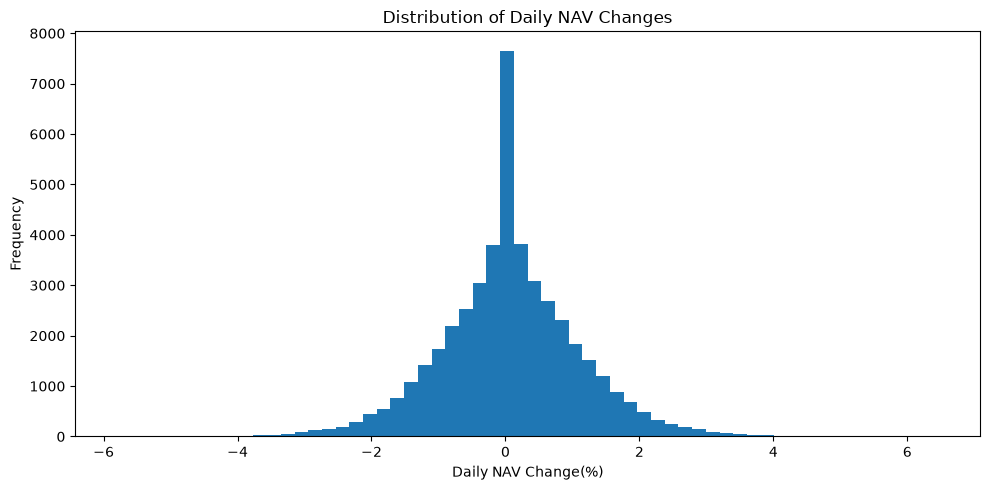

In [ ]:
import matplotlib.pyplot as plt
daily_changes = nav_movements["daily_change_pct"].dropna()
plt.figure(figsize=(10, 5))
plt.hist(daily_changes, bins=60)
plt.title("Distribution of Daily NAV Changes")
plt.xlabel("Daily NAV Change(%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

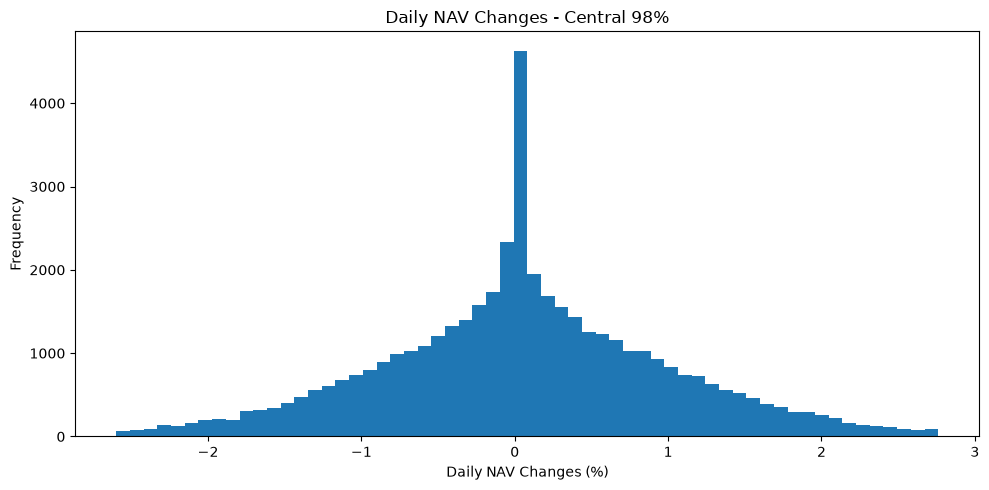

In [ ]:
lower = daily_changes.quantile(0.01)
upper = daily_changes.quantile(0.99)
plt.figure(figsize=(10, 5))
plt.hist(daily_changes, bins=60, range=(lower, upper))
plt.title("Daily NAV Changes - Central 98%")
plt.xlabel("Daily NAV Changes (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [ ]:
near_zero = daily_changes.abs() < 0.01
print("Daily changes within ±0.01%:", near_zero.sum())
print("Percentage  of all daily changes:", round(near_zero.mean() * 100, 2), "%")
print("Exactly zero daily changes:", (daily_changes == 0).sum())

Daily changes within ±0.01%: 1050
Percentage  of all daily changes: 2.28 %
Exactly zero daily changes: 6


In [ ]:
fund_volatility = (nav_movements.groupby("amfi_code")["daily_change_pct"]
                   .agg(mean_daily_changes="mean",
                        daily_volatility="std",
                        min_daily_change="min",
                        max_daily_change="max")
                        .reset_index())
fund_volatility["daily_volatility"] = (fund_volatility["daily_volatility"].round(3))
display(fund_volatility.sort_values("daily_volatility", ascending=False).head(10))

,amfi_code,mean_daily_changes,daily_volatility,min_daily_change,max_daily_change
4,101207,0.042445,1.625,-5.184659,5.485085
11,118634,0.070711,1.590,-5.810201,5.930431
21,119598,0.120102,1.584,-4.518049,6.471309
17,119095,0.018237,1.579,-4.836706,4.310951
22,119599,0.020132,1.572,-4.542895,5.331971
39,149324,0.119417,1.565,-4.887007,4.848951
16,119094,0.102670,1.223,-4.075478,4.159058
25,120505,0.116132,1.215,-3.841821,4.081204
2,100033,0.107980,1.193,-4.423757,4.195391
33,125498,0.047686,1.156,-4.521750,3.619338


In [ ]:
fund_details = datasets["01_fund_master"][["amfi_code", "scheme_name", "category", "sub_category", "plan"]].copy()
fund_details["amfi_code"] = fund_details["amfi_code"].astype("Int64")
fund_volatility["amfi_code"] = fund_volatility["amfi_code"].astype("Int64")
volatility_with_names = fund_volatility.merge(fund_details, on="amfi_code", how="left", validate="one_to_one")
display(volatility_with_names.sort_values("daily_volatility", ascending=False).head(10))

,amfi_code,mean_daily_changes,daily_volatility,min_daily_change,max_daily_change,scheme_name,category,sub_category,plan
4,101207,0.042445,1.625,-5.184659,5.485085,ABSL Small Cap Fund - Regular - Growth,Equity,Small Cap,Regular
11,118634,0.070711,1.590,-5.810201,5.930431,Nippon India Small Cap Fund - Regular - Growth,Equity,Small Cap,Regular
21,119598,0.120102,1.584,-4.518049,6.471309,SBI Small Cap Fund - Regular Plan - Growth,Equity,Small Cap,Regular
17,119095,0.018237,1.579,-4.836706,4.310951,Axis Small Cap Fund - Regular - Growth,Equity,Small Cap,Regular
22,119599,0.020132,1.572,-4.542895,5.331971,SBI Small Cap Fund - Direct Plan - Growth,Equity,Small Cap,Direct
39,149324,0.119417,1.565,-4.887007,4.848951,DSP Small Cap Fund - Regular - Growth,Equity,Small Cap,Regular
16,119094,0.102670,1.223,-4.075478,4.159058,Axis Midcap Fund - Regular - Growth,Equity,Mid Cap,Regular
25,120505,0.116132,1.215,-3.841821,4.081204,ICICI Pru Midcap Fund - Regular - Growth,Equity,Mid Cap,Regular
2,100033,0.107980,1.193,-4.423757,4.195391,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,Mid Cap,Regular
33,125498,0.047686,1.156,-4.521750,3.619338,HDFC Mid-Cap Opportunities Fund - Direct - Growth,Equity,Mid Cap,Direct


In [ ]:
category_volatility = (volatility_with_names.groupby("category")
                       .agg(
                           funds=("amfi_code", "count"),
                           average_daily_volatility=("daily_volatility", "mean"),
                           median_daily_volatility=("daily_volatility", "median")
                       )
                       .sort_values("average_daily_volatility",
                                    ascending=False).round(3))
display(category_volatility)

,funds,average_daily_volatility,median_daily_volatility
category,,,
Equity,34,1.083,0.966
Debt,6,0.140,0.139


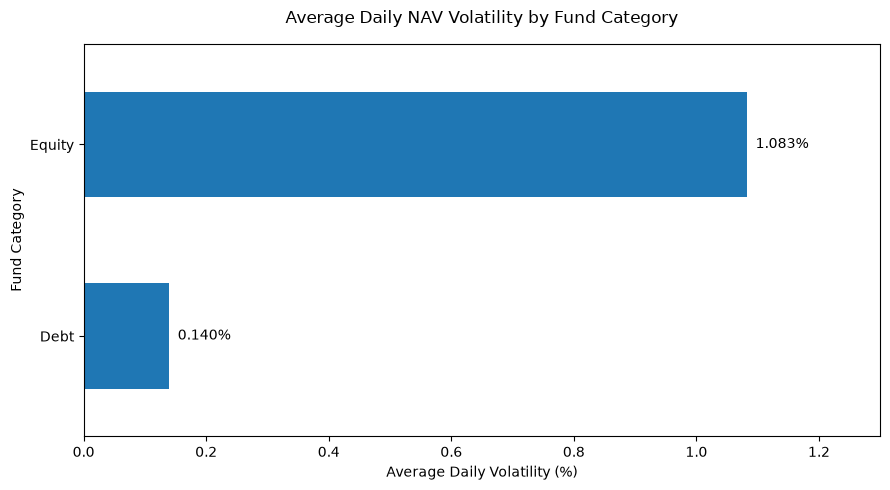

In [ ]:
import matplotlib.pyplot as plt

plot_data = category_volatility["average_daily_volatility"].sort_values()

fig, ax = plt.subplots(figsize=(9, 5))

plot_data.plot(kind="barh", ax=ax, width=0.55)

ax.set_title("Average Daily NAV Volatility by Fund Category", pad=15)
ax.set_xlabel("Average Daily Volatility (%)")
ax.set_ylabel("Fund Category")
ax.set_xlim(0, plot_data.max() * 1.20)
for bar in ax.patches:
    value = bar.get_width()
    ax.annotate(
        f"{value:.3f}%",
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        ha="left"
    )
plt.tight_layout()
plt.show()

### Finding: NAV Volatility by Fund Category

Equity funds in the dataset have an average daily NAV volatility of **1.083%**, compared with **0.140%** for debt funds. This indicates that the sampled equity funds experienced substantially larger day-to-day NAV fluctuations over the observation period.

**Limitation:** The comparison covers 34 equity funds and only 6 debt funds. Daily NAV volatility measures fluctuations, not total investment risk, and the result should not be generalized to all mutual funds.

In [ ]:
nav_coverage = (
    nav_df.groupby("amfi_code")
    .agg(
        observation_count=("date", "count"),
        first_nav_date=("date", "min"),
        last_nav_date=("date", "max"),
        distinct_dates=("date", "nunique")
    )
    .reset_index()
)

display(nav_coverage.describe(include="all"))

,amfi_code,observation_count,first_nav_date,last_nav_date,distinct_dates
count,40.000000,40.0,40,40,40.0
mean,120247.000000,1150.0,2022-01-03 00:00:00,2026-05-29 00:00:00,1150.0
min,100016.000000,1150.0,2022-01-03 00:00:00,2026-05-29 00:00:00,1150.0
25%,118632.750000,1150.0,2022-01-03 00:00:00,2026-05-29 00:00:00,1150.0
50%,119551.500000,1150.0,2022-01-03 00:00:00,2026-05-29 00:00:00,1150.0
75%,120842.250000,1150.0,2022-01-03 00:00:00,2026-05-29 00:00:00,1150.0
max,149324.000000,1150.0,2022-01-03 00:00:00,2026-05-29 00:00:00,1150.0
std,14534.998667,0.0,NaN,NaN,0.0


In [ ]:
from pathlib import Path

raw_benchmark_path = RAW_DATA_DIR / "10_benchmark_indices.csv"

raw_benchmark = pd.read_csv(raw_benchmark_path)

raw_benchmark["date"] = pd.to_datetime(raw_benchmark["date"])

display(
    raw_benchmark.loc[
        (raw_benchmark["index_name"] == "BSE_SMALLCAP")
        & raw_benchmark["date"].between(
            pd.Timestamp("2023-09-13"),
            pd.Timestamp("2023-09-18")
        ),
        ["date", "index_name", "close_value"]
    ].sort_values("date")
)

,date,index_name,close_value
3892,2023-09-13,BSE_SMALLCAP,28822.07
3893,2023-09-14,BSE_SMALLCAP,28635.46
3894,2023-09-15,BSE_SMALLCAP,29601.16
3895,2023-09-18,BSE_SMALLCAP,29673.85


In [ ]:
benchmark_returns_check = (
    raw_benchmark.loc[
        raw_benchmark["index_name"] == "BSE_SMALLCAP"
    ]
    .sort_values("date")
    .copy()
)

benchmark_returns_check["daily_return_pct"] = (
    benchmark_returns_check["close_value"]
    .pct_change() * 100
)

display(
    benchmark_returns_check.loc[
        benchmark_returns_check["date"].between(
            pd.Timestamp("2023-09-01"),
            pd.Timestamp("2023-09-29")
        ),
        ["date", "close_value", "daily_return_pct"]
    ].round(3)
)

print("\nLargest absolute daily benchmark returns:")
display(
    benchmark_returns_check.assign(
        abs_return=benchmark_returns_check["daily_return_pct"].abs()
    )
    .nlargest(10, "abs_return")
    [["date", "close_value", "daily_return_pct"]]
    .round(3)
)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\2156652349.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,date,close_value,daily_return_pct
3884,2023-09-01,30227.95,-1.111
3885,2023-09-04,29985.37,-0.803
3886,2023-09-05,29968.13,-0.057
3887,2023-09-06,29762.89,-0.685
3888,2023-09-07,29106.84,-2.204
3889,2023-09-08,28878.35,-0.785
3890,2023-09-11,29059.36,0.627
3891,2023-09-12,28895.48,-0.564
3892,2023-09-13,28822.07,-0.254
3893,2023-09-14,28635.46,-0.647



Largest absolute daily benchmark returns:


C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\2156652349.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,date,close_value,daily_return_pct
3668,2022-11-03,27752.52,4.185
4429,2025-10-03,58518.22,-3.972
3454,2022-01-07,26316.86,-3.873
3587,2022-07-13,26937.51,3.854
3638,2022-09-22,25841.96,-3.803
3709,2022-12-30,26829.94,-3.731
3672,2022-11-09,27622.31,-3.724
4185,2024-10-28,32098.90,3.721
3698,2022-12-15,26985.68,-3.691
3703,2022-12-22,27974.84,3.625


In [ ]:
valid_benchmark_returns = (
    benchmark_returns_check["daily_return_pct"].dropna()
)

for threshold in [2, 3, 4, 5]:
    count = (
        valid_benchmark_returns.abs() > threshold
    ).sum()

    print(
        f"Daily benchmark changes exceeding "
        f"{threshold}%: {count}"
    )

print("\nBenchmark daily return summary:")
display(
    valid_benchmark_returns.describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    ).round(3)
)

Daily benchmark changes exceeding 2%: 187
Daily benchmark changes exceeding 3%: 36
Daily benchmark changes exceeding 4%: 1
Daily benchmark changes exceeding 5%: 0

Benchmark daily return summary:


count    1149.000
mean        0.104
std         1.395
min        -3.972
1%         -3.042
5%         -2.195
50%         0.081
95%         2.483
99%         3.316
max         4.185
Name: daily_return_pct, dtype: float64

### Finding: Benchmark Return Validation

The BSE_SMALLCAP series contains 1,149 daily returns, with a mean daily return of 0.104% and a standard deviation of 1.395%. Across the available observations, 187 daily changes exceeded 2% in absolute magnitude, 36 exceeded 3%, and one exceeded 4%.

The 15 September 2023 benchmark return of 3.372% was independently recalculated from the supplied closing values and matched the return calculated in the notebook. The same closing values were found in the original CSV, confirming that the movement was not introduced during data processing.

**Limitation:** The source and methodology of the benchmark series have not yet been independently verified. The fund master specifies BSE 250 SmallCap TRI, while the available series is labelled BSE_SMALLCAP. The comparison is therefore provisional and should not be interpreted as a definitive measure of benchmark-relative performance.

### Benchmark Mapping Coverage

In [ ]:
fund_benchmarks = (
    fund_master_df["benchmark"]
    .value_counts()
    .rename_axis("fund_master_benchmark")
    .reset_index(name="fund_count")
)

display(fund_benchmarks)

,fund_master_benchmark,fund_count
0,NIFTY 100 TRI,14
1,BSE 250 SmallCap TRI,6
2,NIFTY Midcap 150 TRI,6
3,NIFTY 500 TRI,4
4,CRISIL Liquid Fund AI Index,3
5,CRISIL Dynamic Gilt Index,2
6,NIFTY 50 TRI,2
7,CRISIL Short Term Bond Index,1
8,NIFTY Midcap 50 TRI,1
9,NIFTY Large Midcap 250 TRI,1


In [ ]:
benchmark_mapping = pd.DataFrame([
    ("NIFTY 100 TRI", "NIFTY100", "Candidate — verify TRI methodology"),
    ("BSE 250 SmallCap TRI", "BSE_SMALLCAP", "Candidate — verify TRI methodology"),
    ("NIFTY Midcap 150 TRI", "NIFTY_MIDCAP150", "Candidate — verify TRI methodology"),
    ("NIFTY 500 TRI", "NIFTY500", "Candidate — verify TRI methodology"),
    ("CRISIL Liquid Fund All Index", "CRISIL_LIQUID", "Candidate — verify methodology"),
    ("CRISIL Dynamic Gilt Index", "CRISIL_GILT", "Candidate — verify methodology"),
    ("NIFTY 50 TRI", "NIFTY50", "Candidate — verify TRI methodology"),
    ("CRISIL Short Term Bond Index", None, "Unresolved — no matching series"),
    ("NIFTY Midcap 50 TRI", None, "Unresolved — no matching series"),
    ("NIFTY Large Midcap 250 TRI", None, "Unresolved — no matching series"),
], columns=[
    "fund_master_benchmark",
    "available_index_name",
    "mapping_status"
])

display(benchmark_mapping)

,fund_master_benchmark,available_index_name,mapping_status
0,NIFTY 100 TRI,NIFTY100,Candidate — verify TRI methodology
1,BSE 250 SmallCap TRI,BSE_SMALLCAP,Candidate — verify TRI methodology
2,NIFTY Midcap 150 TRI,NIFTY_MIDCAP150,Candidate — verify TRI methodology
3,NIFTY 500 TRI,NIFTY500,Candidate — verify TRI methodology
4,CRISIL Liquid Fund All Index,CRISIL_LIQUID,Candidate — verify methodology
5,CRISIL Dynamic Gilt Index,CRISIL_GILT,Candidate — verify methodology
6,NIFTY 50 TRI,NIFTY50,Candidate — verify TRI methodology
7,CRISIL Short Term Bond Index,NaN,Unresolved — no matching series
8,NIFTY Midcap 50 TRI,NaN,Unresolved — no matching series
9,NIFTY Large Midcap 250 TRI,NaN,Unresolved — no matching series


In [ ]:
benchmark_coverage = benchmark_mapping.merge(
    fund_benchmarks,
    on="fund_master_benchmark",
    how="left",
    validate="one_to_one"
)

benchmark_coverage["mapping_group"] = benchmark_coverage[
    "available_index_name"
].notna().map({
    True: "Candidate mapping",
    False: "Unresolved"
})

coverage_summary = (
    benchmark_coverage
    .groupby("mapping_group", as_index=False)
    .agg(
        benchmark_count=("fund_master_benchmark", "count"),
        fund_count=("fund_count", "sum")
    )
)

display(coverage_summary)

,mapping_group,benchmark_count,fund_count
0,Candidate mapping,7,34.0
1,Unresolved,3,3.0


### Finding: Benchmark Mapping Coverage

Of the 10 distinct benchmark labels in the fund master, 7 have candidate matches among the available benchmark index series, covering 34 funds. The remaining 3 benchmark labels, covering 6 funds, have no corresponding series in the supplied dataset.

**Limitation:** Candidate matches are based on index labels and have not yet been verified for methodology equivalence, including total-return versus price-return conventions. Unresolved benchmarks are excluded from benchmark-relative comparisons until suitable series are identified.

### NAV Coverage and Data Completeness

### Finding: NAV Coverage and Completeness

All 40 funds have 1,150 NAV observations covering the period from 3 January 2022 to 29 May 2026. Each fund has 1,150 distinct dates, indicating consistent observation counts and date coverage across the dataset.

**Limitation:** Consistent coverage does not establish the accuracy of the supplied NAV values or guarantee that every calendar day is represented. NAV observations generally follow the applicable market and valuation calendar.

### NAV Observation Gaps

In [ ]:
nav_coverage = (
    nav_df.groupby("amfi_code")
    .agg(
        observation_count=("date", "count"),
        first_nav_date=("date", "min"),
        last_nav_date=("date", "max"),
        distinct_dates=("date", "nunique")
    )
    .reset_index()
)

display(nav_coverage.describe(include="all"))

,amfi_code,observation_count,first_nav_date,last_nav_date,distinct_dates
count,40.000000,40.0,40,40,40.0
mean,120247.000000,1150.0,2022-01-03 00:00:00,2026-05-29 00:00:00,1150.0
min,100016.000000,1150.0,2022-01-03 00:00:00,2026-05-29 00:00:00,1150.0
25%,118632.750000,1150.0,2022-01-03 00:00:00,2026-05-29 00:00:00,1150.0
50%,119551.500000,1150.0,2022-01-03 00:00:00,2026-05-29 00:00:00,1150.0
75%,120842.250000,1150.0,2022-01-03 00:00:00,2026-05-29 00:00:00,1150.0
max,149324.000000,1150.0,2022-01-03 00:00:00,2026-05-29 00:00:00,1150.0
std,14534.998667,0.0,NaN,NaN,0.0


In [ ]:
nav_sorted = nav_df.sort_values(["amfi_code", "date"]).copy()

nav_sorted["date_gap_days"] = (
    nav_sorted.groupby("amfi_code")["date"]
    .diff()
    .dt.days
)

gap_summary = (
    nav_sorted.groupby("amfi_code")["date_gap_days"]
    .agg(
        max_gap_days="max",
        median_gap_days="median",
        gaps_over_4_days=lambda gaps: (gaps > 4).sum()
    )
    .reset_index()
)

display(gap_summary.describe().round(2))

,amfi_code,max_gap_days,median_gap_days,gaps_over_4_days
count,40.00,40.0,40.0,40.0
mean,120247.00,3.0,1.0,0.0
std,14535.00,0.0,0.0,0.0
min,100016.00,3.0,1.0,0.0
25%,118632.75,3.0,1.0,0.0
50%,119551.50,3.0,1.0,0.0
75%,120842.25,3.0,1.0,0.0
max,149324.00,3.0,1.0,0.0


### Finding: NAV Observation Gaps

Across all 40 funds, the median interval between consecutive NAV observations is 1 calendar day, and the maximum interval is 3 calendar days. No fund has an interval exceeding 4 calendar days.

**Limitation:** These results describe calendar-day gaps in the supplied dataset. They do not independently establish whether every observation is complete or accurate relative to an official NAV publication calendar.

### NAV Volatility by Fund Category

In [ ]:
nav_with_category = nav_movements.merge(
    fund_master_df[["amfi_code", "category"]],
    on="amfi_code",
    how="left",
    validate="many_to_one"
)

category_volatility = (
    nav_with_category.groupby("category")["daily_change_pct"]
    .agg(
        fund_observations="count",
        mean_daily_change="mean",
        daily_volatility="std"
    )
    .reset_index()
    .sort_values("daily_volatility", ascending=False)
)

display(category_volatility.round(3))

,category,fund_observations,mean_daily_change,daily_volatility
1,Equity,39066,0.070,1.114
0,Debt,6894,0.023,0.177


In [ ]:
print("nav_df columns:")
print(nav_df.columns.tolist())

print("\nnav_movements columns:")
print(nav_movements.columns.tolist())

nav_df columns:
['amfi_code', 'date', 'nav']

nav_movements columns:
['amfi_code', 'date', 'nav', 'daily_change_pct']


### Finding: Daily NAV Changes by Category

Across the available observations, equity funds have a mean daily NAV change of 0.070% and daily volatility of 1.114%. Debt funds have a mean daily NAV change of 0.023% and daily volatility of 0.177%. In this sample, equity funds exhibit approximately 6.3 times the daily volatility of debt funds.

**Limitation:** These are pooled daily observations from 34 equity funds and 6 debt funds. The results describe this dataset and should not be generalized to all mutual funds or interpreted as a forecast of future returns.

### Fund-Level NAV Volatility

In [ ]:
fund_volatility = (
    nav_movements.groupby("amfi_code")["daily_change_pct"]
    .agg(
        mean_daily_change="mean",
        daily_volatility="std",
        min_daily_change="min",
        max_daily_change="max"
    )
    .reset_index()
)

fund_volatility = fund_volatility.merge(
    fund_master_df[
        ["amfi_code", "scheme_name", "category", "sub_category"]
    ],
    on="amfi_code",
    how="left",
    validate="one_to_one"
)

display(
    fund_volatility
    .sort_values("daily_volatility", ascending=False)
    .head(10)
    .round(3)
)

,amfi_code,mean_daily_change,daily_volatility,min_daily_change,max_daily_change,scheme_name,category,sub_category
4,101207,0.042,1.625,-5.185,5.485,ABSL Small Cap Fund - Regular - Growth,Equity,Small Cap
11,118634,0.071,1.590,-5.810,5.930,Nippon India Small Cap Fund - Regular - Growth,Equity,Small Cap
21,119598,0.120,1.584,-4.518,6.471,SBI Small Cap Fund - Regular Plan - Growth,Equity,Small Cap
17,119095,0.018,1.579,-4.837,4.311,Axis Small Cap Fund - Regular - Growth,Equity,Small Cap
22,119599,0.020,1.572,-4.543,5.332,SBI Small Cap Fund - Direct Plan - Growth,Equity,Small Cap
39,149324,0.119,1.565,-4.887,4.849,DSP Small Cap Fund - Regular - Growth,Equity,Small Cap
16,119094,0.103,1.223,-4.075,4.159,Axis Midcap Fund - Regular - Growth,Equity,Mid Cap
25,120505,0.116,1.215,-3.842,4.081,ICICI Pru Midcap Fund - Regular - Growth,Equity,Mid Cap
2,100033,0.108,1.193,-4.424,4.195,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,Mid Cap
33,125498,0.048,1.156,-4.522,3.619,HDFC Mid-Cap Opportunities Fund - Direct - Growth,Equity,Mid Cap


### Finding: Fund-Level NAV Volatility

The 10 funds with the highest daily NAV volatility consist of six small-cap funds and four mid-cap funds. ABSL Small Cap Fund – Regular – Growth has the highest daily volatility at 1.625%, followed by Nippon India Small Cap Fund – Regular – Growth at 1.590%.

The largest daily NAV movement among these funds was a rise of 6.471% for SBI Small Cap Fund – Regular Plan – Growth, while the largest decline was 5.810% for Nippon India Small Cap Fund – Regular – Growth.

**Limitation:** Daily volatility measures the variability of daily NAV percentage changes in the supplied dataset. It does not, by itself, measure total investment risk or indicate future performance. These rankings are descriptive and should not be interpreted as investment recommendations.

### NAV Volatility by Fund Subcategory

In [ ]:
subcategory_volatility = (
    nav_with_category
    .merge(
        fund_master_df[["amfi_code", "sub_category"]],
        on="amfi_code",
        how="left",
        validate="many_to_one"
    )
    .groupby("sub_category")["daily_change_pct"]
    .agg(
        observation_count="count",
        mean_daily_change="mean",
        daily_volatility="std"
    )
    .reset_index()
    .sort_values("daily_volatility", ascending=False)
)

display(subcategory_volatility.round(3))

,sub_category,observation_count,mean_daily_change,daily_volatility
10,Small Cap,6894,0.065,1.586
8,Mid Cap,8043,0.075,1.169
0,ELSS,1149,0.112,1.113
1,Flexi Cap,2298,0.086,0.997
5,Large & Mid Cap,1149,0.083,0.972
11,Value,1149,0.065,0.959
6,Large Cap,16086,0.065,0.890
4,Index/ETF,1149,0.060,0.818
3,Index,1149,0.067,0.809
2,Gilt,2298,0.021,0.250


### Finding: NAV Volatility by Fund Subcategory

Small Cap funds have the highest daily NAV volatility at 1.586%, followed by Mid Cap funds at 1.169% and ELSS funds at 1.113%. Liquid funds have the lowest observed daily volatility at 0.032%, followed by Short Duration funds at 0.246% and Gilt funds at 0.250%.

In this dataset, Small Cap daily volatility is approximately 49.6 times that of Liquid funds. This pattern is consistent with the earlier fund-level analysis, where six of the ten most volatile funds were Small Cap funds.

**Limitation:** The results use pooled daily NAV changes, and the number of funds and observations differs across subcategories. The comparison is descriptive, applies only to the supplied dataset, and does not establish future performance or total investment risk.

### Cumulative NAV Returns by Fund

In [ ]:
fund_cumulative_returns = (
    nav_df.sort_values(["amfi_code", "date"])
    .groupby("amfi_code")
    .agg(
        first_date=("date", "first"),
        last_date=("date", "last"),
        starting_nav=("nav", "first"),
        ending_nav=("nav", "last"),
        observation_count=("nav", "count")
    )
    .reset_index()
)

fund_cumulative_returns["cumulative_return_pct"] = (
    (
        fund_cumulative_returns["ending_nav"]
        / fund_cumulative_returns["starting_nav"]
    ) - 1
) * 100

fund_cumulative_returns = fund_cumulative_returns.merge(
    fund_master_df[
        ["amfi_code", "scheme_name", "category", "sub_category"]
    ],
    on="amfi_code",
    how="left",
    validate="one_to_one"
)

display(
    fund_cumulative_returns
    .sort_values("cumulative_return_pct", ascending=False)
    [[
        "scheme_name",
        "category",
        "sub_category",
        "first_date",
        "last_date",
        "cumulative_return_pct"
    ]]
    .round(2)
)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\995023414.py:41: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,scheme_name,category,sub_category,first_date,last_date,cumulative_return_pct
25,ICICI Pru Midcap Fund - Regular - Growth,Equity,Mid Cap,2022-01-03,2026-05-29,248.68
21,SBI Small Cap Fund - Regular Plan - Growth,Equity,Small Cap,2022-01-03,2026-05-29,244.04
39,DSP Small Cap Fund - Regular - Growth,Equity,Small Cap,2022-01-03,2026-05-29,242.49
36,Mirae Asset Tax Saver Fund - Regular - Growth,Equity,ELSS,2022-01-03,2026-05-29,238.66
34,Mirae Asset Large Cap Fund - Regular - Growth,Equity,Large Cap,2022-01-03,2026-05-29,227.78
30,Kotak Flexicap Fund - Regular - Growth,Equity,Flexi Cap,2022-01-03,2026-05-29,227.05
2,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,Mid Cap,2022-01-03,2026-05-29,218.51
38,DSP Midcap Fund - Regular - Growth,Equity,Mid Cap,2022-01-03,2026-05-29,212.72
16,Axis Midcap Fund - Regular - Growth,Equity,Mid Cap,2022-01-03,2026-05-29,198.46
19,SBI Bluechip Fund - Regular Plan - Growth,Equity,Large Cap,2022-01-03,2026-05-29,174.56


In [ ]:
fund_cumulative_returns.loc[
    fund_cumulative_returns["scheme_name"].str.contains(
        "SBI Small Cap Fund|HDFC Top 100 Fund",
        case=False,
        na=False
    ),
    [
        "amfi_code",
        "scheme_name",
        "starting_nav",
        "ending_nav",
        "first_date",
        "last_date",
        "cumulative_return_pct"
    ]
].sort_values("scheme_name")

,amfi_code,scheme_name,starting_nav,ending_nav,first_date,last_date,cumulative_return_pct
32,125497,HDFC Top 100 Fund - Direct Plan - Growth,560.1443,1204.9571,2022-01-03,2026-05-29,115.115480
0,100016,HDFC Top 100 Fund - Regular Plan - Growth,520.4608,583.6113,2022-01-03,2026-05-29,12.133575
22,119599,SBI Small Cap Fund - Direct Plan - Growth,96.4565,105.4849,2022-01-03,2026-05-29,9.360074
21,119598,SBI Small Cap Fund - Regular Plan - Growth,89.8738,309.2050,2022-01-03,2026-05-29,244.043537


In [ ]:
sbi_small_cap_nav = (
    nav_df[
        nav_df["amfi_code"].isin([119598, 119599])
    ]
    .sort_values(["amfi_code", "date"])
)

for code in [119598, 119599]:
    scheme_name = fund_master_df.loc[
        fund_master_df["amfi_code"] == code,
        "scheme_name"
    ].iloc[0]

    print(f"\nAMFI code: {code} | {scheme_name}")

    scheme_nav = sbi_small_cap_nav[
        sbi_small_cap_nav["amfi_code"] == code
    ]

    display(
        pd.concat([
            scheme_nav.head(5),
            scheme_nav.tail(5)
        ])
    )


AMFI code: 119598 | SBI Small Cap Fund - Regular Plan - Growth


,amfi_code,date,nav
2300,119598,2022-01-03,89.8738
2301,119598,2022-01-04,88.5495
2302,119598,2022-01-05,88.0925
2303,119598,2022-01-06,88.5175
2304,119598,2022-01-07,91.4235
3445,119598,2026-05-25,316.5766
3446,119598,2026-05-26,316.2971
3447,119598,2026-05-27,312.5855
3448,119598,2026-05-28,310.9541
3449,119598,2026-05-29,309.2050



AMFI code: 119599 | SBI Small Cap Fund - Direct Plan - Growth


,amfi_code,date,nav
3450,119599,2022-01-03,96.4565
3451,119599,2022-01-04,94.6512
3452,119599,2022-01-05,94.5436
3453,119599,2022-01-06,93.7944
3454,119599,2022-01-07,89.6438
4595,119599,2026-05-25,100.6688
4596,119599,2026-05-26,100.3172
4597,119599,2026-05-27,102.4676
4598,119599,2026-05-28,103.2405
4599,119599,2026-05-29,105.4849


In [ ]:
sbi_plan_comparison = (
    nav_df[nav_df["amfi_code"].isin([119598, 119599])]
    .sort_values(["amfi_code", "date"])
    .copy()
)

sbi_plan_comparison["daily_return_pct"] = (
    sbi_plan_comparison
    .groupby("amfi_code")["nav"]
    .pct_change() * 100
)

sbi_plan_pivot = sbi_plan_comparison.pivot(
    index="date",
    columns="amfi_code",
    values="daily_return_pct"
).rename(columns={
    119598: "regular_return_pct",
    119599: "direct_return_pct"
})

sbi_plan_pivot["return_difference_pp"] = (
    sbi_plan_pivot["regular_return_pct"]
    - sbi_plan_pivot["direct_return_pct"]
)

display(
    sbi_plan_pivot
    .assign(
        absolute_difference=lambda df:
            df["return_difference_pp"].abs()
    )
    .sort_values("absolute_difference", ascending=False)
    .head(10)
    .round(3)
)

amfi_code,regular_return_pct,direct_return_pct,return_difference_pp,absolute_difference
date,,,,
2022-01-07,3.283,-4.425,7.708,7.708
2024-04-15,6.471,-0.565,7.036,7.036
2023-01-10,-1.470,5.332,-6.802,6.802
2023-03-08,-3.329,3.358,-6.688,6.688
2023-01-27,2.898,-3.498,6.396,6.396
2026-05-21,2.623,-3.278,5.901,5.901
2025-09-11,1.953,-3.774,5.727,5.727
2022-07-20,-1.929,3.785,-5.714,5.714
2023-12-05,4.423,-1.219,5.643,5.643


In [ ]:
sbi_return_differences = sbi_plan_pivot[
    ["regular_return_pct", "direct_return_pct", "return_difference_pp"]
].dropna()

print("Paired daily return observations:", len(sbi_return_differences))

for threshold in [1, 2, 3, 5]:
    count = (
        sbi_return_differences["return_difference_pp"].abs()
        > threshold
    ).sum()

    print(
        f"Days with absolute return difference > {threshold} percentage point(s): "
        f"{count}"
    )

print(
    "\nCorrelation between daily returns:",
    round(
        sbi_return_differences["regular_return_pct"].corr(
            sbi_return_differences["direct_return_pct"]
        ),
        3
    )
)

Paired daily return observations: 1149
Days with absolute return difference > 1 percentage point(s): 730
Days with absolute return difference > 2 percentage point(s): 436
Days with absolute return difference > 3 percentage point(s): 210
Days with absolute return difference > 5 percentage point(s): 25

Correlation between daily returns: 0.018


In [ ]:
check_date = pd.Timestamp("2022-01-07")
previous_date = pd.Timestamp("2022-01-06")

for code in [119598, 119599]:
    scheme_name = fund_master_df.loc[
        fund_master_df["amfi_code"] == code,
        "scheme_name"
    ].iloc[0]

    print(f"\n{code} — {scheme_name}")

    display(
        nav_df[
            (nav_df["amfi_code"] == code)
            & nav_df["date"].isin([previous_date, check_date])
        ].sort_values("date")
    )


119598 — SBI Small Cap Fund - Regular Plan - Growth


,amfi_code,date,nav
2303,119598,2022-01-06,88.5175
2304,119598,2022-01-07,91.4235



119599 — SBI Small Cap Fund - Direct Plan - Growth


,amfi_code,date,nav
3453,119599,2022-01-06,93.7944
3454,119599,2022-01-07,89.6438


In [ ]:
from pathlib import Path

current_dir = Path.cwd()
print("Notebook working directory:", current_dir)

project_root = next(
    (
        parent
        for parent in [current_dir, *current_dir.parents]
        if (parent / "data" / "raw" / "02_nav_history.csv").exists()
    ),
    None
)

if project_root is None:
    print("Could not find the raw NAV CSV from the current directory.")
else:
    raw_nav_path = project_root / "data" / "raw" / "02_nav_history.csv"
    print("Project root:", project_root)
    print("Raw NAV file found:", raw_nav_path)

Notebook working directory: c:\Users\ASUS\Desktop\potfolio\Mutual_Fund_Project_V2\notebooks
Project root: c:\Users\ASUS\Desktop\potfolio\Mutual_Fund_Project_V2
Raw NAV file found: c:\Users\ASUS\Desktop\potfolio\Mutual_Fund_Project_V2\data\raw\02_nav_history.csv


In [ ]:
raw_nav_check = pd.read_csv(
    raw_nav_path,
    dtype={"amfi_code": str},
    parse_dates=["date"]
)

display(
    raw_nav_check[
        raw_nav_check["amfi_code"].isin(["119598", "119599"])
        & raw_nav_check["date"].isin([
            pd.Timestamp("2022-01-06"),
            pd.Timestamp("2022-01-07")
        ])
    ].sort_values(["amfi_code", "date"])
)

,amfi_code,date,nav
2303,119598,2022-01-06,88.5175
2304,119598,2022-01-07,91.4235
3453,119599,2022-01-06,93.7944
3454,119599,2022-01-07,89.6438


### Finding: SBI Small Cap NAV Series Discrepancy

A comparison of the SBI Small Cap Fund Regular and Direct Growth plan NAV series identified substantial differences in daily returns. Across 1,149 paired daily return observations, the Pearson correlation between the two series was 0.018. Absolute daily return differences exceeded 1 percentage point on 730 days, 2 percentage points on 436 days, 3 percentage points on 210 days, and 5 percentage points on 25 days.

On 7 January 2022, the Regular plan NAV increased from 88.5175 to 91.4235 (+3.283%), while the Direct plan NAV decreased from 93.7944 to 89.6438 (−4.425%). These exact values were verified in the original NAV CSV, confirming that the discrepancy was present in the source file and was not introduced by the notebook calculation.

**Limitation:** The underlying cause has not been established. The discrepancy may reflect a source-data issue or a scheme-mapping problem, but neither explanation has been confirmed. Cumulative-return rankings involving these series should therefore be treated as provisional until the data is independently verified.

### Regular vs Direct Plan NAV Consistency

In [ ]:
# Identify schemes with both Regular and Direct plans
plan_check = fund_master_df[
    fund_master_df["scheme_name"].str.contains(
        r"\b(Regular|Direct)\b",
        case=False,
        na=False,
        regex=True
    )
].copy()

plan_check["plan_type"] = plan_check["scheme_name"].str.extract(
    r"\b(Regular|Direct)\b",
    flags=0,
    expand=False
).str.lower()

# Compare only codes with one Regular and one Direct plan
plan_pairs = (
    plan_check.groupby(["fund_house", "sub_category"])
    .filter(lambda group: {"regular", "direct"}.issubset(set(group["plan_type"])))
)

display(
    plan_check[
        ["amfi_code", "fund_house", "scheme_name", "sub_category", "plan_type"]
    ].sort_values(["fund_house", "sub_category", "plan_type"])
)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\2474938545.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  fund_master_df["scheme_name"].str.contains(


,amfi_code,fund_house,scheme_name,sub_category,plan_type
28,101206,Aditya Birla Sun Life MF,ABSL Frontline Equity Fund - Regular - Growth,Large Cap,regular
30,101208,Aditya Birla Sun Life MF,ABSL Liquid Fund - Regular - Growth,Liquid,regular
29,101207,Aditya Birla Sun Life MF,ABSL Small Cap Fund - Regular - Growth,Small Cap,regular
25,119093,Axis Mutual Fund,Axis Bluechip Fund - Direct - Growth,Large Cap,direct
24,119092,Axis Mutual Fund,Axis Bluechip Fund - Regular - Growth,Large Cap,regular
26,119094,Axis Mutual Fund,Axis Midcap Fund - Regular - Growth,Mid Cap,regular
27,119095,Axis Mutual Fund,Axis Small Cap Fund - Regular - Growth,Small Cap,regular
37,149322,DSP Mutual Fund,DSP Top 100 Equity Fund - Regular - Growth,Large Cap,regular
38,149323,DSP Mutual Fund,DSP Midcap Fund - Regular - Growth,Mid Cap,regular
39,149324,DSP Mutual Fund,DSP Small Cap Fund - Regular - Growth,Small Cap,regular


In [ ]:
# Display the relevant fund master columns without truncating scheme names
display(
    fund_master_df[
        ["amfi_code", "scheme_name", "sub_category"]
    ]
    .sort_values("scheme_name")
    .to_string(index=False)
)

' amfi_code                                           scheme_name    sub_category\n    101206         ABSL Frontline Equity Fund - Regular - Growth       Large Cap\n    101208                   ABSL Liquid Fund - Regular - Growth          Liquid\n    101207                ABSL Small Cap Fund - Regular - Growth       Small Cap\n    119093                  Axis Bluechip Fund - Direct - Growth       Large Cap\n    119092                 Axis Bluechip Fund - Regular - Growth       Large Cap\n    119094                   Axis Midcap Fund - Regular - Growth         Mid Cap\n    119095                Axis Small Cap Fund - Regular - Growth       Small Cap\n    149323                    DSP Midcap Fund - Regular - Growth         Mid Cap\n    149324                 DSP Small Cap Fund - Regular - Growth       Small Cap\n    149322            DSP Top 100 Equity Fund - Regular - Growth       Large Cap\n    125498     HDFC Mid-Cap Opportunities Fund - Direct - Growth         Mid Cap\n    100033    H

In [ ]:
# Explicit pairs based on the fund master scheme names
plan_pairs = [
    ("Axis Bluechip Fund", 119092, 119093),
    ("HDFC Mid-Cap Opportunities Fund", 100033, 125498),
    ("HDFC Top 100 Fund", 100016, 125497),
    ("ICICI Pru Bluechip Fund", 120503, 120504),
    ("Nippon India Large Cap Fund", 118632, 118633),
    ("SBI Bluechip Fund", 119551, 119552),
    ("SBI Small Cap Fund", 119598, 119599),
]

pair_results = []

for scheme, regular_code, direct_code in plan_pairs:
    pair_data = nav_df[
        nav_df["amfi_code"].isin([regular_code, direct_code])
    ].copy()

    pair_data = pair_data.sort_values(["amfi_code", "date"])
    pair_data["daily_return_pct"] = (
        pair_data.groupby("amfi_code")["nav"].pct_change() * 100
    )

    paired_returns = pair_data.pivot(
        index="date",
        columns="amfi_code",
        values="daily_return_pct"
    ).dropna()

    regular_returns = paired_returns[regular_code]
    direct_returns = paired_returns[direct_code]
    differences = (regular_returns - direct_returns).abs()

    pair_results.append({
        "scheme": scheme,
        "paired_days": len(paired_returns),
        "return_correlation": regular_returns.corr(direct_returns),
        "days_diff_over_1pp": (differences > 1).sum(),
        "days_diff_over_3pp": (differences > 3).sum(),
        "max_abs_difference_pp": differences.max()
    })

pair_comparison = pd.DataFrame(pair_results)

display(
    pair_comparison
    .sort_values("return_correlation")
    .round(3)
)

,scheme,paired_days,return_correlation,days_diff_over_1pp,days_diff_over_3pp,max_abs_difference_pp
3,ICICI Pru Bluechip Fund,1149,-0.014,495,18,4.664
1,HDFC Mid-Cap Opportunities Fund,1149,-0.012,633,77,5.516
5,SBI Bluechip Fund,1149,-0.007,470,18,3.875
0,Axis Bluechip Fund,1149,-0.003,468,14,4.249
4,Nippon India Large Cap Fund,1149,0.000,491,19,4.448
6,SBI Small Cap Fund,1149,0.018,730,210,7.708
2,HDFC Top 100 Fund,1149,0.047,496,16,4.381


In [ ]:
hdfc_codes = ["100016", "125497"]

raw_hdfc = raw_nav_check[
    raw_nav_check["amfi_code"].isin(hdfc_codes)
].copy()

hdfc_returns = (
    raw_hdfc.sort_values(["amfi_code", "date"])
    .assign(
        daily_return_pct=lambda df:
            df.groupby("amfi_code")["nav"].pct_change() * 100
    )
)

hdfc_pivot = hdfc_returns.pivot(
    index="date",
    columns="amfi_code",
    values="daily_return_pct"
).dropna()

hdfc_pivot["absolute_difference_pp"] = (
    hdfc_pivot["100016"] - hdfc_pivot["125497"]
).abs()

worst_date = hdfc_pivot["absolute_difference_pp"].idxmax()

print("Date with largest difference:", worst_date)
display(
    raw_hdfc[
        raw_hdfc["date"].isin([
            worst_date - pd.Timedelta(days=1),
            worst_date
        ])
    ].sort_values(["amfi_code", "date"])
)

Date with largest difference: 2022-03-08 00:00:00


,amfi_code,date,nav
5795,100016,2022-03-07,504.4110
5796,100016,2022-03-08,518.6513
6945,125497,2022-03-07,553.8435
6946,125497,2022-03-08,545.2170


### Finding: Regular vs Direct NAV Consistency Check

A comparison of seven Regular and Direct plan pairs identified near-zero daily return correlations across all pairs, ranging from −0.014 to 0.047 over 1,149 paired daily return observations.

The discrepancy was not limited to SBI Small Cap Fund. For HDFC Top 100 Fund, the Regular plan NAV increased from 504.4110 to 518.6513 on 8 March 2022, while the Direct plan NAV decreased from 553.8435 to 545.2170. The values were verified against the original NAV CSV, confirming that this discrepancy was present in the source data.

**Limitation:** These checks identify inconsistencies in the supplied NAV series but do not establish their cause. The source data and scheme-code mappings require independent verification before cumulative-return rankings or comparisons between Regular and Direct plans can be considered reliable.

In [ ]:
# Summarize the NAV history available for each AMFI code
nav_code_summary = (
    nav_df.groupby("amfi_code")
    .agg(
        nav_observations=("nav", "count"),
        first_nav_date=("date", "min"),
        last_nav_date=("date", "max"),
        distinct_dates=("date", "nunique")
    )
    .reset_index()
)

# Compare fund master codes with NAV codes
fund_master_codes = set(fund_master_df["amfi_code"])
nav_codes = set(nav_code_summary["amfi_code"])

print("Fund master codes:", len(fund_master_codes))
print("NAV dataset codes:", len(nav_codes))
print("Codes in fund master but missing from NAV:", sorted(fund_master_codes - nav_codes))
print("Codes in NAV but missing from fund master:", sorted(nav_codes - fund_master_codes))

display(
    fund_master_df[
        ["amfi_code", "scheme_name", "fund_house", "plan", "category"]
    ]
    .merge(
        nav_code_summary,
        on="amfi_code",
        how="left",
        validate="one_to_one"
    )
    .sort_values("amfi_code")
)

Fund master codes: 40
NAV dataset codes: 40
Codes in fund master but missing from NAV: []
Codes in NAV but missing from fund master: []


,amfi_code,scheme_name,fund_house,plan,category,nav_observations,first_nav_date,last_nav_date,distinct_dates
5,100016,HDFC Top 100 Fund - Regular Plan - Growth,HDFC Mutual Fund,Regular,Equity,1150,2022-01-03,2026-05-29,1150
9,100025,HDFC Short Term Debt Fund - Regular - Growth,HDFC Mutual Fund,Regular,Debt,1150,2022-01-03,2026-05-29,1150
7,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,HDFC Mutual Fund,Regular,Equity,1150,2022-01-03,2026-05-29,1150
28,101206,ABSL Frontline Equity Fund - Regular - Growth,Aditya Birla Sun Life MF,Regular,Equity,1150,2022-01-03,2026-05-29,1150
29,101207,ABSL Small Cap Fund - Regular - Growth,Aditya Birla Sun Life MF,Regular,Equity,1150,2022-01-03,2026-05-29,1150
30,101208,ABSL Liquid Fund - Regular - Growth,Aditya Birla Sun Life MF,Regular,Debt,1150,2022-01-03,2026-05-29,1150
31,102885,UTI Nifty 50 Index Fund - Regular - Growth,UTI Mutual Fund,Regular,Equity,1150,2022-01-03,2026-05-29,1150
32,102886,UTI Mid Cap Fund - Regular - Growth,UTI Mutual Fund,Regular,Equity,1150,2022-01-03,2026-05-29,1150
33,102887,UTI Flexi Cap Fund - Regular - Growth,UTI Mutual Fund,Regular,Equity,1150,2022-01-03,2026-05-29,1150
15,118632,Nippon India Large Cap Fund - Regular - Growth,Nippon India MF,Regular,Equity,1150,2022-01-03,2026-05-29,1150


In [ ]:
# Compare daily NAV return series across different AMFI codes
nav_returns = (
    nav_df.sort_values(["amfi_code", "date"])
    .assign(
        daily_return_pct=lambda df:
            df.groupby("amfi_code")["nav"].pct_change() * 100
    )
)

return_matrix = nav_returns.pivot(
    index="date",
    columns="amfi_code",
    values="daily_return_pct"
)

# Find pairs with exactly identical daily return sequences
identical_return_pairs = []

codes = return_matrix.columns.tolist()

for i, code_a in enumerate(codes):
    for code_b in codes[i + 1:]:
        a = return_matrix[code_a]
        b = return_matrix[code_b]
        valid = a.notna() & b.notna()

        if valid.sum() and (a[valid].values == b[valid].values).all():
            identical_return_pairs.append((code_a, code_b))

print("Number of pairs with identical daily return sequences:",
      len(identical_return_pairs))
print("Identical pairs:", identical_return_pairs)

Number of pairs with identical daily return sequences: 0
Identical pairs: []


In [ ]:
duplicate_scheme_names = (
    fund_master_df.groupby("scheme_name")
    .agg(
        code_count=("amfi_code", "nunique"),
        amfi_codes=("amfi_code", lambda x: list(x))
    )
    .reset_index()
    .query("code_count > 1")
    .sort_values("code_count", ascending=False)
)

print("Number of duplicated scheme names:", len(duplicate_scheme_names))
display(duplicate_scheme_names)

Number of duplicated scheme names: 0


,scheme_name,code_count,amfi_codes


### Finding: Fund Master and NAV Code Consistency

The fund master and NAV history contain the same 40 AMFI codes, with no unmatched codes in either dataset. Each fund has 1,150 NAV observations covering 3 January 2022 to 29 May 2026. No exact duplicate scheme names were found in the fund master, and no pair of funds had an exactly identical daily NAV return sequence.

**Limitation:** These checks establish internal consistency of codes, names, and observation coverage only. They do not independently verify the real-world scheme identities or the accuracy of the NAV values. The previously identified Regular/Direct return discrepancies remain unresolved and require independent source verification.

In [ ]:
data_quality_status = pd.DataFrame([
    {
        "check": "Fund master / NAV code coverage",
        "result": "Passed",
        "status": "Internally consistent"
    },
    {
        "check": "NAV observation coverage",
        "result": "Passed",
        "status": "1,150 observations per fund"
    },
    {
        "check": "Duplicate scheme names",
        "result": "None found",
        "status": "Passed"
    },
    {
        "check": "Identical daily return sequences",
        "result": "None found",
        "status": "Passed"
    },
    {
        "check": "Regular / Direct daily return consistency",
        "result": "7 pairs have near-zero correlations",
        "status": "Unresolved"
    },
    {
        "check": "Independent verification of NAV source",
        "result": "Not completed",
        "status": "Unresolved"
    },
    {
        "check": "Cumulative-return rankings",
        "result": "Calculated from supplied NAV values",
        "status": "Provisional — do not interpret as reliable"
    }
])

display(data_quality_status.reset_index(drop=True))

,check,result,status
0,Fund master / NAV code coverage,Passed,Internally consistent
1,NAV observation coverage,Passed,"1,150 observations per fund"
2,Duplicate scheme names,None found,Passed
3,Identical daily return sequences,None found,Passed
4,Regular / Direct daily return consistency,7 pairs have near-zero correlations,Unresolved
5,Independent verification of NAV source,Not completed,Unresolved
6,Cumulative-return rankings,Calculated from supplied NAV values,Provisional — do not interpret as reliable


## 3. Industry Trends: SIPs and Folios

### Monthly SIP Inflow Trends

In [81]:
sip_monthly = (
    sip_df.sort_values("month")
    .copy()
)

display(
    sip_monthly[
        [
            "month",
            "sip_inflow_crore",
            "active_sip_accounts_crore",
            "new_sip_accounts_lakh",
            "yoy_growth_pct"
        ]
    ].tail(12)
)

,month,sip_inflow_crore,active_sip_accounts_crore,new_sip_accounts_lakh,yoy_growth_pct
36,2025-01,26400,8.22,9.10,40.14
37,2025-02,25999,8.30,8.60,35.50
38,2025-03,25926,8.11,7.80,27.27
39,2025-04,26632,8.38,46.00,30.73
40,2025-05,26688,8.50,9.20,25.52
41,2025-06,27274,8.62,9.50,28.28
42,2025-07,28464,8.75,10.20,22.00
43,2025-08,28265,8.85,9.80,20.04
44,2025-09,29361,9.00,10.50,19.80
45,2025-10,29529,9.10,9.45,16.61


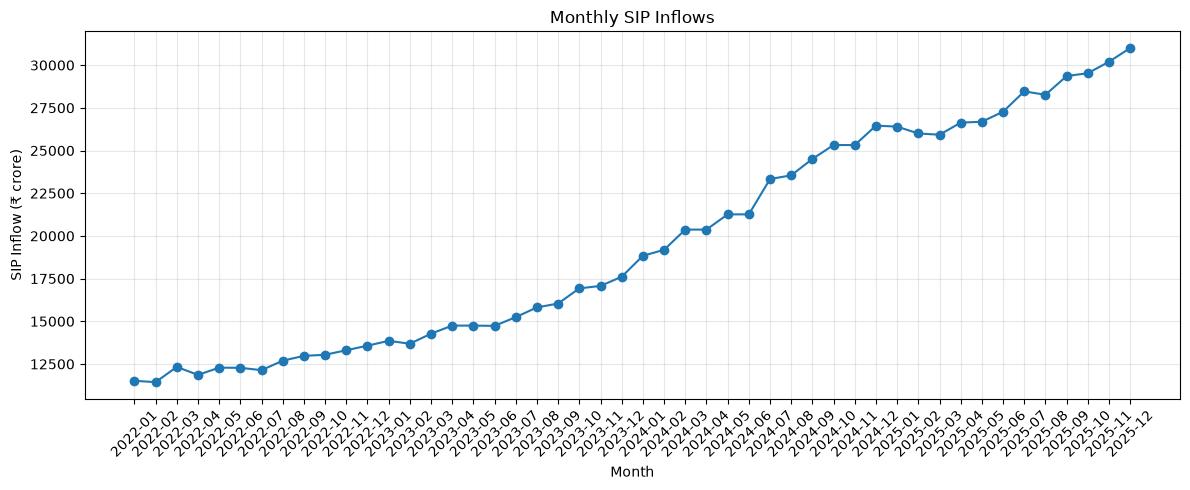

In [82]:
import matplotlib.pyplot as plt

sip_monthly = sip_monthly.sort_values("month").copy()

sip_monthly["month"] = sip_monthly["month"].astype(str)

plt.figure(figsize=(12, 5))
plt.plot(
    sip_monthly["month"],
    sip_monthly["sip_inflow_crore"],
    marker="o"
)

plt.title("Monthly SIP Inflows")
plt.xlabel("Month")
plt.ylabel("SIP Inflow (₹ crore)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [83]:
first_month = sip_monthly.iloc[0]
last_month = sip_monthly.iloc[-1]

start_inflow = first_month["sip_inflow_crore"]
end_inflow = last_month["sip_inflow_crore"]

absolute_change = end_inflow - start_inflow
percentage_change = (absolute_change / start_inflow) * 100

print(f"Starting month: {first_month['month']}")
print(f"Ending month: {last_month['month']}")
print(f"Starting SIP inflow: ₹{start_inflow:,.0f} crore")
print(f"Ending SIP inflow: ₹{end_inflow:,.0f} crore")
print(f"Absolute increase: ₹{absolute_change:,.0f} crore")
print(f"Percentage increase: {percentage_change:.2f}%")

Starting month: 2022-01
Ending month: 2025-12
Starting SIP inflow: ₹11,517 crore
Ending SIP inflow: ₹31,002 crore
Absolute increase: ₹19,485 crore
Percentage increase: 169.18%


### Finding: Long-Term Growth in Monthly SIP Inflows

Monthly SIP inflows increased from ₹11,517 crore in January 2022 to ₹31,002 crore in December 2025, an absolute increase of ₹19,485 crore (169.18%). The time series shows a broadly upward trend, with brief periods of fluctuation. The highest monthly inflow in the observed period occurred in December 2025.

**Interpretation:** The dataset indicates substantial growth in monthly SIP inflows over the four-year observation period. This is a descriptive finding and does not, by itself, establish the causes of the increase.

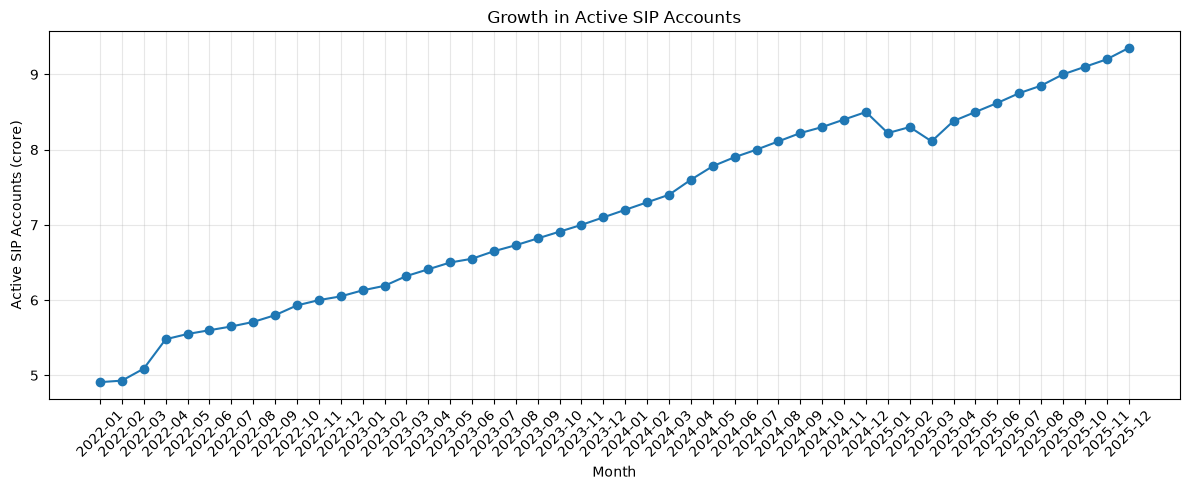

In [84]:
plt.figure(figsize=(12, 5))

plt.plot(
    sip_monthly["month"],
    sip_monthly["active_sip_accounts_crore"],
    marker="o"
)

plt.title("Growth in Active SIP Accounts")
plt.xlabel("Month")
plt.ylabel("Active SIP Accounts (crore)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [85]:
first_month = sip_monthly.iloc[0]
last_month = sip_monthly.iloc[-1]

start_accounts = first_month["active_sip_accounts_crore"]
end_accounts = last_month["active_sip_accounts_crore"]

absolute_change = end_accounts - start_accounts
percentage_change = (absolute_change / start_accounts) * 100

print(f"Starting month: {first_month['month']}")
print(f"Ending month: {last_month['month']}")
print(f"Starting active accounts: {start_accounts:.2f} crore")
print(f"Ending active accounts: {end_accounts:.2f} crore")
print(f"Absolute increase: {absolute_change:.2f} crore")
print(f"Percentage increase: {percentage_change:.2f}%")

Starting month: 2022-01
Ending month: 2025-12
Starting active accounts: 4.91 crore
Ending active accounts: 9.35 crore
Absolute increase: 4.44 crore
Percentage increase: 90.43%


### Finding: Growth in Active SIP Accounts

Active SIP accounts increased from 4.91 crore in January 2022 to 9.35 crore in December 2025, an absolute increase of 4.44 crore (90.43%). The series shows a broadly upward trend, with a temporary decline around late 2024 and early 2025 before recovering to a new high by December 2025.

**Interpretation:** The dataset indicates substantial growth in active SIP accounts over the observation period. SIP inflows grew by 169.18% over the same period, faster than the 90.43% increase in active accounts. These aggregate trends do not establish the reasons behind the difference.

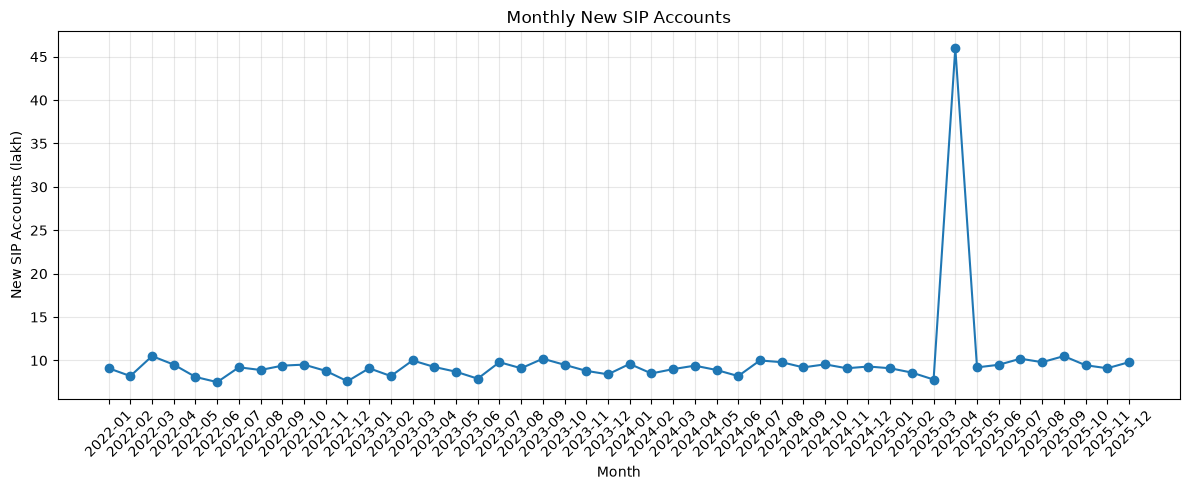

In [86]:
plt.figure(figsize=(12, 5))

plt.plot(
    sip_monthly["month"],
    sip_monthly["new_sip_accounts_lakh"],
    marker="o"
)

plt.title("Monthly New SIP Accounts")
plt.xlabel("Month")
plt.ylabel("New SIP Accounts (lakh)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [87]:
display(
    sip_monthly.loc[
        sip_monthly["month"].between("2025-01", "2025-06"),
        ["month", "new_sip_accounts_lakh", "sip_inflow_crore",
         "active_sip_accounts_crore", "yoy_growth_pct"]
    ].reset_index(drop=True)
)

,month,new_sip_accounts_lakh,sip_inflow_crore,active_sip_accounts_crore,yoy_growth_pct
0,2025-01,9.1,26400,8.22,40.14
1,2025-02,8.6,25999,8.30,35.50
2,2025-03,7.8,25926,8.11,27.27
3,2025-04,46.0,26632,8.38,30.73
4,2025-05,9.2,26688,8.50,25.52
5,2025-06,9.5,27274,8.62,28.28


In [88]:
sip_outliers = sip_monthly.loc[
    sip_monthly["new_sip_accounts_lakh"] > 15,
    ["month", "new_sip_accounts_lakh", "sip_inflow_crore",
     "active_sip_accounts_crore"]
]

display(sip_outliers.reset_index(drop=True))

,month,new_sip_accounts_lakh,sip_inflow_crore,active_sip_accounts_crore
0,2025-04,46.0,26632,8.38


### Finding: Anomaly in Monthly New SIP Account Data

Monthly new SIP account additions generally remain within a relatively narrow range across the observed period. However, April 2025 records 46.0 lakh new accounts, compared with 7.8 lakh in March and 9.2 lakh in May.

During the same period, monthly SIP inflows and active SIP accounts show more modest changes. April 2025 is the only month with more than 15 lakh new SIP accounts in the dataset.

**Data-quality note:** The April 2025 observation is an unresolved anomaly. Its accuracy and underlying cause have not been independently verified. It should be flagged in further analysis rather than silently corrected or removed.

In [89]:
missing_yoy = sip_monthly.loc[
    sip_monthly["yoy_growth_pct"].isna(),
    ["month", "sip_inflow_crore", "yoy_growth_pct"]
]

print(f"Missing YoY growth values: {len(missing_yoy)}")
display(missing_yoy.reset_index(drop=True))

Missing YoY growth values: 12


,month,sip_inflow_crore,yoy_growth_pct
0,2022-01,11517,NaN
1,2022-02,11438,NaN
2,2022-03,12328,NaN
3,2022-04,11863,NaN
4,2022-05,12286,NaN
5,2022-06,12276,NaN
6,2022-07,12140,NaN
7,2022-08,12694,NaN
8,2022-09,12976,NaN
9,2022-10,13040,NaN


### Data-Quality Finding: Missing YoY SIP Growth Values

The monthly SIP inflow dataset contains 48 monthly observations from January 2022 to December 2025. The `yoy_growth_pct` column has 12 missing values, covering January–December 2022. All 36 observations from January 2023 onward contain recorded YoY growth values.

**Data-quality note:** The missing values are retained as missing and have not been imputed. Their underlying cause has not been independently verified. Analyses of YoY growth should account for the unavailable 2022 values.

In [90]:
%whos

Variable                       Type             Data/Info
---------------------------------------------------------
PROCESSED_DATA_DIR             WindowsPath      c:\Users\ASUS\Desktop\pot<...>Project_V2\data\processed
PROJECT_ROOT                   WindowsPath      c:\Users\ASUS\Desktop\pot<...>io\Mutual_Fund_Project_V2
Path                           type             <class 'pathlib.Path'>
RAW_DATA_DIR                   WindowsPath      c:\Users\ASUS\Desktop\pot<...>_Fund_Project_V2\data\raw
a                              Series           Shape: (1150,)
absolute_change                float64          4.4399999999999995
available_indices              list             n=7
ax                             Axes             Axes(0.0984604,0.117007;0.884873x0.785327)
b                              Series           Shape: (1150,)
bar                            Rectangle        Rectangle(xy=(0, 0.725), <...>83, height=0.55, angle=0)
benchmark_coverage             DataFrame        Shape: (10, 5

In [91]:
folio_path = RAW_DATA_DIR / "06_industry_folio_count.csv"

industry_folio_df = pd.read_csv(
    folio_path,
    dtype={"month": str}
)

display(industry_folio_df.head())
display(industry_folio_df.tail())

,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
0,2022-01,13.26,9.28,1.86,0.80,1.33
1,2022-04,13.91,9.74,1.95,0.83,1.39
2,2022-07,13.85,9.69,1.94,0.83,1.38
3,2022-10,14.12,9.88,1.98,0.85,1.41
4,2023-01,14.81,10.37,2.07,0.89,1.48


,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
16,2025-07,24.57,17.20,3.44,1.47,2.46
17,2025-08,24.89,17.42,3.48,1.49,2.49
18,2025-09,25.19,17.63,3.53,1.51,2.52
19,2025-10,25.60,17.92,3.58,1.54,2.56
20,2025-12,26.12,18.28,3.66,1.57,2.61


In [92]:
print(industry_folio_df.columns.tolist())
print(industry_folio_df.shape)
display(industry_folio_df.head())
display(industry_folio_df.tail())

['month', 'total_folios_crore', 'equity_folios_crore', 'debt_folios_crore', 'hybrid_folios_crore', 'others_folios_crore']
(21, 6)


,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
0,2022-01,13.26,9.28,1.86,0.80,1.33
1,2022-04,13.91,9.74,1.95,0.83,1.39
2,2022-07,13.85,9.69,1.94,0.83,1.38
3,2022-10,14.12,9.88,1.98,0.85,1.41
4,2023-01,14.81,10.37,2.07,0.89,1.48


,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
16,2025-07,24.57,17.20,3.44,1.47,2.46
17,2025-08,24.89,17.42,3.48,1.49,2.49
18,2025-09,25.19,17.63,3.53,1.51,2.52
19,2025-10,25.60,17.92,3.58,1.54,2.56
20,2025-12,26.12,18.28,3.66,1.57,2.61


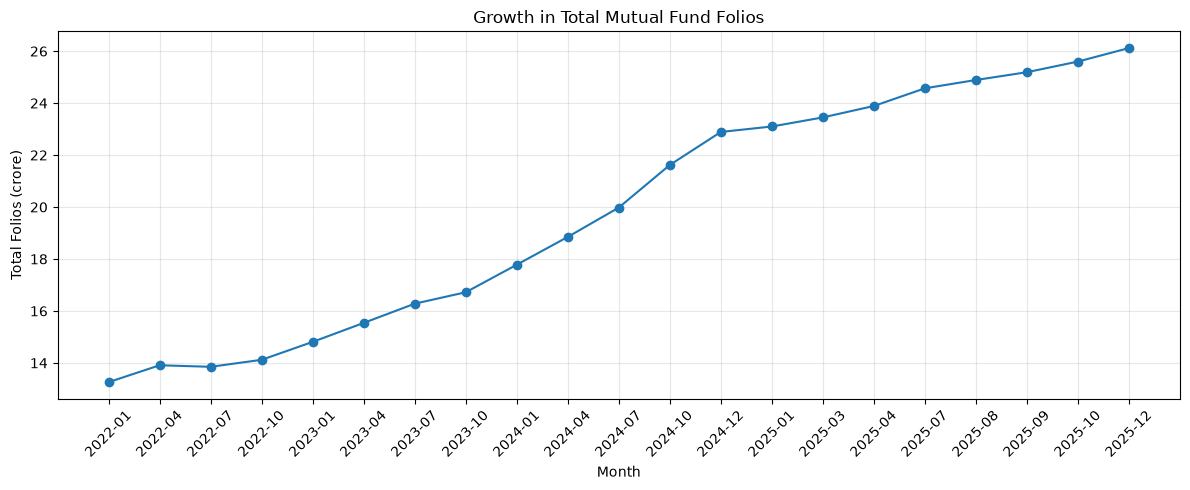

In [93]:
folio_monthly = industry_folio_df.sort_values("month").copy()

plt.figure(figsize=(12, 5))

plt.plot(
    folio_monthly["month"],
    folio_monthly["total_folios_crore"],
    marker="o"
)

plt.title("Growth in Total Mutual Fund Folios")
plt.xlabel("Month")
plt.ylabel("Total Folios (crore)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [94]:
first_folio = folio_monthly.iloc[0]
last_folio = folio_monthly.iloc[-1]

start_folios = first_folio["total_folios_crore"]
end_folios = last_folio["total_folios_crore"]

absolute_change = end_folios - start_folios
percentage_change = (absolute_change / start_folios) * 100

print(f"Starting month: {first_folio['month']}")
print(f"Ending month: {last_folio['month']}")
print(f"Starting total folios: {start_folios:.2f} crore")
print(f"Ending total folios: {end_folios:.2f} crore")
print(f"Absolute increase: {absolute_change:.2f} crore")
print(f"Percentage increase: {percentage_change:.2f}%")

Starting month: 2022-01
Ending month: 2025-12
Starting total folios: 13.26 crore
Ending total folios: 26.12 crore
Absolute increase: 12.86 crore
Percentage increase: 96.98%


### Finding: Growth in Total Mutual Fund Folios

Total mutual fund folios increased from 13.26 crore in January 2022 to 26.12 crore in December 2025, an absolute increase of 12.86 crore (96.98%). The series shows a broadly upward trend, with a minor decline in mid-2022 and stronger growth through much of 2024.

**Interpretation:** The dataset indicates substantial growth in the total number of mutual fund folios over the observation period. Folios represent investment accounts, not necessarily unique investors, so this increase should not be interpreted as an equivalent increase in the number of individual investors.

In [95]:
folio_categories = [
    "equity_folios_crore",
    "debt_folios_crore",
    "hybrid_folios_crore",
    "others_folios_crore"
]

first_folio = folio_monthly.iloc[0]
last_folio = folio_monthly.iloc[-1]

category_growth = pd.DataFrame({
    "category": [
        "Equity",
        "Debt",
        "Hybrid",
        "Others"
    ],
    "starting_folios_crore": [
        first_folio[col] for col in folio_categories
    ],
    "ending_folios_crore": [
        last_folio[col] for col in folio_categories
    ]
})

category_growth["absolute_increase_crore"] = (
    category_growth["ending_folios_crore"]
    - category_growth["starting_folios_crore"]
)

category_growth["percentage_increase"] = (
    category_growth["absolute_increase_crore"]
    / category_growth["starting_folios_crore"]
    * 100
)

display(category_growth.round(2))

,category,starting_folios_crore,ending_folios_crore,absolute_increase_crore,percentage_increase
0,Equity,9.28,18.28,9.00,96.98
1,Debt,1.86,3.66,1.80,96.77
2,Hybrid,0.80,1.57,0.77,96.25
3,Others,1.33,2.61,1.28,96.24


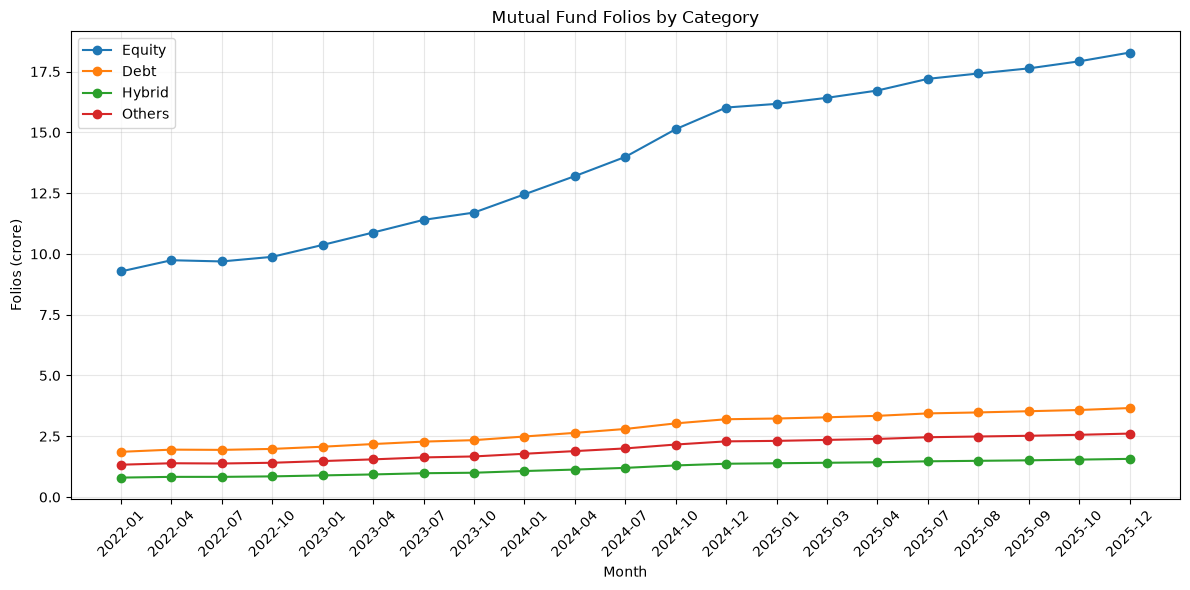

In [96]:
plt.figure(figsize=(12, 6))

for col, label in zip(
    [
        "equity_folios_crore",
        "debt_folios_crore",
        "hybrid_folios_crore",
        "others_folios_crore"
    ],
    ["Equity", "Debt", "Hybrid", "Others"]
):
    plt.plot(
        folio_monthly["month"],
        folio_monthly[col],
        marker="o",
        label=label
    )

plt.title("Mutual Fund Folios by Category")
plt.xlabel("Month")
plt.ylabel("Folios (crore)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Finding: Mutual Fund Folios by Category

Equity folios recorded the largest absolute increase, rising from 9.28 crore in January 2022 to 18.28 crore in December 2025—an increase of 9.00 crore (96.98%). Debt folios increased by 1.80 crore, hybrid folios by 0.77 crore, and other folios by 1.28 crore. All four categories experienced growth of approximately 96% over the observation period.

**Interpretation:** Equity remained the largest folio category throughout the period and contributed the most to the absolute increase in folios. The broadly similar percentage growth across categories indicates that each category expanded substantially relative to its own starting level. These are descriptive trends and do not establish the causes of growth.

In [97]:
folio_monthly["category_sum_crore"] = (
    folio_monthly["equity_folios_crore"]
    + folio_monthly["debt_folios_crore"]
    + folio_monthly["hybrid_folios_crore"]
    + folio_monthly["others_folios_crore"]
)

folio_monthly["difference_crore"] = (
    folio_monthly["total_folios_crore"]
    - folio_monthly["category_sum_crore"]
)

print("Maximum absolute difference (crore):")
print(folio_monthly["difference_crore"].abs().max())

display(
    folio_monthly[
        ["month", "total_folios_crore",
         "category_sum_crore", "difference_crore"]
    ].round(3)
)

Maximum absolute difference (crore):
0.010000000000005116


,month,total_folios_crore,category_sum_crore,difference_crore
0,2022-01,13.26,13.27,-0.01
1,2022-04,13.91,13.91,0.00
2,2022-07,13.85,13.84,0.01
3,2022-10,14.12,14.12,-0.00
4,2023-01,14.81,14.81,0.00
5,2023-04,15.54,15.54,-0.00
6,2023-07,16.28,16.29,-0.01
7,2023-10,16.72,16.71,0.01
8,2024-01,17.78,17.79,-0.01
9,2024-04,18.85,18.86,-0.01


### Data-Quality Finding: Folio Category Reconciliation

The sum of equity, debt, hybrid, and other folios was compared with the reported total folios for all 21 observations. The maximum absolute difference was 0.01 crore, equivalent to 1 lakh folios, with the displayed differences ranging from approximately -0.01 to +0.01 crore.

**Conclusion:** Category totals reconcile closely with reported total folios. The small differences are consistent with rounding in values reported to two decimal places. The original values are retained without adjustment.

## 4. Scheme Characteristics and Expense Ratios

In [98]:
category_counts = (
    fund_master_df["category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="scheme_count")
)

category_counts["percentage"] = (
    category_counts["scheme_count"]
    / len(fund_master_df)
    * 100
)

display(category_counts.round(2))

,category,scheme_count,percentage
0,Equity,34,85.0
1,Debt,6,15.0


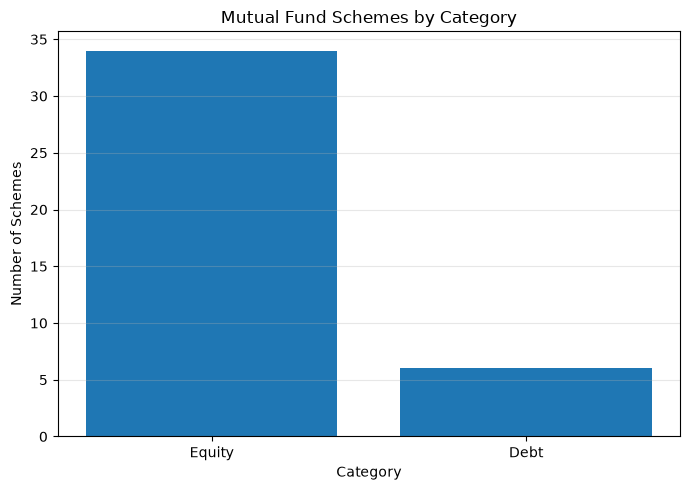

In [99]:
plt.figure(figsize=(7, 5))

plt.bar(
    category_counts["category"],
    category_counts["scheme_count"]
)

plt.title("Mutual Fund Schemes by Category")
plt.xlabel("Category")
plt.ylabel("Number of Schemes")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Finding: Mutual Fund Scheme Category Distribution

The fund master contains 40 schemes, comprising 34 Equity schemes (85%) and 6 Debt schemes (15%). Equity schemes therefore represent the majority of the schemes included in this dataset.

**Interpretation:** The dataset is weighted toward equity schemes. Subsequent comparisons and findings should be interpreted in the context of this sample composition and should not be generalized to the entire mutual fund industry.

In [100]:
plan_distribution = pd.crosstab(
    fund_master_df["category"],
    fund_master_df["plan"]
)

plan_distribution["Total"] = plan_distribution.sum(axis=1)

plan_distribution.loc["Total"] = plan_distribution.sum(axis=0)

display(plan_distribution)

plan,Direct,Regular,Total
category,,,
Debt,0,6,6
Equity,8,26,34
Total,8,32,40


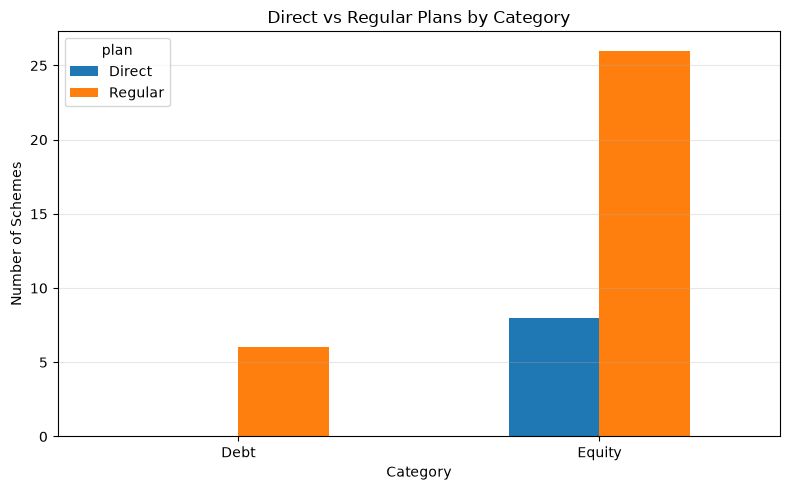

In [101]:
plan_by_category = pd.crosstab(
    fund_master_df["category"],
    fund_master_df["plan"]
)

plan_by_category.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Direct vs Regular Plans by Category")
plt.xlabel("Category")
plt.ylabel("Number of Schemes")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Finding: Direct vs Regular Plan Distribution

Of the 40 schemes in the fund master, 32 (80%) are Regular plans and 8 (20%) are Direct plans. Within the Equity category, 26 schemes are Regular plans and 8 are Direct plans. All 6 Debt schemes in the dataset are Regular plans, with no Direct Debt schemes represented.

**Interpretation:** Regular plans dominate the sample, and Direct plans appear only in the Equity category. This is a characteristic of the selected dataset and should not be interpreted as the plan distribution of the wider mutual fund industry.

In [102]:
subcategory_counts = (
    fund_master_df["sub_category"]
    .value_counts()
    .rename_axis("sub_category")
    .reset_index(name="scheme_count")
)

subcategory_counts["percentage"] = (
    subcategory_counts["scheme_count"]
    / len(fund_master_df)
    * 100
)

display(subcategory_counts.round(2))

,sub_category,scheme_count,percentage
0,Large Cap,14,35.0
1,Mid Cap,7,17.5
2,Small Cap,6,15.0
3,Liquid,3,7.5
4,Gilt,2,5.0
5,Flexi Cap,2,5.0
6,Short Duration,1,2.5
7,Value,1,2.5
8,Index/ETF,1,2.5
9,Index,1,2.5


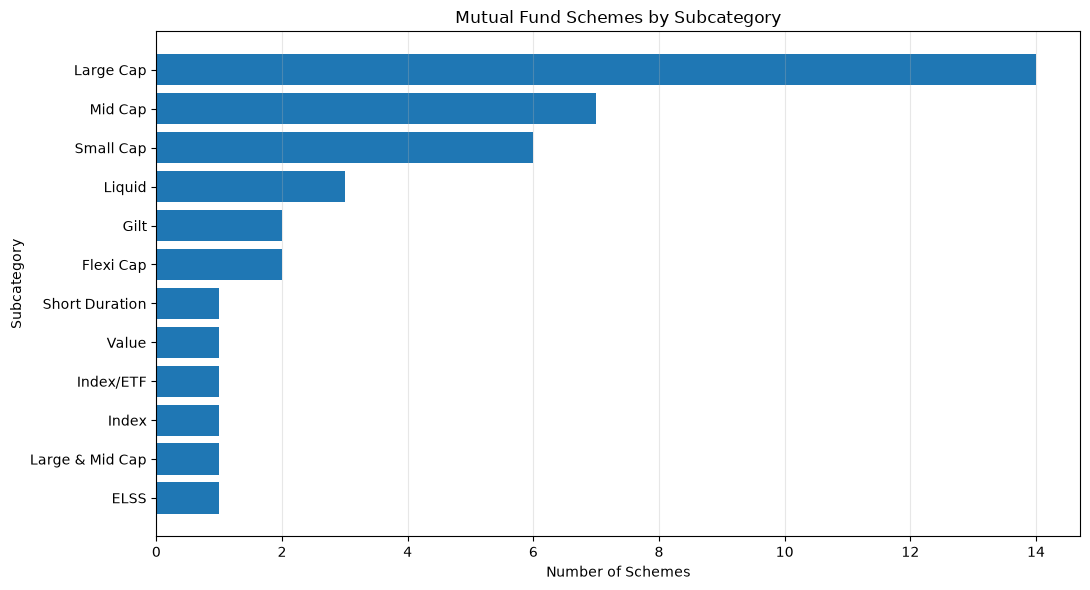

In [103]:
plt.figure(figsize=(11, 6))

plt.barh(
    subcategory_counts["sub_category"].iloc[::-1],
    subcategory_counts["scheme_count"].iloc[::-1]
)

plt.title("Mutual Fund Schemes by Subcategory")
plt.xlabel("Number of Schemes")
plt.ylabel("Subcategory")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Finding: Mutual Fund Scheme Distribution by Subcategory

Large Cap is the most represented subcategory, with 14 schemes (35% of the 40-scheme sample). Mid Cap accounts for 7 schemes (17.5%), while Small Cap accounts for 6 schemes (15%). Combined, these three subcategories represent 27 schemes, or 67.5% of the dataset. The remaining nine subcategories account for the other 13 schemes.

**Interpretation:** The fund master is concentrated in Large Cap, Mid Cap, and Small Cap schemes. Comparisons involving less-represented subcategories should be interpreted cautiously because some contain only one or two schemes. These counts describe the selected sample, not the entire mutual fund industry.

In [104]:
expense_summary = fund_master_df["expense_ratio_pct"].describe()

display(expense_summary.to_frame(name="expense_ratio_pct").round(2))

,expense_ratio_pct
count,40.00
mean,1.24
std,0.39
min,0.55
25%,0.79
50%,1.42
75%,1.54
max,1.64


In [105]:
expense_by_category = (
    fund_master_df
    .groupby("category")["expense_ratio_pct"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(expense_by_category)

,count,mean,median,min,max
category,,,,,
Debt,6,0.67,0.67,0.55,0.79
Equity,34,1.34,1.48,0.66,1.64


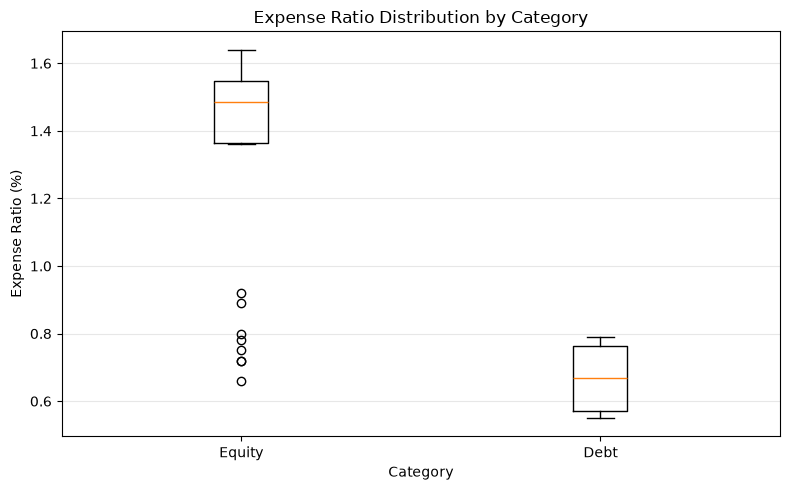

In [106]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        fund_master_df.loc[
            fund_master_df["category"] == "Equity",
            "expense_ratio_pct"
        ],
        fund_master_df.loc[
            fund_master_df["category"] == "Debt",
            "expense_ratio_pct"
        ]
    ],
    tick_labels=["Equity", "Debt"]
)

plt.title("Expense Ratio Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Expense Ratio (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Finding: Expense Ratio Comparison by Category

Across the 40 schemes, the mean expense ratio is 1.24% and the median is 1.42%. Equity schemes (34 observations) have a mean expense ratio of 1.34% and a median of 1.48%, compared with 0.67% for both the mean and median among the 6 Debt schemes.

**Interpretation:** Expense ratios are higher among Equity schemes than Debt schemes in this sample. The boxplot also shows several lower expense-ratio Equity schemes flagged as statistical outliers. Because the Debt group contains only six schemes and the dataset is a selected sample, these findings should not be generalized to the entire mutual fund industry.

In [107]:
expense_by_plan = (
    fund_master_df
    .groupby("plan")["expense_ratio_pct"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(expense_by_plan)

,count,mean,median,min,max
plan,,,,,
Direct,8,0.78,0.76,0.66,0.92
Regular,32,1.35,1.51,0.55,1.64


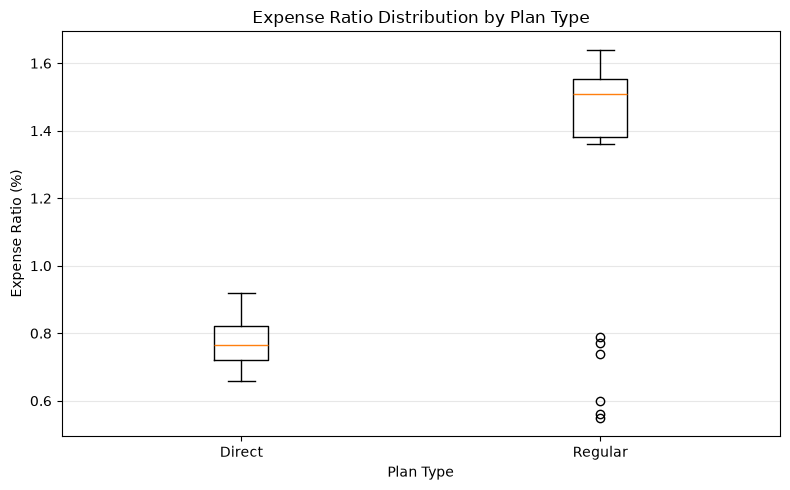

In [108]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        fund_master_df.loc[
            fund_master_df["plan"] == "Direct",
            "expense_ratio_pct"
        ],
        fund_master_df.loc[
            fund_master_df["plan"] == "Regular",
            "expense_ratio_pct"
        ]
    ],
    tick_labels=["Direct", "Regular"]
)

plt.title("Expense Ratio Distribution by Plan Type")
plt.xlabel("Plan Type")
plt.ylabel("Expense Ratio (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Finding: Expense Ratio Comparison by Plan Type

Direct plans have a mean expense ratio of 0.78% and a median of 0.76%, compared with a mean of 1.35% and a median of 1.51% for Regular plans. The dataset contains 8 Direct schemes and 32 Regular schemes. The boxplot shows a clear separation between the typical expense ratios of the two plan groups, with several lower-ratio Regular schemes appearing as statistical outliers.

**Interpretation:** Regular plans have higher expense ratios than Direct plans in this selected sample. The comparison is descriptive and should be interpreted in the context of the sample composition; it does not establish the cause of the difference or represent every mutual fund scheme.

In [109]:
expense_by_subcategory = (
    fund_master_df
    .groupby("sub_category")["expense_ratio_pct"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
    .round(2)
)

display(expense_by_subcategory)

,count,mean,median,min,max
sub_category,,,,,
ELSS,1,1.60,1.60,1.60,1.60
Index,1,1.57,1.57,1.57,1.57
Flexi Cap,2,1.54,1.54,1.45,1.64
Large & Mid Cap,1,1.52,1.52,1.52,1.52
Value,1,1.41,1.41,1.41,1.41
Mid Cap,7,1.37,1.38,0.78,1.61
Small Cap,6,1.35,1.48,0.72,1.53
Large Cap,14,1.26,1.48,0.66,1.64
Index/ETF,1,0.89,0.89,0.89,0.89


### Finding: Expense Ratios by Fund Subcategory

Mean expense ratios vary across the 12 subcategories in the sample, ranging from 0.56% for Short Duration to 1.60% for ELSS. Large Cap schemes, the largest group with 14 observations, have a mean expense ratio of 1.26% and a median of 1.48%. Mid Cap schemes have a mean of 1.37%, while Small Cap schemes have a mean of 1.35%.

**Interpretation:** Expense ratios differ across the subcategories represented in the dataset. However, several subcategories contain only one or two schemes, so their averages are not reliable estimates of typical subcategory-level expense ratios. These results describe the selected sample and should not be generalized to the entire mutual fund industry.

## 5. Assets Under Management (AUM)

In [110]:
aum_path = RAW_DATA_DIR / "03_aum_by_fund_house.csv"

aum_df = pd.read_csv(aum_path)

display(aum_df.head())
display(aum_df.tail())
print(aum_df.shape)
print(aum_df.dtypes)

,date,fund_house,aum_lakh_crore,aum_crore,num_schemes
0,2022-03-31,SBI Mutual Fund,6.05,605000,186
1,2022-03-31,ICICI Prudential MF,4.65,465000,216
2,2022-03-31,HDFC Mutual Fund,4.35,435000,195
3,2022-03-31,Nippon India MF,2.70,270000,177
4,2022-03-31,Kotak Mahindra MF,2.70,270000,168


,date,fund_house,aum_lakh_crore,aum_crore,num_schemes
85,2025-12-31,Aditya Birla Sun Life MF,4.6,460000,199
86,2025-12-31,Axis Mutual Fund,3.5,350000,95
87,2025-12-31,UTI Mutual Fund,4.1,410000,142
88,2025-12-31,Mirae Asset MF,2.9,290000,56
89,2025-12-31,DSP Mutual Fund,2.3,230000,88


(90, 5)
date                  str
fund_house            str
aum_lakh_crore    float64
aum_crore           int64
num_schemes         int64
dtype: object


In [111]:
aum_df["date"] = pd.to_datetime(aum_df["date"])

total_aum_trend = (
    aum_df.groupby("date", as_index=False)
    .agg(
        total_aum_lakh_crore=("aum_lakh_crore", "sum"),
        total_schemes=("num_schemes", "sum")
    )
    .sort_values("date")
)

display(total_aum_trend)

,date,total_aum_lakh_crore,total_schemes
0,2022-03-31,30.18,1522
1,2022-09-30,30.90,1522
2,2023-03-31,32.35,1522
3,2023-09-30,37.42,1522
4,2024-03-31,43.75,1522
5,2024-09-30,47.27,1522
6,2024-12-31,52.68,1522
7,2025-03-31,54.47,1522
8,2025-12-31,62.74,1522


In [112]:
start_aum = total_aum_trend["total_aum_lakh_crore"].iloc[0]
end_aum = total_aum_trend["total_aum_lakh_crore"].iloc[-1]

absolute_increase = end_aum - start_aum
percentage_increase = (absolute_increase / start_aum) * 100

print("Starting date:", total_aum_trend["date"].iloc[0].date())
print("Ending date:", total_aum_trend["date"].iloc[-1].date())
print(f"Starting total AUM: ₹{start_aum:.2f} lakh crore")
print(f"Ending total AUM: ₹{end_aum:.2f} lakh crore")
print(f"Absolute increase: ₹{absolute_increase:.2f} lakh crore")
print(f"Percentage increase: {percentage_increase:.2f}%")

Starting date: 2022-03-31
Ending date: 2025-12-31
Starting total AUM: ₹30.18 lakh crore
Ending total AUM: ₹62.74 lakh crore
Absolute increase: ₹32.56 lakh crore
Percentage increase: 107.89%


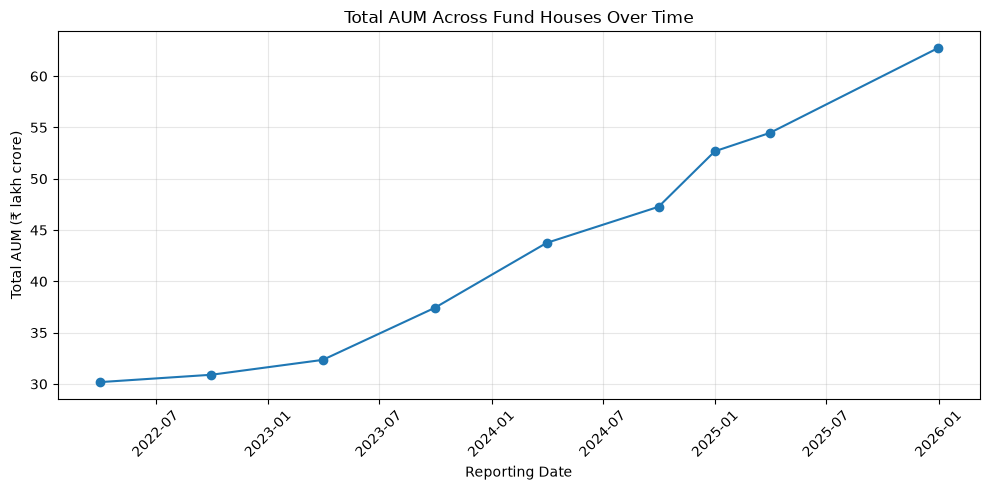

In [113]:
plt.figure(figsize=(10, 5))

plt.plot(
    total_aum_trend["date"],
    total_aum_trend["total_aum_lakh_crore"],
    marker="o"
)

plt.title("Total AUM Across Fund Houses Over Time")
plt.xlabel("Reporting Date")
plt.ylabel("Total AUM (₹ lakh crore)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [114]:
latest_aum = (
    aum_df[aum_df["date"] == aum_df["date"].max()]
    .sort_values("aum_lakh_crore", ascending=False)
    .reset_index(drop=True)
)

display(
    latest_aum[
        ["fund_house", "aum_lakh_crore", "num_schemes"]
    ]
)


,fund_house,aum_lakh_crore,num_schemes
0,SBI Mutual Fund,12.50,186
1,ICICI Prudential MF,10.74,216
2,HDFC Mutual Fund,9.30,195
3,Nippon India MF,7.00,177
4,Kotak Mahindra MF,5.80,168
5,Aditya Birla Sun Life MF,4.60,199
6,UTI Mutual Fund,4.10,142
7,Axis Mutual Fund,3.50,95
8,Mirae Asset MF,2.90,56
9,DSP Mutual Fund,2.30,88


In [115]:
aum_pivot = aum_df.pivot(
    index="fund_house",
    columns="date",
    values="aum_lakh_crore"
)

start_date = aum_df["date"].min()
end_date = aum_df["date"].max()

fund_house_growth = pd.DataFrame({
    "starting_aum": aum_pivot[start_date],
    "ending_aum": aum_pivot[end_date]
})

fund_house_growth["absolute_increase"] = (
    fund_house_growth["ending_aum"]
    - fund_house_growth["starting_aum"]
)

fund_house_growth["growth_pct"] = (
    fund_house_growth["absolute_increase"]
    / fund_house_growth["starting_aum"]
    * 100
)

fund_house_growth = fund_house_growth.sort_values(
    "growth_pct", ascending=False
).round(2)

display(fund_house_growth)

,starting_aum,ending_aum,absolute_increase,growth_pct
fund_house,,,,
Mirae Asset MF,1.05,2.90,1.85,176.19
Nippon India MF,2.70,7.00,4.30,159.26
ICICI Prudential MF,4.65,10.74,6.09,130.97
Kotak Mahindra MF,2.70,5.80,3.10,114.81
HDFC Mutual Fund,4.35,9.30,4.95,113.79
DSP Mutual Fund,1.10,2.30,1.20,109.09
SBI Mutual Fund,6.05,12.50,6.45,106.61
UTI Mutual Fund,2.30,4.10,1.80,78.26
Aditya Birla Sun Life MF,2.78,4.60,1.82,65.47


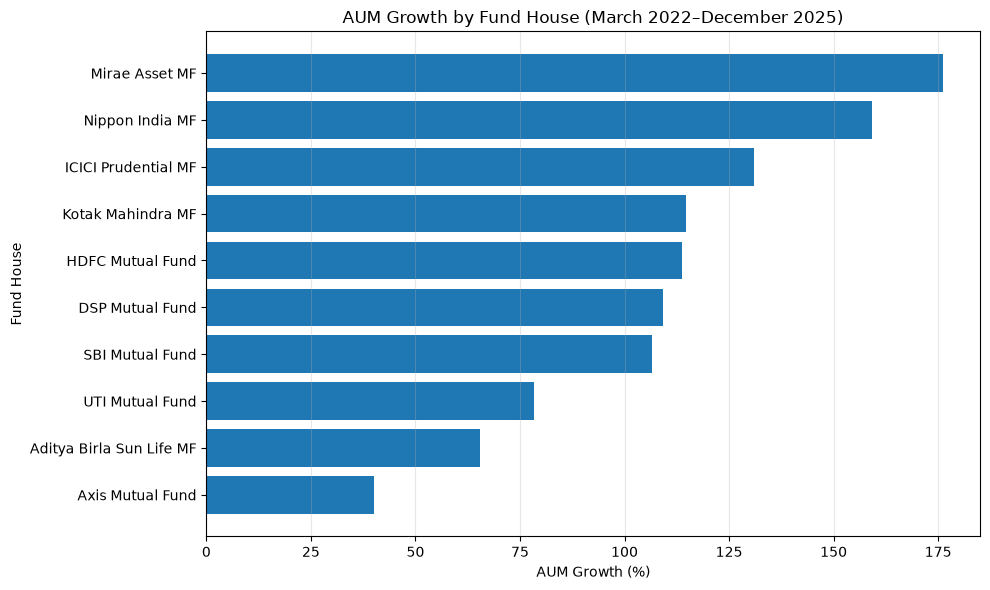

In [116]:
plt.figure(figsize=(10, 6))

growth_plot = fund_house_growth.sort_values("growth_pct")

plt.barh(
    growth_plot.index,
    growth_plot["growth_pct"]
)

plt.title("AUM Growth by Fund House (March 2022–December 2025)")
plt.xlabel("AUM Growth (%)")
plt.ylabel("Fund House")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### AUM Analysis — Key Findings

**Period:** March 2022 to December 2025

- Combined reported AUM across the 10 fund houses increased from ₹30.18 lakh crore to ₹62.74 lakh crore.
- The absolute increase was ₹32.56 lakh crore, representing growth of 107.89%.
- SBI Mutual Fund had the highest reported AUM at the latest observation, ₹12.50 lakh crore, and the largest absolute increase, ₹6.45 lakh crore.
- Mirae Asset MF recorded the highest percentage AUM growth at 176.19%, increasing from ₹1.05 lakh crore to ₹2.90 lakh crore.
- Axis Mutual Fund recorded the lowest percentage growth among the 10 fund houses at 40.00%.
- The sum of reported scheme counts remained 1,522 at every reporting date.

**Limitations:**
- The dataset contains nine reporting dates, with gaps between observations.
- AUM changes can reflect both market movements and investor flows; this analysis does not separate those effects.
- The scheme count is the sum of reported counts across fund houses and should not automatically be interpreted as the number of unique schemes in the industry.
- Findings describe the supplied dataset and have not been independently verified against external industry data.

In [117]:
print("Dataset shape:", sip_df.shape)
print("\nColumns:")
print(sip_df.columns.tolist())

print("\nDate range:")
print(sip_df["month"].min(), "to", sip_df["month"].max())

print("\nSummary statistics:")
display(sip_df.describe().round(2))

Dataset shape: (48, 6)

Columns:
['month', 'sip_inflow_crore', 'active_sip_accounts_crore', 'new_sip_accounts_lakh', 'sip_aum_lakh_crore', 'yoy_growth_pct']

Date range:
2022-01 to 2025-12

Summary statistics:


,sip_inflow_crore,active_sip_accounts_crore,new_sip_accounts_lakh,sip_aum_lakh_crore,yoy_growth_pct
count,48.00,48.00,48.00,48.00,36.00
mean,19577.52,7.19,9.89,8.63,31.46
std,6354.33,1.27,5.37,3.61,11.77
min,11438.00,4.91,7.50,4.80,15.80
25%,13658.50,6.11,8.78,5.79,20.24
50%,18224.00,7.15,9.20,7.26,28.30
75%,25944.25,8.30,9.56,10.52,40.81
max,31002.00,9.35,46.00,15.90,53.05


In [118]:
sip_changes = sip_df.sort_values("month").copy()

sip_changes["monthly_change_crore"] = (
    sip_changes["sip_inflow_crore"].diff()
)

sip_changes["monthly_change_pct"] = (
    sip_changes["sip_inflow_crore"].pct_change() * 100
)

print("Largest monthly increases:")
display(
    sip_changes.nlargest(5, "monthly_change_crore")[
        ["month", "sip_inflow_crore",
         "monthly_change_crore", "monthly_change_pct"]
    ].round(2)
)

print("Largest monthly decreases:")
display(
    sip_changes.nsmallest(5, "monthly_change_crore")[
        ["month", "sip_inflow_crore",
         "monthly_change_crore", "monthly_change_pct"]
    ].round(2)
)

Largest monthly increases:


,month,sip_inflow_crore,monthly_change_crore,monthly_change_pct
30,2024-07,23332,2070.0,9.74
24,2024-01,18838,1228.0,6.97
42,2025-07,28464,1190.0,4.36
26,2024-03,20371,1184.0,6.17
35,2024-12,26459,1139.0,4.50


Largest monthly decreases:


,month,sip_inflow_crore,monthly_change_crore,monthly_change_pct
3,2022-04,11863,-465.0,-3.77
37,2025-02,25999,-401.0,-1.52
43,2025-08,28265,-199.0,-0.70
13,2023-02,13687,-169.0,-1.22
6,2022-07,12140,-136.0,-1.11


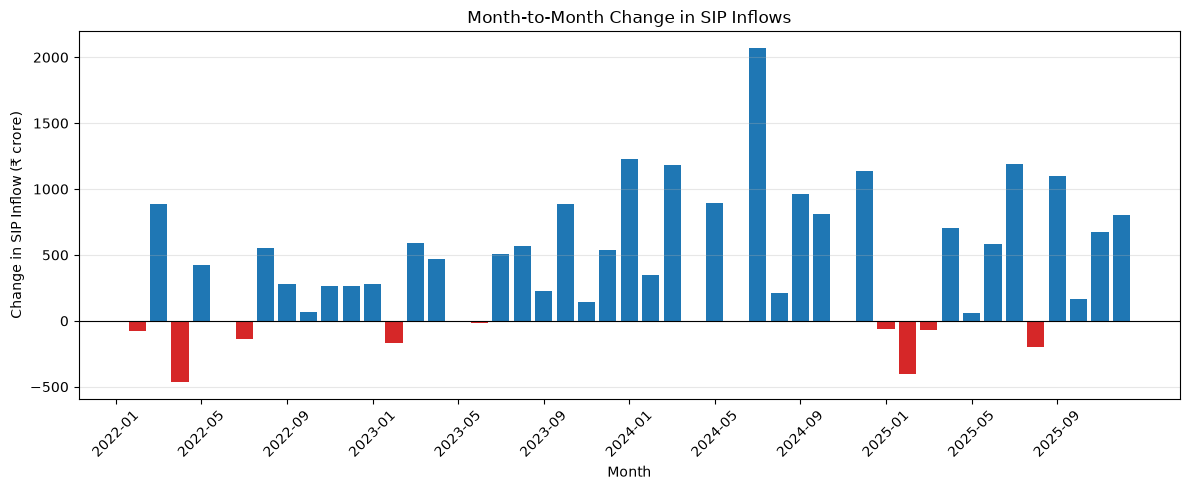

In [119]:
plt.figure(figsize=(12, 5))

colors = [
    "tab:blue" if value >= 0 else "tab:red"
    for value in sip_changes["monthly_change_crore"]
]

plt.bar(
    sip_changes["month"],
    sip_changes["monthly_change_crore"],
    color=colors
)

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Month-to-Month Change in SIP Inflows")
plt.xlabel("Month")
plt.ylabel("Change in SIP Inflow (₹ crore)")
plt.xticks(
    range(0, len(sip_changes), 4),
    sip_changes["month"].iloc[::4],
    rotation=45
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Month-to-Month SIP Inflow Changes

- The largest monthly increase in SIP inflows occurred in July 2024, rising by ₹2,070 crore (+9.74%) compared with June 2024.
- The largest monthly decrease occurred in April 2022, falling by ₹465 crore (−3.77%) compared with March 2022.
- Other notable increases included January 2024 (+₹1,228 crore) and July 2025 (+₹1,190 crore).
- Monthly changes varied considerably, indicating that a rising long-term trend does not imply uninterrupted month-to-month growth.

**Limitations:** These figures describe changes in monthly SIP inflows only. They do not explain the causes of the changes or measure investment returns. January 2022 has no month-to-month change because December 2021 is outside the dataset.

In [120]:
sip_relationship = sip_df[
    ["sip_inflow_crore", "active_sip_accounts_crore"]
].corr()

display(sip_relationship.round(3))

,sip_inflow_crore,active_sip_accounts_crore
sip_inflow_crore,1.00,0.98
active_sip_accounts_crore,0.98,1.00


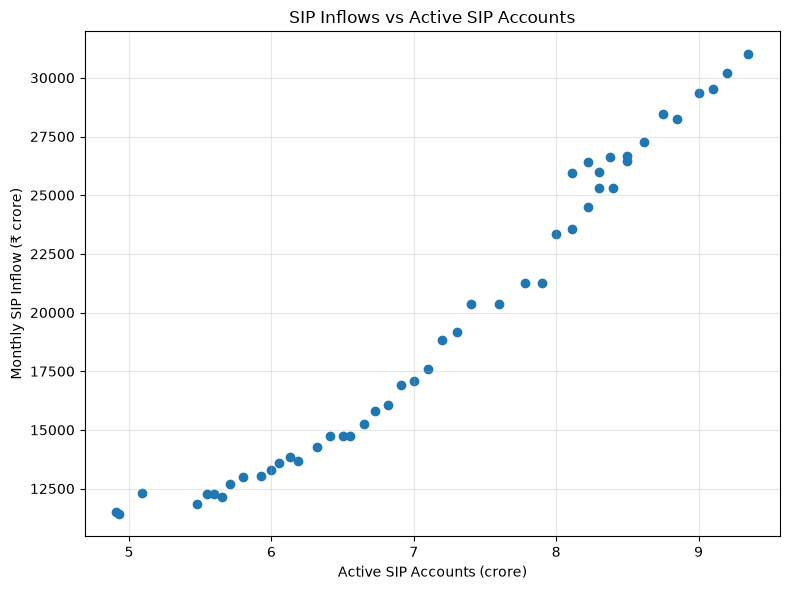

In [121]:
plt.figure(figsize=(8, 6))

plt.scatter(
    sip_df["active_sip_accounts_crore"],
    sip_df["sip_inflow_crore"]
)

plt.title("SIP Inflows vs Active SIP Accounts")
plt.xlabel("Active SIP Accounts (crore)")
plt.ylabel("Monthly SIP Inflow (₹ crore)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Relationship Between SIP Inflows and Active SIP Accounts

- Monthly SIP inflows and active SIP accounts had a Pearson correlation coefficient of **0.98**, indicating a very strong positive linear association in the dataset.
- The scatter plot shows that higher active account counts generally coincided with higher monthly SIP inflows.
- Across the observation period, SIP inflows rose from ₹11,517 crore in January 2022 to ₹31,002 crore in December 2025, while active SIP accounts increased from 4.91 crore to 9.35 crore.

**Limitations:** Correlation does not establish causation. Both variables trend upward over time, which may inflate their correlation. The analysis does not establish how individual investors' contribution amounts changed.

In [122]:
sip_df["year"] = pd.to_datetime(
    sip_df["month"]
).dt.year

annual_sip_summary = (
    sip_df.groupby("year")
    .agg(
        average_monthly_inflow=("sip_inflow_crore", "mean"),
        total_monthly_inflow=("sip_inflow_crore", "sum"),
        average_active_accounts=("active_sip_accounts_crore", "mean"),
        average_sip_aum=("sip_aum_lakh_crore", "mean")
    )
    .round(2)
)

display(annual_sip_summary)

,average_monthly_inflow,total_monthly_inflow,average_active_accounts,average_sip_aum
year,,,,
2022,12453.08,149437,5.56,5.25
2023,15396.92,184763,6.61,6.44
2024,22481.75,269781,7.89,8.47
2025,27978.33,335740,8.70,14.37


### Annual SIP Inflow Summary

- Average monthly SIP inflows increased from ₹12,453.08 crore in 2022 to ₹27,978.33 crore in 2025, an increase of approximately 124.7%.
- Average active SIP accounts increased from 5.56 crore in 2022 to 8.70 crore in 2025.
- Average reported SIP AUM increased from ₹5.25 lakh crore in 2022 to ₹14.37 lakh crore in 2025.
- The annual summary shows an upward trend across all three indicators over the four calendar years.

**Interpretation and limitations:** These figures describe the supplied dataset. Average monthly inflow is distinct from total annual inflow, while SIP AUM represents assets under management rather than contributions made during the year. The summary does not identify the causes of the increases.

In [123]:
annual_sip_check = annual_sip_summary.copy()

annual_sip_check["expected_annual_total"] = (
    annual_sip_check["average_monthly_inflow"] * 12
)

annual_sip_check["difference"] = (
    annual_sip_check["total_monthly_inflow"]
    - annual_sip_check["expected_annual_total"]
)

display(annual_sip_check.round(2))

,average_monthly_inflow,total_monthly_inflow,average_active_accounts,average_sip_aum,expected_annual_total,difference
year,,,,,,
2022,12453.08,149437,5.56,5.25,149436.96,0.04
2023,15396.92,184763,6.61,6.44,184763.04,-0.04
2024,22481.75,269781,7.89,8.47,269781.00,0.00
2025,27978.33,335740,8.70,14.37,335739.96,0.04


## 6. Category-Level Inflow Analysis

In [124]:
category_inflows_df = pd.read_csv(
    RAW_DATA_DIR / "05_category_inflows.csv"
)

print("Shape:", category_inflows_df.shape)
print("\nColumns:", category_inflows_df.columns.tolist())
print("\nDate range:")
print(
    category_inflows_df["month"].min(),
    "to",
    category_inflows_df["month"].max()
)

print("\nCategories:")
print(sorted(category_inflows_df["category"].unique()))

display(category_inflows_df.head())

Shape: (144, 3)

Columns: ['month', 'category', 'net_inflow_crore']

Date range:
2024-04 to 2025-03

Categories:
['ELSS', 'Flexi Cap', 'Gilt', 'Hybrid', 'Large & Mid Cap', 'Large Cap', 'Liquid', 'Mid Cap', 'Sectoral/Thematic', 'Short Duration', 'Small Cap', 'Value/Contra']


,month,category,net_inflow_crore
0,2024-04,Large Cap,2413.0
1,2024-04,Mid Cap,3897.0
2,2024-04,Small Cap,3533.0
3,2024-04,Flexi Cap,4947.0
4,2024-04,Large & Mid Cap,4214.0


In [125]:
category_totals = (
    category_inflows_df.groupby("category", as_index=False)
    .agg(
        total_net_inflow_crore=("net_inflow_crore", "sum"),
        average_monthly_inflow_crore=("net_inflow_crore", "mean"),
        months_reported=("month", "nunique")
    )
    .sort_values("total_net_inflow_crore", ascending=False)
    .reset_index(drop=True)
)

display(category_totals.round(2))

,category,total_net_inflow_crore,average_monthly_inflow_crore,months_reported
0,Liquid,451275.0,37606.25,12
1,Sectoral/Thematic,103829.0,8652.42,12
2,Flexi Cap,63989.0,5332.42,12
3,Large & Mid Cap,57752.0,4812.67,12
4,Short Duration,55530.0,4627.50,12
5,Mid Cap,55312.0,4609.33,12
6,Small Cap,46596.0,3883.00,12
7,Hybrid,38868.0,3239.00,12
8,Large Cap,25633.0,2136.08,12
9,Value/Contra,16980.0,1415.00,12


In [126]:
print("Liquid category — monthly values:")

display(
    category_inflows_df[
        category_inflows_df["category"] == "Liquid"
    ].sort_values("month")
)

print("\nLargest monthly inflows across all categories:")

display(
    category_inflows_df.nlargest(10, "net_inflow_crore")[
        ["month", "category", "net_inflow_crore"]
    ]
)

Liquid category — monthly values:


,month,category,net_inflow_crore
8,2024-04,Liquid,37537.0
20,2024-05,Liquid,41872.0
32,2024-06,Liquid,40486.0
44,2024-07,Liquid,34643.0
56,2024-08,Liquid,41952.0
68,2024-09,Liquid,35308.0
80,2024-10,Liquid,39091.0
92,2024-11,Liquid,40506.0
104,2024-12,Liquid,34933.0
116,2025-01,Liquid,33892.0



Largest monthly inflows across all categories:


,month,category,net_inflow_crore
56,2024-08,Liquid,41952.0
20,2024-05,Liquid,41872.0
92,2024-11,Liquid,40506.0
32,2024-06,Liquid,40486.0
80,2024-10,Liquid,39091.0
140,2025-03,Liquid,38681.0
8,2024-04,Liquid,37537.0
68,2024-09,Liquid,35308.0
104,2024-12,Liquid,34933.0
44,2024-07,Liquid,34643.0


In [127]:
non_liquid_totals = (
    category_totals[
        category_totals["category"] != "Liquid"
    ]
    .sort_values("total_net_inflow_crore", ascending=False)
    .reset_index(drop=True)
)

display(non_liquid_totals.round(2))

,category,total_net_inflow_crore,average_monthly_inflow_crore,months_reported
0,Sectoral/Thematic,103829.0,8652.42,12
1,Flexi Cap,63989.0,5332.42,12
2,Large & Mid Cap,57752.0,4812.67,12
3,Short Duration,55530.0,4627.50,12
4,Mid Cap,55312.0,4609.33,12
5,Small Cap,46596.0,3883.00,12
6,Hybrid,38868.0,3239.00,12
7,Large Cap,25633.0,2136.08,12
8,Value/Contra,16980.0,1415.00,12
9,Gilt,10395.0,866.25,12


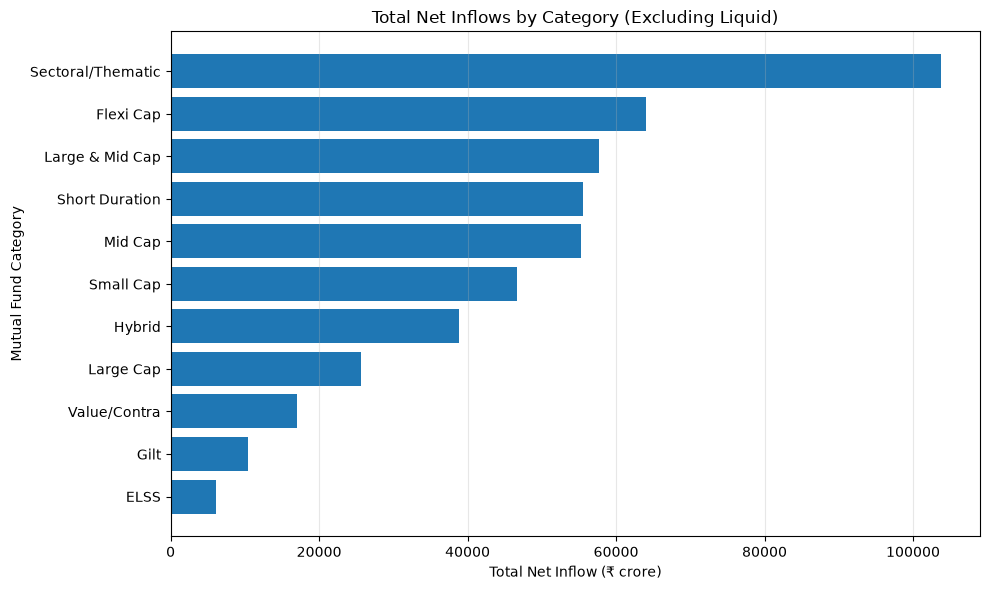

In [128]:
plt.figure(figsize=(10, 6))

plot_data = non_liquid_totals.sort_values(
    "total_net_inflow_crore"
)

plt.barh(
    plot_data["category"],
    plot_data["total_net_inflow_crore"]
)

plt.title("Total Net Inflows by Category (Excluding Liquid)")
plt.xlabel("Total Net Inflow (₹ crore)")
plt.ylabel("Mutual Fund Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [129]:
# Monthly net inflows for the leading non-Liquid categories

top_categories = [
    "Sectoral/Thematic",
    "Flexi Cap",
    "Large & Mid Cap",
    "Short Duration",
    "Mid Cap",
    "Small Cap"
]

top_category_monthly = (
    category_inflows_df[
        category_inflows_df["category"].isin(top_categories)
    ]
    .pivot(
        index="month",
        columns="category",
        values="net_inflow_crore"
    )
    .sort_index()
)

display(top_category_monthly)

category,Flexi Cap,Large & Mid Cap,Mid Cap,Sectoral/Thematic,Short Duration,Small Cap
month,,,,,,
2024-04,4947.0,4214.0,3897.0,8052.0,4400.0,3533.0
2024-05,5529.0,4368.0,5300.0,8354.0,4833.0,4092.0
2024-06,4478.0,4610.0,5047.0,10030.0,4321.0,3535.0
2024-07,4869.0,5023.0,4548.0,9896.0,4170.0,3582.0
2024-08,5562.0,5411.0,3899.0,8360.0,4658.0,3376.0
2024-09,5397.0,4528.0,4960.0,8518.0,5327.0,4137.0
2024-10,6004.0,4581.0,4106.0,7680.0,4675.0,4444.0
2024-11,6111.0,5556.0,4336.0,7397.0,5316.0,3256.0
2024-12,4654.0,4878.0,5023.0,9820.0,4159.0,4249.0


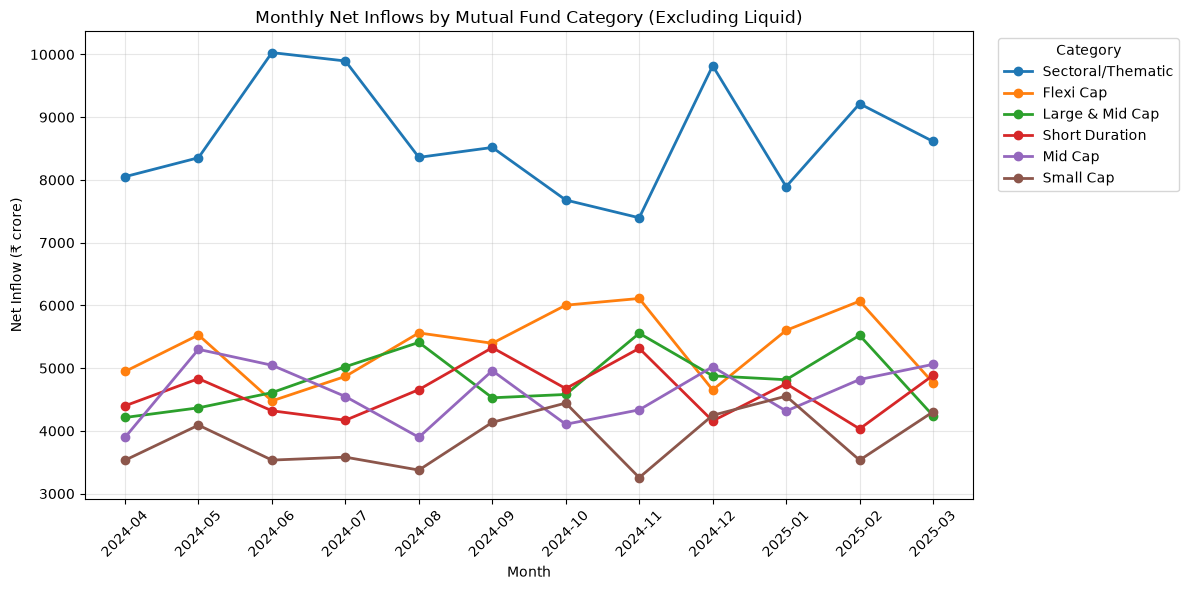

In [130]:
plt.figure(figsize=(12, 6))

for category in top_categories:
    plt.plot(
        top_category_monthly.index,
        top_category_monthly[category],
        marker="o",
        linewidth=2,
        label=category
    )

plt.title("Monthly Net Inflows by Mutual Fund Category (Excluding Liquid)")
plt.xlabel("Month")
plt.ylabel("Net Inflow (₹ crore)")
plt.xticks(rotation=45)
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Monthly Net Inflow Trends by Category

The monthly analysis of six leading non-Liquid mutual fund categories from April 2024 to March 2025 revealed different inflow patterns.

- **Sectoral/Thematic** recorded the highest monthly net inflows throughout the period, peaking at ₹10,030 crore in June 2024 and reaching a low of ₹7,397 crore in November 2024.
- **Flexi Cap** peaked at ₹6,111 crore in November 2024, with another high of ₹6,068 crore in February 2025.
- **Large & Mid Cap** recorded its highest monthly inflow of ₹5,556 crore in November 2024.
- **Mid Cap** peaked at ₹5,300 crore in May 2024.
- **Short Duration** peaked at ₹5,327 crore in September 2024 and reached its lowest value of ₹4,033 crore in February 2025.
- **Small Cap** recorded its lowest monthly inflow of ₹3,256 crore in November 2024.

Overall, the categories showed distinct month-to-month fluctuations rather than a uniform trend. These findings describe the supplied net-inflow figures and do not establish the reasons behind the changes.

In [131]:
category_month_extremes = (
    category_inflows_df
    .loc[
        category_inflows_df.groupby("category")["net_inflow_crore"]
        .idxmax()
    ][["category", "month", "net_inflow_crore"]]
    .rename(columns={
        "month": "highest_inflow_month",
        "net_inflow_crore": "highest_inflow_crore"
    })
    .merge(
        category_inflows_df.loc[
            category_inflows_df.groupby("category")["net_inflow_crore"]
            .idxmin()
        ][["category", "month", "net_inflow_crore"]]
        .rename(columns={
            "month": "lowest_inflow_month",
            "net_inflow_crore": "lowest_inflow_crore"
        }),
        on="category"
    )
    .sort_values("highest_inflow_crore", ascending=False)
    .reset_index(drop=True)
)

display(category_month_extremes.round(2))

,category,highest_inflow_month,highest_inflow_crore,lowest_inflow_month,lowest_inflow_crore
0,Liquid,2024-08,41952.0,2025-02,32374.0
1,Sectoral/Thematic,2024-06,10030.0,2024-11,7397.0
2,Flexi Cap,2024-11,6111.0,2024-06,4478.0
3,Large & Mid Cap,2024-11,5556.0,2024-04,4214.0
4,Short Duration,2024-09,5327.0,2025-02,4033.0
5,Mid Cap,2024-05,5300.0,2024-04,3897.0
6,Small Cap,2025-01,4554.0,2024-11,3256.0
7,Hybrid,2024-08,3684.0,2025-03,2830.0
8,Large Cap,2024-07,2574.0,2024-11,1870.0
9,Value/Contra,2024-10,1595.0,2024-08,1308.0


### Monthly Inflow Extremes by Category

The peak-and-low analysis identified the months with the highest and lowest reported net inflows for each of the 12 mutual fund categories between April 2024 and March 2025.

- Liquid recorded the highest absolute monthly inflow, peaking at ₹41,952 crore in August 2024 and reaching a low of ₹32,374 crore in February 2025.
- Sectoral/Thematic had the highest peak among non-Liquid categories, at ₹10,030 crore in June 2024.
- Flexi Cap and Large & Mid Cap both peaked in November 2024, at ₹6,111 crore and ₹5,556 crore, respectively.
- Small Cap peaked at ₹4,554 crore in January 2025 and reached its lowest value of ₹3,256 crore in November 2024.
- ELSS had the lowest absolute peak and trough, at ₹571 crore in November 2024 and ₹437 crore in February 2025.

The timing of peaks and troughs varied across categories, indicating that monthly inflow patterns were not uniform. These results are descriptive of the supplied dataset and do not explain the causes of the fluctuations.

In [132]:
negative_inflows = category_inflows_df[
    category_inflows_df["net_inflow_crore"] < 0
].sort_values(["category", "month"])

print("Number of negative-inflow rows:", len(negative_inflows))
display(negative_inflows)

Number of negative-inflow rows: 0


,month,category,net_inflow_crore


### Negative Net Inflow Validation

A validation check was performed to identify negative net inflow values across the 144 category-month observations covering April 2024 to March 2025.

- Total observations checked: 144
- Negative net inflow observations: 0
- Validation result: No negative net inflow values were found in the supplied dataset.

This check confirms the absence of negative values in the dataset. It does not independently establish the accuracy or completeness of the reported inflows.

## 7. Portfolio Holdings Analysis

In [133]:
holdings_df = pd.read_csv(RAW_DATA_DIR / "09_portfolio_holdings.csv")

print("Shape:", holdings_df.shape)
print("\nColumns:")
print(holdings_df.columns.tolist())

display(holdings_df.head())

Shape: (322, 8)

Columns:
['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date']


,amfi_code,stock_symbol,stock_name,sector,weight_pct,market_value_cr,current_price_inr,portfolio_date
0,119551,POWERGRID,Power Grid Corporation,Utilities,13.85,737.09,6011.08,2025-12-31
1,119551,HDFCBANK,HDFC Bank Ltd,Banking,11.19,88.97,1074.65,2025-12-31
2,119551,GRASIM,Grasim Industries Ltd,Diversified,9.90,208.45,5964.59,2025-12-31
3,119551,DRREDDY,Dr. Reddy's Laboratories,Pharma,4.76,161.32,3748.82,2025-12-31
4,119551,ASIANPAINT,Asian Paints Ltd,Paints,10.25,725.90,1321.45,2025-12-31


In [134]:
print("Unique fund schemes:", holdings_df["amfi_code"].nunique())
print("Unique stocks:", holdings_df["stock_symbol"].nunique())
print("Unique sectors:", holdings_df["sector"].nunique())
print("Portfolio dates:", holdings_df["portfolio_date"].nunique())

print("\nPortfolio dates:")
display(
    holdings_df["portfolio_date"]
    .value_counts()
    .sort_index()
    .rename("row_count")
    .to_frame()
)

print("\nHoldings per fund:")
display(
    holdings_df.groupby("amfi_code")
    .agg(
        holdings_count=("stock_symbol", "count"),
        unique_stocks=("stock_symbol", "nunique"),
        portfolio_dates=("portfolio_date", "nunique")
    )
    .sort_values("holdings_count", ascending=False)
)

Unique fund schemes: 34
Unique stocks: 30
Unique sectors: 14
Portfolio dates: 1

Portfolio dates:


,row_count
portfolio_date,
2025-12-31,322



Holdings per fund:


,holdings_count,unique_stocks,portfolio_dates
amfi_code,,,
149324,12,12,1
119598,12,12,1
119552,11,11,1
118633,11,11,1
119095,11,11,1
102886,11,11,1
120504,11,11,1
100016,10,10,1
119093,10,10,1


In [135]:
print("Missing values by column:")
display(holdings_df.isna().sum().to_frame("missing_count"))

print(
    "\nDuplicate fund-stock records:",
    holdings_df.duplicated(
        subset=["amfi_code", "stock_symbol"]
    ).sum()
)

print(
    "\nWeights <= 0:",
    (holdings_df["weight_pct"] <= 0).sum()
)

print(
    "Weights > 100:",
    (holdings_df["weight_pct"] > 100).sum()
)

print("\nNumeric column summary:")
display(
    holdings_df[
        ["weight_pct", "market_value_cr", "current_price_inr"]
    ].describe().round(2)
)

Missing values by column:


,missing_count
amfi_code,0
stock_symbol,0
stock_name,0
sector,0
weight_pct,0
market_value_cr,0
current_price_inr,0
portfolio_date,0



Duplicate fund-stock records: 0

Weights <= 0: 0
Weights > 100: 0

Numeric column summary:


,weight_pct,market_value_cr,current_price_inr
count,322.00,322.00,322.00
mean,10.56,1008.85,4080.87
std,6.06,543.83,2265.19
min,0.99,55.74,246.78
25%,6.02,513.70,2081.98
50%,9.40,1045.67,4139.00
75%,13.92,1477.50,5914.31
max,38.18,1999.50,7942.96


In [136]:
fund_weight_summary = (
    holdings_df.groupby("amfi_code", as_index=False)
    .agg(
        holdings_count=("stock_symbol", "nunique"),
        total_listed_weight_pct=("weight_pct", "sum"),
        total_listed_market_value_cr=("market_value_cr", "sum")
    )
    .sort_values("total_listed_weight_pct", ascending=False)
    .reset_index(drop=True)
)

display(fund_weight_summary.round(2))

print(
    "\nFunds with listed weights above 100%:",
    (fund_weight_summary["total_listed_weight_pct"] > 100).sum()
)

print(
    "Funds with listed weights below 100%:",
    (fund_weight_summary["total_listed_weight_pct"] < 100).sum()
)

,amfi_code,holdings_count,total_listed_weight_pct,total_listed_market_value_cr
0,118632,8,100.02,8614.35
1,120505,8,100.02,4869.31
2,120506,9,100.02,9865.87
3,120841,10,100.01,13663.82
4,120504,11,100.01,12844.50
5,101206,10,100.01,9685.28
6,119552,11,100.01,8183.78
7,119094,9,100.01,10147.79
8,102887,10,100.01,11535.15
9,100016,10,100.00,6620.93



Funds with listed weights above 100%: 9
Funds with listed weights below 100%: 11


In [137]:
sector_summary = (
    holdings_df.groupby("sector", as_index=False)
    .agg(
        holding_records=("stock_symbol", "count"),
        unique_stocks=("stock_symbol", "nunique"),
        total_listed_weight_pct=("weight_pct", "sum"),
        average_holding_weight_pct=("weight_pct", "mean")
    )
    .sort_values("total_listed_weight_pct", ascending=False)
    .reset_index(drop=True)
)

display(sector_summary.round(2))

,sector,holding_records,unique_stocks,total_listed_weight_pct,average_holding_weight_pct
0,Banking,60,6,652.26,10.87
1,IT,40,4,455.47,11.39
2,Pharma,38,4,407.45,10.72
3,Automobile,33,3,323.65,9.81
4,Utilities,24,2,265.54,11.06
5,FMCG,21,2,229.11,10.91
6,Infrastructure,22,2,192.16,8.73
7,Diversified,14,1,169.23,12.09
8,Telecom,15,1,145.62,9.71
9,Consumer Goods,9,1,127.61,14.18


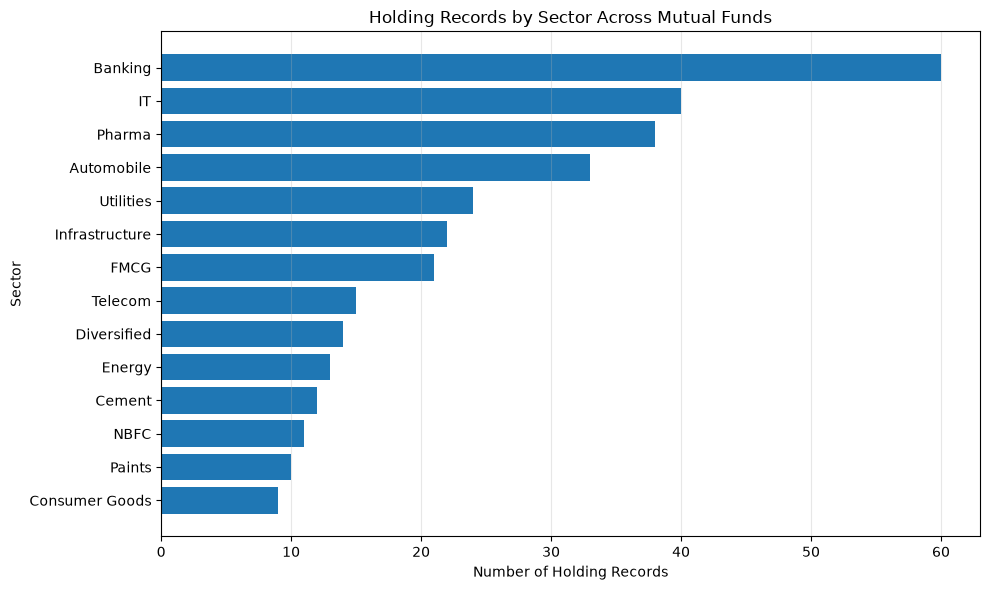

In [138]:
plt.figure(figsize=(10, 6))

plot_data = sector_summary.sort_values("holding_records")

plt.barh(
    plot_data["sector"],
    plot_data["holding_records"]
)

plt.title("Holding Records by Sector Across Mutual Funds")
plt.xlabel("Number of Holding Records")
plt.ylabel("Sector")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [139]:
stock_frequency = (
    holdings_df.groupby(
        ["stock_symbol", "stock_name", "sector"],
        as_index=False
    )
    .agg(
        fund_count=("amfi_code", "nunique"),
        average_weight_pct=("weight_pct", "mean"),
        total_listed_weight_pct=("weight_pct", "sum")
    )
    .sort_values(
        ["fund_count", "total_listed_weight_pct"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(stock_frequency.head(15).round(2))

,stock_symbol,stock_name,sector,fund_count,average_weight_pct,total_listed_weight_pct
0,BHARTIARTL,Bharti Airtel Ltd,Telecom,15,9.71,145.62
1,GRASIM,Grasim Industries Ltd,Diversified,14,12.09,169.23
2,NTPC,NTPC Ltd,Utilities,13,11.93,155.15
3,HCLTECH,HCL Technologies Ltd,IT,13,11.32,147.17
4,ICICIBANK,ICICI Bank Ltd,Banking,13,9.39,122.06
5,RELIANCE,Reliance Industries Ltd,Energy,13,9.07,117.91
6,AXISBANK,Axis Bank Ltd,Banking,12,12.56,150.75
7,TATAMOTOR,Tata Motors Ltd,Automobile,12,9.56,114.68
8,ULTRACEMCO,UltraTech Cement Ltd,Cement,12,8.75,105.03
9,ADANIPORT,Adani Ports & SEZ Ltd,Infrastructure,12,8.47,101.63


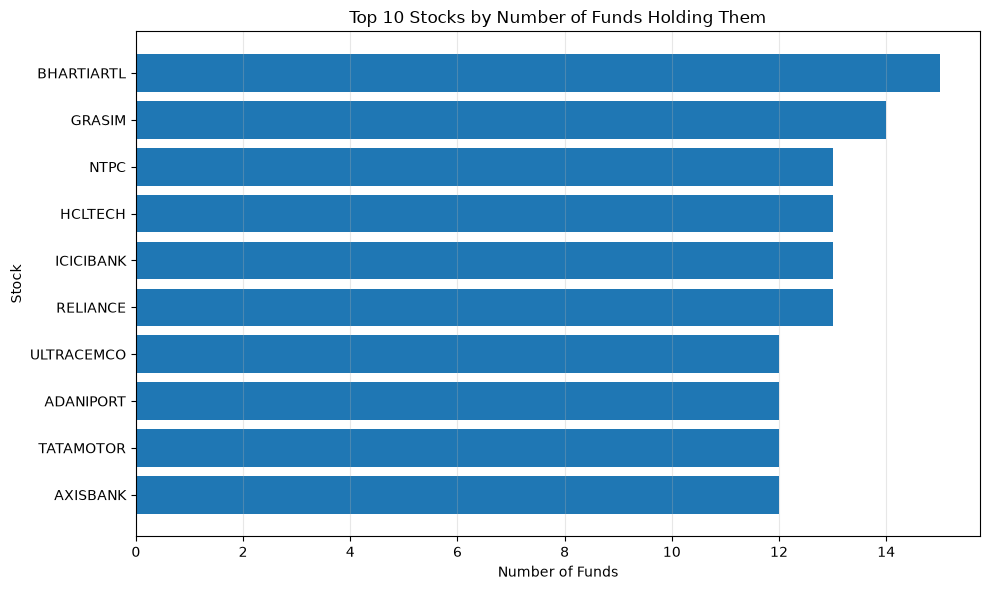

In [140]:
plt.figure(figsize=(10, 6))

plot_data = (
    stock_frequency
    .head(10)
    .sort_values("fund_count")
)

plt.barh(
    plot_data["stock_symbol"],
    plot_data["fund_count"]
)

plt.title("Top 10 Stocks by Number of Funds Holding Them")
plt.xlabel("Number of Funds")
plt.ylabel("Stock")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [141]:
stock_weight_analysis = (
    holdings_df.groupby(
        ["stock_symbol", "stock_name", "sector"],
        as_index=False
    )
    .agg(
        fund_count=("amfi_code", "nunique"),
        average_weight_pct=("weight_pct", "mean"),
        maximum_weight_pct=("weight_pct", "max"),
        minimum_weight_pct=("weight_pct", "min")
    )
    .sort_values("average_weight_pct", ascending=False)
    .reset_index(drop=True)
)

display(stock_weight_analysis.head(15).round(2))

,stock_symbol,stock_name,sector,fund_count,average_weight_pct,maximum_weight_pct,minimum_weight_pct
0,TITAN,Titan Company Ltd,Consumer Goods,9,14.18,20.91,6.11
1,SBIN,State Bank of India,Banking,8,12.60,28.61,3.88
2,AXISBANK,Axis Bank Ltd,Banking,12,12.56,20.73,4.77
3,WIPRO,Wipro Ltd,IT,11,12.26,25.90,3.73
4,GRASIM,Grasim Industries Ltd,Diversified,14,12.09,28.25,0.99
5,NTPC,NTPC Ltd,Utilities,13,11.93,28.95,2.04
6,SUNPHARMA,Sun Pharmaceutical Industries,Pharma,10,11.88,35.07,2.55
7,INFY,Infosys Ltd,IT,11,11.71,38.18,3.19
8,HINDUNILVR,Hindustan Unilever Ltd,FMCG,11,11.44,23.17,3.53
9,HCLTECH,HCL Technologies Ltd,IT,13,11.32,18.22,4.34


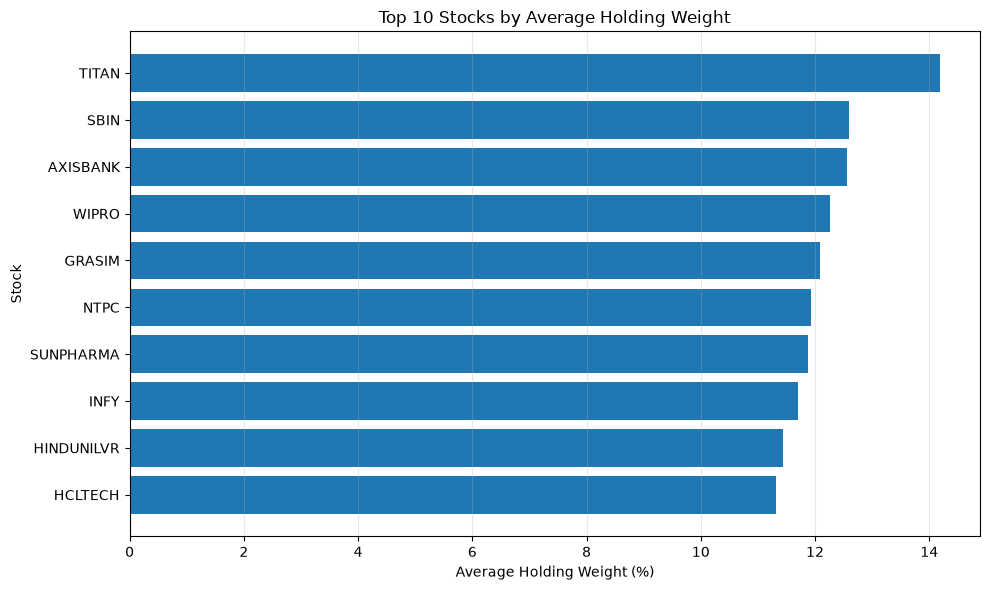

In [142]:
plt.figure(figsize=(10, 6))

plot_data = (
    stock_weight_analysis
    .head(10)
    .sort_values("average_weight_pct")
)

plt.barh(
    plot_data["stock_symbol"],
    plot_data["average_weight_pct"]
)

plt.title("Top 10 Stocks by Average Holding Weight")
plt.xlabel("Average Holding Weight (%)")
plt.ylabel("Stock")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [143]:
top3_concentration = (
    holdings_df
    .sort_values(
        ["amfi_code", "weight_pct"],
        ascending=[True, False]
    )
    .groupby("amfi_code")
    .head(3)
    .groupby("amfi_code", as_index=False)
    .agg(
        top3_weight_pct=("weight_pct", "sum"),
        top3_holdings_count=("stock_symbol", "nunique")
    )
    .sort_values("top3_weight_pct", ascending=False)
    .reset_index(drop=True)
)

display(top3_concentration.round(2))

print("\nSummary statistics:")
display(top3_concentration["top3_weight_pct"].describe().round(2))

,amfi_code,top3_weight_pct,top3_holdings_count
0,101207,66.34,3
1,102885,65.02,3
2,119092,64.84,3
3,119599,62.33,3
4,120841,61.18,3
5,120506,60.81,3
6,148568,60.76,3
7,120505,58.41,3
8,125498,58.27,3
9,118632,56.27,3



Summary statistics:


count    34.00
mean     52.73
std       6.84
min      38.17
25%      47.80
50%      51.79
75%      57.77
max      66.34
Name: top3_weight_pct, dtype: float64

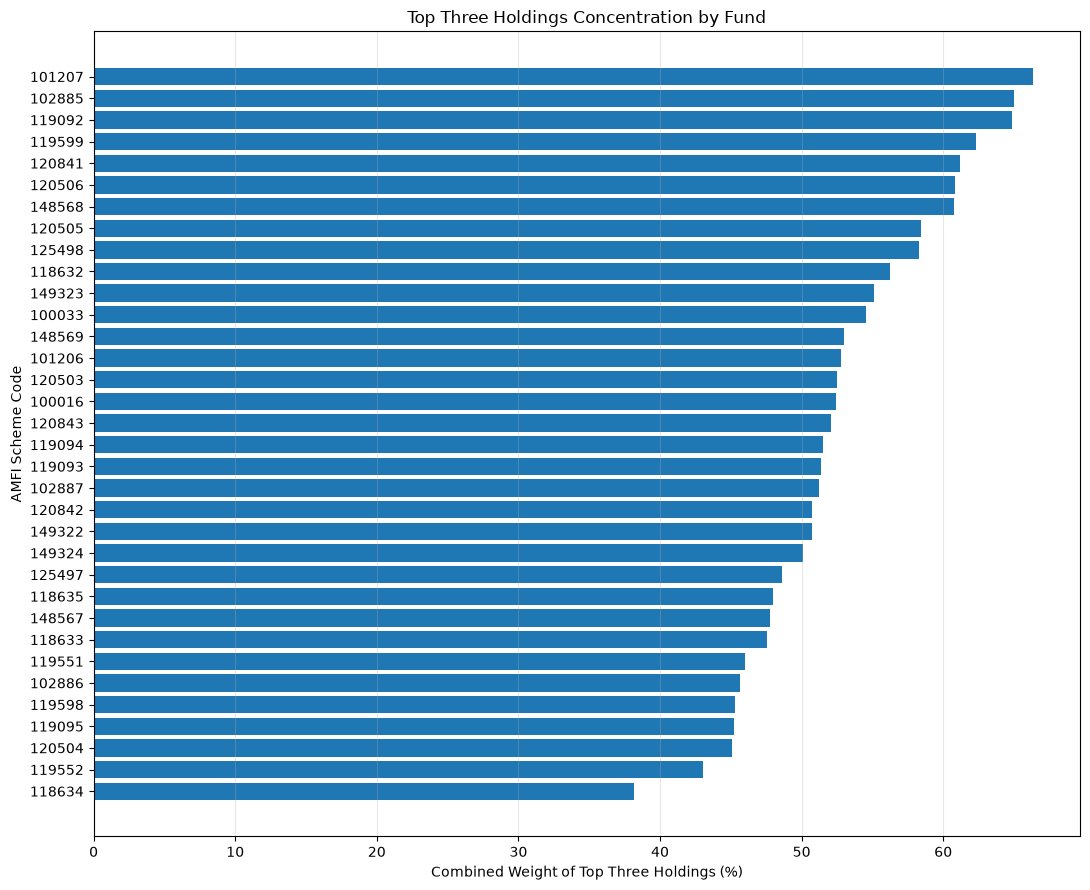

In [144]:
plt.figure(figsize=(11, 9))

plot_data = top3_concentration.sort_values("top3_weight_pct")

plt.barh(
    plot_data["amfi_code"].astype(str),
    plot_data["top3_weight_pct"]
)

plt.title("Top Three Holdings Concentration by Fund")
plt.xlabel("Combined Weight of Top Three Holdings (%)")
plt.ylabel("AMFI Scheme Code")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Fund-Level Top-Three Holdings Concentration

The combined weight of the three largest holdings was calculated for each of the 34 funds using the portfolio snapshot dated 31 December 2025.

- **Average top-three weight:** 52.73%
- **Median top-three weight:** 51.79%
- **Standard deviation:** 6.84 percentage points
- **Highest concentration:** 66.34% for fund code 101207
- **Lowest concentration:** 38.17% for fund code 118634

The results indicate that the three largest holdings account for a substantial share of listed portfolio weight in many funds. However, top-three concentration alone does not determine overall investment risk, which also depends on the holdings' characteristics, sector exposures, and other portfolio factors.

The analysis is based on a single portfolio snapshot and should not be interpreted as a measure of changes in concentration over time.

In [145]:
print([
    name for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
])

['df_sample', 'dataset_inventory', 'df', 'quality_summary', 'sip_df', 'blank_summary', 'column_profile', 'date_check_results', 'numeric_summary', 'numeric_df', 'performance_df', 'drawdown_check', 'performance_numeric', 'performance_stats', 'fund_master_df', 'benchmark_df', 'benchmark_returns', 'fund_benchmarks', 'benchmark_mapping', 'nav_df', 'nav_coverage', 'nav_dates', 'fund_returns', 'comparison', 'comparison_summary', 'largest_differences', 'largest_absolute_differences', 'fund_date_check', 'nav_movements', 'largest_movements', 'extreme_keys', 'nav_context', 'fund_history', 'context', 'nav_context_check', '_40', 'extreme_changes', '_43', 'fund_volatility', 'fund_details', 'volatility_with_names', 'category_volatility', 'plot_data', 'raw_benchmark', 'benchmark_returns_check', 'benchmark_coverage', 'coverage_summary', 'nav_sorted', 'gap_summary', 'nav_with_category', 'subcategory_volatility', 'fund_cumulative_returns', '_66', 'sbi_small_cap_nav', 'scheme_nav', 'sbi_plan_comparison', 

In [146]:
print("Fund master shape:", fund_master_df.shape)
print("Fund master columns:")
print(fund_master_df.columns.tolist())

display(fund_master_df.head())

Fund master shape: (40, 15)
Fund master columns:
['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category', 'plan', 'launch_date', 'benchmark', 'expense_ratio_pct', 'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager', 'risk_category', 'sebi_category_code']


,amfi_code,fund_house,scheme_name,category,sub_category,plan,launch_date,benchmark,expense_ratio_pct,exit_load_pct,min_sip_amount,min_lumpsum_amount,fund_manager,risk_category,sebi_category_code
0,119551,SBI Mutual Fund,SBI Bluechip Fund - Regular Plan - Growth,Equity,Large Cap,Regular,2006-02-14,NIFTY 100 TRI,1.54,1.0,500,1000,Sohini Andani,Moderate,EC01
1,119552,SBI Mutual Fund,SBI Bluechip Fund - Direct Plan - Growth,Equity,Large Cap,Direct,2013-01-01,NIFTY 100 TRI,0.66,1.0,500,1000,Sohini Andani,Moderate,EC01
2,119598,SBI Mutual Fund,SBI Small Cap Fund - Regular Plan - Growth,Equity,Small Cap,Regular,2009-09-09,BSE 250 SmallCap TRI,1.43,1.0,500,1000,R. Srinivasan,Very High,EC03
3,119599,SBI Mutual Fund,SBI Small Cap Fund - Direct Plan - Growth,Equity,Small Cap,Direct,2013-01-01,BSE 250 SmallCap TRI,0.72,1.0,500,1000,R. Srinivasan,Very High,EC03
4,119120,SBI Mutual Fund,SBI Magnum Gilt Fund - Regular Plan - Growth,Debt,Gilt,Regular,2000-12-30,CRISIL Dynamic Gilt Index,0.77,0.0,500,1000,Dinesh Ahuja,Low,DC02


In [147]:
print("Fund master unique AMFI codes:",
      fund_master_df["amfi_code"].nunique())

print("Holdings unique AMFI codes:",
      holdings_df["amfi_code"].nunique())

print("Duplicate AMFI codes in fund master:",
      fund_master_df["amfi_code"].duplicated().sum())

unmatched_codes = sorted(
    set(holdings_df["amfi_code"])
    - set(fund_master_df["amfi_code"])
)

print("Unmatched holdings codes:", unmatched_codes)

Fund master unique AMFI codes: 40
Holdings unique AMFI codes: 34
Duplicate AMFI codes in fund master: 0
Unmatched holdings codes: []


In [148]:
fund_names = fund_master_df[
    ["amfi_code", "scheme_name", "fund_house", "sub_category", "plan"]
]

top3_concentration_named = top3_concentration.merge(
    fund_names,
    on="amfi_code",
    how="left",
    validate="one_to_one"
)

top3_concentration_named = top3_concentration_named[
    [
        "amfi_code",
        "scheme_name",
        "fund_house",
        "sub_category",
        "plan",
        "top3_weight_pct",
        "top3_holdings_count"
    ]
]

display(top3_concentration_named.round(2))

,amfi_code,scheme_name,fund_house,sub_category,plan,top3_weight_pct,top3_holdings_count
0,101207,ABSL Small Cap Fund - Regular - Growth,Aditya Birla Sun Life MF,Small Cap,Regular,66.34,3
1,102885,UTI Nifty 50 Index Fund - Regular - Growth,UTI Mutual Fund,Index,Regular,65.02,3
2,119092,Axis Bluechip Fund - Regular - Growth,Axis Mutual Fund,Large Cap,Regular,64.84,3
3,119599,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,Small Cap,Direct,62.33,3
4,120841,Kotak Bluechip Fund - Regular - Growth,Kotak Mahindra MF,Large Cap,Regular,61.18,3
5,120506,ICICI Pru Value Discovery Fund - Regular - Growth,ICICI Prudential MF,Value,Regular,60.81,3
6,148568,Mirae Asset Emerging Bluechip Fund - Regular -...,Mirae Asset MF,Large & Mid Cap,Regular,60.76,3
7,120505,ICICI Pru Midcap Fund - Regular - Growth,ICICI Prudential MF,Mid Cap,Regular,58.41,3
8,125498,HDFC Mid-Cap Opportunities Fund - Direct - Growth,HDFC Mutual Fund,Mid Cap,Direct,58.27,3
9,118632,Nippon India Large Cap Fund - Regular - Growth,Nippon India MF,Large Cap,Regular,56.27,3


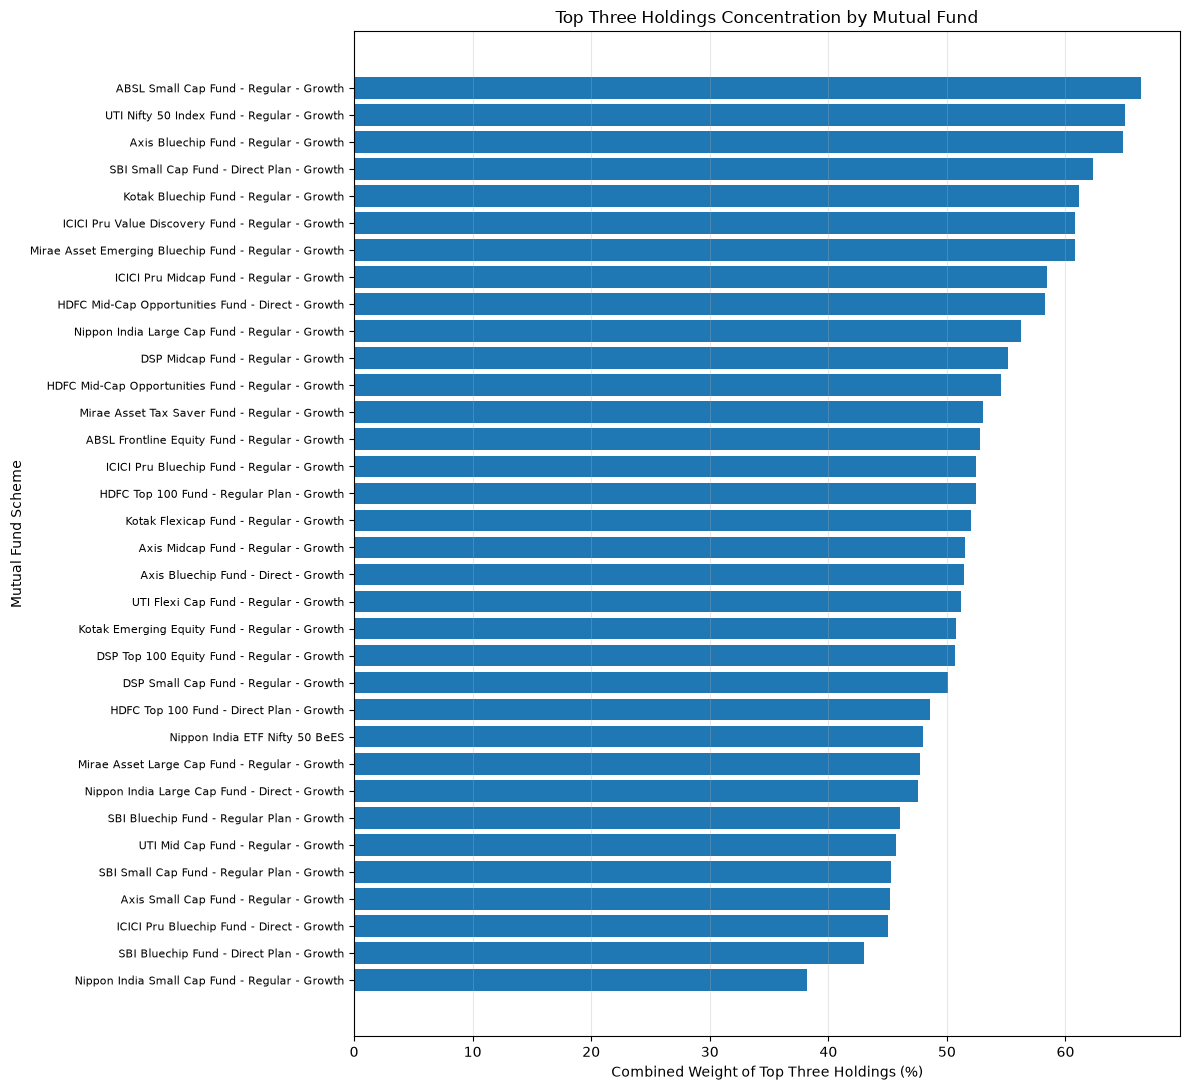

In [149]:
plt.figure(figsize=(12, 11))

plot_data = top3_concentration_named.sort_values("top3_weight_pct")

plt.barh(
    plot_data["scheme_name"],
    plot_data["top3_weight_pct"]
)

plt.title("Top Three Holdings Concentration by Mutual Fund")
plt.xlabel("Combined Weight of Top Three Holdings (%)")
plt.ylabel("Mutual Fund Scheme")
plt.yticks(fontsize=8)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [150]:
fund_sector_weights = (
    holdings_df.groupby(
        ["amfi_code", "sector"],
        as_index=False
    )
    .agg(
        sector_weight_pct=("weight_pct", "sum")
    )
    .merge(
        fund_master_df[
            ["amfi_code", "scheme_name", "sub_category", "plan"]
        ],
        on="amfi_code",
        how="left",
        validate="many_to_one"
    )
    .sort_values(
        ["amfi_code", "sector_weight_pct"],
        ascending=[True, False]
    )
)

display(fund_sector_weights.head(20).round(2))

,amfi_code,sector,sector_weight_pct,scheme_name,sub_category,plan
4,100016,IT,25.90,HDFC Top 100 Fund - Regular Plan - Growth,Large Cap,Regular
6,100016,Pharma,25.48,HDFC Top 100 Fund - Regular Plan - Growth,Large Cap,Regular
0,100016,Automobile,14.84,HDFC Top 100 Fund - Regular Plan - Growth,Large Cap,Regular
3,100016,FMCG,11.68,HDFC Top 100 Fund - Regular Plan - Growth,Large Cap,Regular
5,100016,NBFC,7.01,HDFC Top 100 Fund - Regular Plan - Growth,Large Cap,Regular
2,100016,Energy,6.09,HDFC Top 100 Fund - Regular Plan - Growth,Large Cap,Regular
7,100016,Utilities,5.61,HDFC Top 100 Fund - Regular Plan - Growth,Large Cap,Regular
1,100016,Banking,3.39,HDFC Top 100 Fund - Regular Plan - Growth,Large Cap,Regular
9,100033,Banking,35.97,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Mid Cap,Regular
8,100033,Automobile,26.07,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Mid Cap,Regular


In [151]:
largest_sector_by_fund = (
    fund_sector_weights
    .sort_values(
        ["amfi_code", "sector_weight_pct"],
        ascending=[True, False]
    )
    .groupby("amfi_code")
    .head(1)
    .sort_values("sector_weight_pct", ascending=False)
    .reset_index(drop=True)
)

display(
    largest_sector_by_fund[
        [
            "scheme_name",
            "sub_category",
            "plan",
            "sector",
            "sector_weight_pct"
        ]
    ].round(2)
)

,scheme_name,sub_category,plan,sector,sector_weight_pct
0,Axis Bluechip Fund - Regular - Growth,Large Cap,Regular,IT,48.69
1,DSP Midcap Fund - Regular - Growth,Mid Cap,Regular,Pharma,41.34
2,HDFC Mid-Cap Opportunities Fund - Direct - Growth,Mid Cap,Direct,Banking,41.20
3,ICICI Pru Midcap Fund - Regular - Growth,Mid Cap,Regular,Pharma,40.75
4,Mirae Asset Tax Saver Fund - Regular - Growth,ELSS,Regular,Banking,39.82
5,Nippon India ETF Nifty 50 BeES,Index/ETF,Direct,IT,39.35
6,UTI Flexi Cap Fund - Regular - Growth,Flexi Cap,Regular,Pharma,39.04
7,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Mid Cap,Regular,Banking,35.97
8,ICICI Pru Bluechip Fund - Direct - Growth,Large Cap,Direct,Banking,35.61
9,ABSL Small Cap Fund - Regular - Growth,Small Cap,Regular,Pharma,35.07


In [152]:
dominant_sector_counts = (
    largest_sector_by_fund
    .groupby("sector", as_index=False)
    .agg(
        fund_count=("amfi_code", "nunique"),
        average_dominant_weight_pct=("sector_weight_pct", "mean")
    )
    .sort_values("fund_count", ascending=False)
    .reset_index(drop=True)
)

display(dominant_sector_counts.round(2))

,sector,fund_count,average_dominant_weight_pct
0,Banking,11,33.60
1,IT,7,31.95
2,Pharma,6,36.03
3,FMCG,3,26.36
4,Utilities,3,23.41
5,Automobile,2,29.57
6,Consumer Goods,1,18.99
7,Telecom,1,30.44


### Distribution of Dominant Sectors Across Funds

The largest sector allocation was identified for each of the 34 funds in the portfolio holdings dataset dated 31 December 2025.

- Banking was the dominant sector in 11 funds.
- IT was dominant in 7 funds.
- Pharma was dominant in 6 funds.
- FMCG and Utilities were each dominant in 3 funds.
- Automobile was dominant in 2 funds.
- Consumer Goods and Telecom were each dominant in 1 fund.

Banking, IT, and Pharma together represented the dominant sector in 24 of the 34 funds (70.6%). This describes the frequency of each sector as the largest allocation; it does not represent total sector exposure across all portfolios or establish the relative risk of the funds.

## 8. Benchmark Performance and Risk

In [153]:
benchmark_indices_df = pd.read_csv(
    RAW_DATA_DIR / "10_benchmark_indices.csv"
)

print("Shape:", benchmark_indices_df.shape)
print("Columns:", benchmark_indices_df.columns.tolist())

display(benchmark_indices_df.head())

Shape: (8050, 3)
Columns: ['date', 'index_name', 'close_value']


,date,index_name,close_value
0,2022-01-03,NIFTY50,17492.79
1,2022-01-04,NIFTY50,17689.64
2,2022-01-05,NIFTY50,17835.05
3,2022-01-06,NIFTY50,17878.51
4,2022-01-07,NIFTY50,17759.15


In [154]:
print("Unique indices:", benchmark_indices_df["index_name"].nunique())
print("Date range:",
      benchmark_indices_df["date"].min(),
      "to",
      benchmark_indices_df["date"].max())

print("\nRows per index:")
display(
    benchmark_indices_df.groupby("index_name")
    .agg(
        row_count=("date", "count"),
        unique_dates=("date", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .sort_values("row_count", ascending=False)
)

print("\nMissing values:")
display(benchmark_indices_df.isna().sum().to_frame("missing_count"))

print(
    "\nDuplicate index-date records:",
    benchmark_indices_df.duplicated(
        subset=["index_name", "date"]
    ).sum()
)

print(
    "Non-positive closing values:",
    (benchmark_indices_df["close_value"] <= 0).sum()
)

Unique indices: 7
Date range: 2022-01-03 to 2026-05-29

Rows per index:


,row_count,unique_dates,first_date,last_date
index_name,,,,
BSE_SMALLCAP,1150,1150,2022-01-03,2026-05-29
CRISIL_GILT,1150,1150,2022-01-03,2026-05-29
CRISIL_LIQUID,1150,1150,2022-01-03,2026-05-29
NIFTY100,1150,1150,2022-01-03,2026-05-29
NIFTY50,1150,1150,2022-01-03,2026-05-29
NIFTY500,1150,1150,2022-01-03,2026-05-29
NIFTY_MIDCAP150,1150,1150,2022-01-03,2026-05-29



Missing values:


,missing_count
date,0
index_name,0
close_value,0



Duplicate index-date records: 0
Non-positive closing values: 0


In [155]:
benchmark_indices_df["date"] = pd.to_datetime(
    benchmark_indices_df["date"]
)

benchmark_indices_df = benchmark_indices_df.sort_values(
    ["index_name", "date"]
).copy()

benchmark_indices_df["daily_return_pct"] = (
    benchmark_indices_df
    .groupby("index_name")["close_value"]
    .pct_change() * 100
)

print("Daily return summary by index:")

display(
    benchmark_indices_df.groupby("index_name")["daily_return_pct"]
    .agg(["mean", "std", "min", "max"])
    .round(3)
)

print("\nLargest absolute daily movements:")

display(
    benchmark_indices_df.loc[
        benchmark_indices_df["daily_return_pct"].abs().nlargest(15).index,
        ["date", "index_name", "close_value", "daily_return_pct"]
    ].sort_values(
        "daily_return_pct",
        key=lambda values: values.abs(),
        ascending=False
    ).round(3)
)

Daily return summary by index:


,mean,std,min,max
index_name,,,,
BSE_SMALLCAP,0.104,1.395,-3.972,4.185
CRISIL_GILT,0.041,0.260,-0.744,0.821
CRISIL_LIQUID,0.025,0.033,-0.078,0.126
NIFTY100,0.012,0.812,-2.687,2.679
NIFTY50,0.008,0.811,-2.377,2.307
NIFTY500,0.085,0.873,-2.862,3.102
NIFTY_MIDCAP150,0.112,1.123,-3.575,3.523



Largest absolute daily movements:


C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\410829430.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(3)


,date,index_name,close_value,daily_return_pct
3668,2022-11-03,BSE_SMALLCAP,27752.52,4.185
4429,2025-10-03,BSE_SMALLCAP,58518.22,-3.972
3454,2022-01-07,BSE_SMALLCAP,26316.86,-3.873
3587,2022-07-13,BSE_SMALLCAP,26937.51,3.854
3638,2022-09-22,BSE_SMALLCAP,25841.96,-3.803
3709,2022-12-30,BSE_SMALLCAP,26829.94,-3.731
3672,2022-11-09,BSE_SMALLCAP,27622.31,-3.724
4185,2024-10-28,BSE_SMALLCAP,32098.90,3.721
3698,2022-12-15,BSE_SMALLCAP,26985.68,-3.691
3703,2022-12-22,BSE_SMALLCAP,27974.84,3.625


In [156]:
bse_smallcap = (
    benchmark_indices_df[
        benchmark_indices_df["index_name"] == "BSE_SMALLCAP"
    ]
    .sort_values("date")
    .copy()
)

top_bse_dates = (
    bse_smallcap["daily_return_pct"]
    .abs()
    .nlargest(5)
    .index
)

bse_context = []

for idx in top_bse_dates:
    position = bse_smallcap.index.get_loc(idx)

    start = max(0, position - 1)
    end = min(len(bse_smallcap), position + 2)

    bse_context.append(
        bse_smallcap.iloc[start:end][
            ["date", "close_value", "daily_return_pct"]
        ]
    )

display(
    pd.concat(bse_context)
    .drop_duplicates()
    .sort_values("date")
    .round(3)
)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\3604447830.py:34: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,date,close_value,daily_return_pct
3453,2022-01-06,27377.05,0.233
3454,2022-01-07,26316.86,-3.873
3455,2022-01-10,26476.06,0.605
3586,2022-07-12,25937.88,1.109
3587,2022-07-13,26937.51,3.854
3588,2022-07-14,27801.44,3.207
3637,2022-09-21,26863.67,0.081
3638,2022-09-22,25841.96,-3.803
3639,2022-09-23,25743.31,-0.382
3667,2022-11-02,26637.64,-0.234


In [157]:
benchmark_return_stats = (
    benchmark_indices_df.groupby("index_name")["daily_return_pct"]
    .agg(
        mean_daily_return_pct="mean",
        median_daily_return_pct="median",
        daily_volatility_pct="std",
        minimum_return_pct="min",
        maximum_return_pct="max"
    )
    .sort_values("daily_volatility_pct", ascending=False)
)

display(benchmark_return_stats.round(3))

,mean_daily_return_pct,median_daily_return_pct,daily_volatility_pct,minimum_return_pct,maximum_return_pct
index_name,,,,,
BSE_SMALLCAP,0.104,0.081,1.395,-3.972,4.185
NIFTY_MIDCAP150,0.112,0.107,1.123,-3.575,3.523
NIFTY500,0.085,0.082,0.873,-2.862,3.102
NIFTY100,0.012,-0.011,0.812,-2.687,2.679
NIFTY50,0.008,-0.021,0.811,-2.377,2.307
CRISIL_GILT,0.041,0.042,0.260,-0.744,0.821
CRISIL_LIQUID,0.025,0.027,0.033,-0.078,0.126


In [158]:
benchmark_performance = (
    benchmark_indices_df.sort_values(["index_name", "date"])
    .groupby("index_name")
    .agg(
        start_date=("date", "first"),
        end_date=("date", "last"),
        starting_close=("close_value", "first"),
        ending_close=("close_value", "last")
    )
    .reset_index()
)

benchmark_performance["cumulative_change_pct"] = (
    (
        benchmark_performance["ending_close"]
        / benchmark_performance["starting_close"]
    ) - 1
) * 100

benchmark_performance = benchmark_performance.sort_values(
    "cumulative_change_pct",
    ascending=False
)

display(benchmark_performance.round(2))

C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\1562116854.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(benchmark_performance.round(2))


,index_name,start_date,end_date,starting_close,ending_close,cumulative_change_pct
6,NIFTY_MIDCAP150,2022-01-03,2026-05-29,9721.79,32763.85,237.01
0,BSE_SMALLCAP,2022-01-03,2026-05-29,26554.60,78367.62,195.12
5,NIFTY500,2022-01-03,2026-05-29,14837.07,37680.76,153.96
1,CRISIL_GILT,2022-01-03,2026-05-29,1451.06,2302.79,58.70
2,CRISIL_LIQUID,2022-01-03,2026-05-29,2281.51,3046.00,33.51
3,NIFTY100,2022-01-03,2026-05-29,17778.24,19696.29,10.79
4,NIFTY50,2022-01-03,2026-05-29,17492.79,18517.65,5.86


In [159]:
benchmark_yearly = benchmark_indices_df.copy()

benchmark_yearly["year"] = benchmark_yearly["date"].dt.year

year_end_values = (
    benchmark_yearly
    .sort_values("date")
    .groupby(["index_name", "year"])
    .agg(
        first_date=("date", "first"),
        first_close=("close_value", "first"),
        last_date=("date", "last"),
        last_close=("close_value", "last")
    )
    .reset_index()
)

year_end_values["period_change_pct"] = (
    (year_end_values["last_close"] / year_end_values["first_close"] - 1)
    * 100
)

display(year_end_values.round(2))

C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\3902950688.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(year_end_values.round(2))


,index_name,year,first_date,first_close,last_date,last_close,period_change_pct
0,BSE_SMALLCAP,2022,2022-01-03,26554.60,2022-12-30,26829.94,1.04
1,BSE_SMALLCAP,2023,2023-01-02,26319.71,2023-12-29,27922.20,6.09
2,BSE_SMALLCAP,2024,2024-01-01,27361.38,2024-12-31,39942.39,45.98
3,BSE_SMALLCAP,2025,2025-01-01,40085.12,2025-12-31,70687.19,76.34
4,BSE_SMALLCAP,2026,2026-01-01,71124.08,2026-05-29,78367.62,10.18
5,CRISIL_GILT,2022,2022-01-03,1451.06,2022-12-30,1515.87,4.47
6,CRISIL_GILT,2023,2023-01-02,1512.14,2023-12-29,1712.08,13.22
7,CRISIL_GILT,2024,2024-01-01,1715.79,2024-12-31,1939.04,13.01
8,CRISIL_GILT,2025,2025-01-01,1941.13,2025-12-31,2151.10,10.82
9,CRISIL_GILT,2026,2026-01-01,2156.03,2026-05-29,2302.79,6.81


In [160]:
for index in ["NIFTY50", "NIFTY100"]:
    print(f"\n--- {index}: first and last observations ---")

    index_data = (
        benchmark_indices_df[
            benchmark_indices_df["index_name"] == index
        ]
        .sort_values("date")
    )

    display(pd.concat([
        index_data.head(5),
        index_data.tail(5)
    ]))

    print(f"\n--- {index}: largest absolute daily moves ---")

    display(
        index_data.loc[
            index_data["daily_return_pct"].abs().nlargest(10).index,
            ["date", "close_value", "daily_return_pct"]
        ]
        .sort_values(
            "daily_return_pct",
            key=lambda x: x.abs(),
            ascending=False
        )
        .round(3)
    )


--- NIFTY50: first and last observations ---


,date,index_name,close_value,daily_return_pct
0,2022-01-03,NIFTY50,17492.79,NaN
1,2022-01-04,NIFTY50,17689.64,1.125321
2,2022-01-05,NIFTY50,17835.05,0.822007
3,2022-01-06,NIFTY50,17878.51,0.243677
4,2022-01-07,NIFTY50,17759.15,-0.667617
1145,2026-05-25,NIFTY50,18186.57,-1.120071
1146,2026-05-26,NIFTY50,18418.36,1.274512
1147,2026-05-27,NIFTY50,18523.57,0.571223
1148,2026-05-28,NIFTY50,18421.08,-0.553295
1149,2026-05-29,NIFTY50,18517.65,0.524236



--- NIFTY50: largest absolute daily moves ---


C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\2015090183.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,date,close_value,daily_return_pct
474,2023-10-27,26688.69,-2.377
867,2025-04-30,19952.62,2.307
65,2022-04-04,20065.60,2.303
558,2024-02-22,26881.80,2.288
125,2022-06-27,19287.24,-2.285
62,2022-03-30,19568.64,2.250
813,2025-02-13,20650.30,-2.231
1040,2025-12-29,18723.63,2.229
130,2022-07-04,18769.89,-2.163
986,2025-10-14,20038.20,2.145



--- NIFTY100: first and last observations ---


,date,index_name,close_value,daily_return_pct
1150,2022-01-03,NIFTY100,17778.24,NaN
1151,2022-01-04,NIFTY100,17537.52,-1.354015
1152,2022-01-05,NIFTY100,17607.73,0.400342
1153,2022-01-06,NIFTY100,17556.05,-0.293507
1154,2022-01-07,NIFTY100,17664.02,0.615002
2295,2026-05-25,NIFTY100,19245.64,0.273170
2296,2026-05-26,NIFTY100,19228.08,-0.091241
2297,2026-05-27,NIFTY100,19489.24,1.358222
2298,2026-05-28,NIFTY100,19677.97,0.968381
2299,2026-05-29,NIFTY100,19696.29,0.093099



--- NIFTY100: largest absolute daily moves ---


C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\2015090183.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,date,close_value,daily_return_pct
1501,2023-05-09,15223.57,-2.687
1191,2022-03-01,17708.25,2.679
1905,2024-11-25,15010.84,2.484
1863,2024-09-26,14853.80,-2.370
1560,2023-07-31,16487.10,2.332
1953,2025-01-30,15827.04,2.272
2254,2026-03-27,18461.52,2.242
1221,2022-04-12,19319.00,2.221
2020,2025-05-05,15081.25,2.183
1272,2022-06-22,20303.14,2.137


In [161]:
comparison_dates = [
    "2022-01-03",
    "2022-12-30",
    "2023-12-29",
    "2024-12-31",
    "2025-12-31",
    "2026-05-29"
]

index_level_check = (
    benchmark_indices_df[
        benchmark_indices_df["index_name"].isin(
            ["NIFTY50", "NIFTY100", "NIFTY500"]
        )
        & benchmark_indices_df["date"].isin(
            pd.to_datetime(comparison_dates)
        )
    ]
    .pivot(
        index="date",
        columns="index_name",
        values="close_value"
    )
    .sort_index()
)

display(index_level_check.round(2))

index_name,NIFTY100,NIFTY50,NIFTY500
date,,,
2022-01-03,17778.24,17492.79,14837.07
2022-12-30,17309.66,22446.34,16899.90
2023-12-29,18635.26,26067.80,22082.34
2024-12-31,15249.27,22040.14,26344.73
2025-12-31,17943.93,18654.07,33230.10
2026-05-29,19696.29,18517.65,37680.76


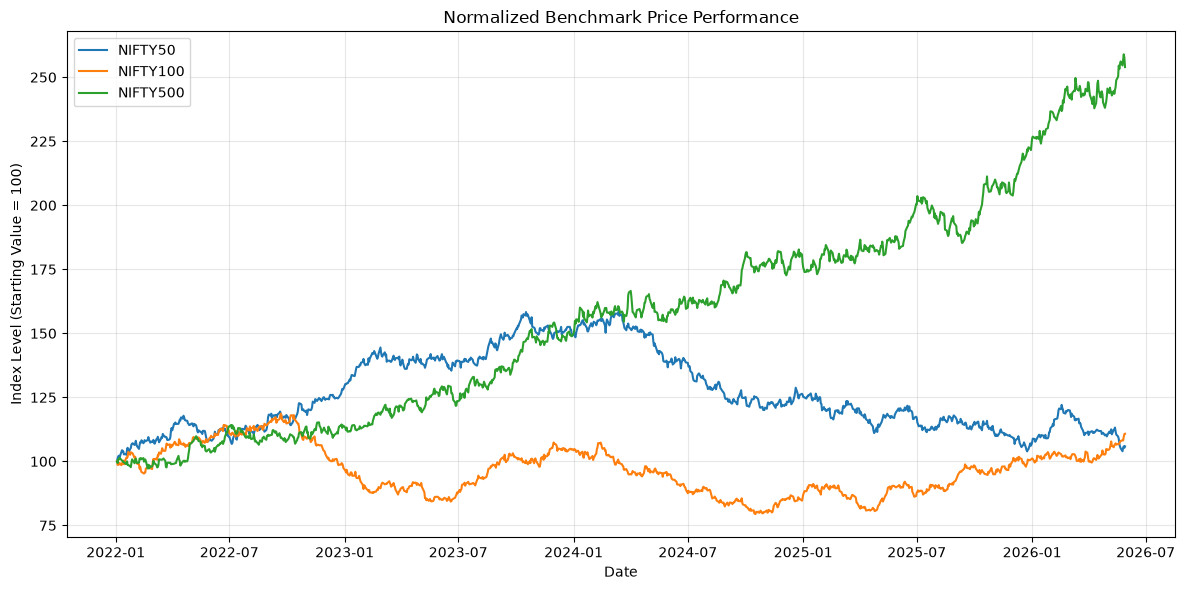

In [162]:
comparison_indices = ["NIFTY50", "NIFTY100", "NIFTY500"]

comparison_df = benchmark_indices_df[
    benchmark_indices_df["index_name"].isin(comparison_indices)
].copy()

comparison_df = comparison_df.sort_values(["index_name", "date"])

comparison_df["normalized_value"] = (
    comparison_df["close_value"]
    / comparison_df.groupby("index_name")["close_value"].transform("first")
) * 100

plt.figure(figsize=(12, 6))

for index in comparison_indices:
    index_data = comparison_df[
        comparison_df["index_name"] == index
    ]

    plt.plot(
        index_data["date"],
        index_data["normalized_value"],
        label=index
    )

plt.title("Normalized Benchmark Price Performance")
plt.xlabel("Date")
plt.ylabel("Index Level (Starting Value = 100)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [163]:
# Inspect the 10 largest absolute daily returns for each index

largest_moves = (
    benchmark_indices_df
    .dropna(subset=["daily_return_pct"])
    .assign(
        abs_return=lambda df: df["daily_return_pct"].abs()
    )
    .sort_values(
        ["index_name", "abs_return"],
        ascending=[True, False]
    )
    .groupby("index_name")
    .head(10)
    [["date", "index_name", "close_value", "daily_return_pct"]]
    .sort_values(["index_name", "date"])
)

display(largest_moves.round(3))

C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\3298466980.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(largest_moves.round(3))


,date,index_name,close_value,daily_return_pct
3454,2022-01-07,BSE_SMALLCAP,26316.86,-3.873
3587,2022-07-13,BSE_SMALLCAP,26937.51,3.854
3638,2022-09-22,BSE_SMALLCAP,25841.96,-3.803
3668,2022-11-03,BSE_SMALLCAP,27752.52,4.185
3672,2022-11-09,BSE_SMALLCAP,27622.31,-3.724
...,...,...,...,...
2900,2024-04-22,NIFTY_MIDCAP150,26795.23,2.972
3013,2024-09-26,NIFTY_MIDCAP150,27109.45,-3.511
3220,2025-07-14,NIFTY_MIDCAP150,28508.94,3.241
3223,2025-07-17,NIFTY_MIDCAP150,29147.84,3.523


In [164]:
return_extremes = (
    benchmark_indices_df
    .dropna(subset=["daily_return_pct"])
    .groupby("index_name")
    .agg(
        min_daily_return_pct=("daily_return_pct", "min"),
        max_daily_return_pct=("daily_return_pct", "max")
    )
)

min_dates = (
    benchmark_indices_df.loc[
        benchmark_indices_df.groupby("index_name")["daily_return_pct"].idxmin(),
        ["index_name", "date"]
    ]
    .set_index("index_name")
    .rename(columns={"date": "min_return_date"})
)

max_dates = (
    benchmark_indices_df.loc[
        benchmark_indices_df.groupby("index_name")["daily_return_pct"].idxmax(),
        ["index_name", "date"]
    ]
    .set_index("index_name")
    .rename(columns={"date": "max_return_date"})
)

return_extremes = (
    return_extremes
    .join(min_dates)
    .join(max_dates)
    .reset_index()
)

display(return_extremes.round(3))

C:\Users\ASUS\AppData\Local\Temp\ipykernel_40608\2792295134.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(return_extremes.round(3))


,index_name,min_daily_return_pct,max_daily_return_pct,min_return_date,max_return_date
0,BSE_SMALLCAP,-3.972,4.185,2025-10-03,2022-11-03
1,CRISIL_GILT,-0.744,0.821,2023-06-08,2023-07-27
2,CRISIL_LIQUID,-0.078,0.126,2023-09-26,2023-12-08
3,NIFTY100,-2.687,2.679,2023-05-09,2022-03-01
4,NIFTY50,-2.377,2.307,2023-10-27,2025-04-30
5,NIFTY500,-2.862,3.102,2022-02-21,2024-03-28
6,NIFTY_MIDCAP150,-3.575,3.523,2026-01-26,2025-07-17


In [165]:
benchmark_volatility = (
    benchmark_indices_df
    .groupby("index_name")["daily_return_pct"]
    .agg(
        daily_mean_pct="mean",
        daily_volatility_pct="std"
    )
    .sort_values("daily_volatility_pct", ascending=False)
    .reset_index()
)

display(benchmark_volatility.round(3))

,index_name,daily_mean_pct,daily_volatility_pct
0,BSE_SMALLCAP,0.104,1.395
1,NIFTY_MIDCAP150,0.112,1.123
2,NIFTY500,0.085,0.873
3,NIFTY100,0.012,0.812
4,NIFTY50,0.008,0.811
5,CRISIL_GILT,0.041,0.260
6,CRISIL_LIQUID,0.025,0.033


### Benchmark Daily Return Volatility

Daily return volatility was compared across the seven supplied benchmark indices using the standard deviation of daily percentage returns.

- BSE_SMALLCAP had the highest daily volatility at 1.395%, followed by NIFTY_MIDCAP150 at 1.123%.
- CRISIL_GILT had a daily volatility of 0.260%, while CRISIL_LIQUID had the lowest value at 0.033%.
- NIFTY100 and NIFTY50 showed similar daily volatility at 0.812% and 0.811%, respectively.

The results show substantial differences in observed daily return variability across the supplied series. These are descriptive findings for the dataset's observation period and should not be interpreted as predictions of future risk or return.

In [166]:
benchmark_drawdown = (
    benchmark_indices_df
    .sort_values(["index_name", "date"])
    .copy()
)

benchmark_drawdown["running_peak"] = (
    benchmark_drawdown
    .groupby("index_name")["close_value"]
    .cummax()
)

benchmark_drawdown["drawdown_pct"] = (
    benchmark_drawdown["close_value"]
    / benchmark_drawdown["running_peak"] - 1
) * 100

max_drawdown = (
    benchmark_drawdown
    .groupby("index_name")["drawdown_pct"]
    .min()
    .sort_values()
    .rename("max_drawdown_pct")
    .reset_index()
)

display(max_drawdown.round(2))

,index_name,max_drawdown_pct
0,NIFTY50,-34.61
1,NIFTY100,-33.00
2,BSE_SMALLCAP,-20.26
3,NIFTY_MIDCAP150,-16.85
4,NIFTY500,-8.96
5,CRISIL_GILT,-3.02
6,CRISIL_LIQUID,-0.11


### Benchmark Maximum Drawdown

Maximum drawdown was calculated for each benchmark using its running peak closing value. The metric measures the largest percentage decline from a previous peak to a subsequent trough within the observation period.

- NIFTY50 recorded the largest observed drawdown at −34.61%, followed by NIFTY100 at −33.00%.
- BSE_SMALLCAP recorded −20.26%, while NIFTY_MIDCAP150 recorded −16.85%.
- CRISIL_GILT and CRISIL_LIQUID showed smaller observed drawdowns of −3.02% and −0.11%, respectively.

These calculations describe the supplied closing-price series. Because unusual benchmark patterns remain unresolved, the results should be treated as provisional rather than verified real-world risk estimates.

### Benchmark Analysis — Conclusion

The benchmark dataset was analysed for daily returns, volatility, return extremes, normalized price performance and maximum drawdown across seven index series covering January 2022 to May 2026.

The supplied data shows higher daily volatility and larger observed daily movements in the equity indices than in the CRISIL gilt and liquid indices. Maximum drawdown also varies considerably across the series.

The analysis is descriptive and uses only the provided dataset. Unusual patterns in the NIFTY50 and NIFTY100 series remain unresolved; therefore, cumulative performance and risk comparisons should be interpreted cautiously. The original data has been preserved without modification.

## 9. Investor Transaction Analysis

In [169]:
transactions_df = pd.read_csv(
    RAW_DATA_DIR / "08_investor_transactions.csv"
)

print("Dataset shape:", transactions_df.shape)

print("\nColumn names:")
print(transactions_df.columns.tolist())

print("\nData types:")
display(transactions_df.dtypes.to_frame("data_type"))

print("\nFirst 5 rows:")
display(transactions_df.head())

Dataset shape: (32778, 13)

Column names:
['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status']

Data types:


,data_type
investor_id,str
transaction_date,str
amfi_code,int64
transaction_type,str
amount_inr,int64
state,str
city,str
city_tier,str
age_group,str
gender,str



First 5 rows:


,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status
0,INV003054,2024-01-01,119092,SIP,1834,Telangana,Hyderabad,T30,56+,Female,77.1,UPI,Verified
1,INV002952,2024-01-01,148567,Redemption,392882,Punjab,Amritsar,B30,18-25,Male,7.1,Cheque,Verified
2,INV003420,2024-01-01,118636,SIP,912,Haryana,Faridabad,B30,36-45,Male,47.2,Mandate,Verified
3,INV003436,2024-01-01,118634,SIP,1102,Maharashtra,Mumbai,T30,36-45,Female,54.4,Cheque,Pending
4,INV004691,2024-01-01,119094,Lumpsum,8682,Delhi,Noida,T30,26-35,Male,14.5,Net Banking,Pending


In [170]:
print("Missing values per column:")
display(
    transactions_df.isna()
    .sum()
    .to_frame("missing_values")
    .sort_values("missing_values", ascending=False)
)

print("\nExact duplicate rows:", transactions_df.duplicated().sum())

print("\nUnique investors:", transactions_df["investor_id"].nunique())
print("Unique AMFI codes:", transactions_df["amfi_code"].nunique())

print("\nTransaction types:")
display(transactions_df["transaction_type"].value_counts(dropna=False))

print("\nKYC status:")
display(transactions_df["kyc_status"].value_counts(dropna=False))

Missing values per column:


,missing_values
investor_id,0
transaction_date,0
amfi_code,0
transaction_type,0
amount_inr,0
state,0
city,0
city_tier,0
age_group,0
gender,0



Exact duplicate rows: 0

Unique investors: 5000
Unique AMFI codes: 40

Transaction types:


transaction_type
SIP           19716
Lumpsum        8095
Redemption     4967
Name: count, dtype: int64


KYC status:


kyc_status
Verified    30146
Pending      2632
Name: count, dtype: int64

In [171]:
# Validate transaction dates
parsed_dates = pd.to_datetime(
    transactions_df["transaction_date"],
    errors="coerce"
)

print("Invalid dates:", parsed_dates.isna().sum())
print("First transaction date:", parsed_dates.min())
print("Last transaction date:", parsed_dates.max())

# Validate transaction amounts
print("\nAmount summary (INR):")
display(transactions_df["amount_inr"].describe().to_frame())

print("Zero or negative amounts:",
      (transactions_df["amount_inr"] <= 0).sum())

print("Distinct transaction dates:",
      parsed_dates.nunique())

Invalid dates: 0
First transaction date: 2024-01-01 00:00:00
Last transaction date: 2025-05-30 00:00:00

Amount summary (INR):


,amount_inr
count,32778.000000
mean,107437.318628
std,150415.905084
min,400.000000
25%,3153.000000
50%,17782.500000
75%,189324.250000
max,597498.000000


Zero or negative amounts: 0
Distinct transaction dates: 516


In [172]:
transaction_type_summary = (
    transactions_df
    .groupby("transaction_type")
    .agg(
        transaction_count=("amount_inr", "size"),
        total_amount_inr=("amount_inr", "sum"),
        average_amount_inr=("amount_inr", "mean"),
        median_amount_inr=("amount_inr", "median"),
        minimum_amount_inr=("amount_inr", "min"),
        maximum_amount_inr=("amount_inr", "max")
    )
    .sort_values("total_amount_inr", ascending=False)
    .reset_index()
)

display(transaction_type_summary.round(2))

,transaction_type,transaction_count,total_amount_inr,average_amount_inr,median_amount_inr,minimum_amount_inr,maximum_amount_inr
0,Lumpsum,8095,2059821448,254456.02,251770.0,4541,594649
1,Redemption,4967,1244525491,250558.79,247511.0,4550,597498
2,SIP,19716,217233491,11018.13,5139.0,400,59998


In [173]:
amount_distribution = (
    transactions_df
    .groupby("transaction_type")["amount_inr"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90])
    .round(2)
)

display(amount_distribution)

,count,mean,std,min,10%,25%,50%,75%,90%,max
transaction_type,,,,,,,,,,
Lumpsum,8095.0,254456.02,145976.82,4541.0,56552.6,129928.50,251770.0,373162.50,451195.0,594649.0
Redemption,4967.0,250558.79,145485.32,4550.0,54188.6,126553.50,247511.0,365979.00,447683.0,597498.0
SIP,19716.0,11018.13,14218.20,400.0,848.0,2116.75,5139.0,13554.25,28817.5,59998.0


In [174]:
transactions_df["transaction_date"] = pd.to_datetime(
    transactions_df["transaction_date"]
)

transactions_df["transaction_month"] = (
    transactions_df["transaction_date"].dt.to_period("M").astype(str)
)

monthly_transactions = (
    transactions_df
    .groupby(["transaction_month", "transaction_type"])
    .agg(
        transaction_count=("amount_inr", "size"),
        total_amount_inr=("amount_inr", "sum")
    )
    .reset_index()
)

display(monthly_transactions.head(15))

,transaction_month,transaction_type,transaction_count,total_amount_inr
0,2024-01,Lumpsum,492,125509831
1,2024-01,Redemption,311,79503125
2,2024-01,SIP,1146,12635349
3,2024-02,Lumpsum,439,111404051
4,2024-02,Redemption,268,69871989
5,2024-02,SIP,1154,12613376
6,2024-03,Lumpsum,498,124810113
7,2024-03,Redemption,299,76554972
8,2024-03,SIP,1177,12088413
9,2024-04,Lumpsum,484,127545599


In [175]:
monthly_extremes = (
    monthly_transactions
    .groupby("transaction_type")
    .agg(
        highest_count=("transaction_count", "max"),
        lowest_count=("transaction_count", "min"),
        highest_amount_inr=("total_amount_inr", "max"),
        lowest_amount_inr=("total_amount_inr", "min")
    )
)

display(monthly_extremes)

,highest_count,lowest_count,highest_amount_inr,lowest_amount_inr
transaction_type,,,,
Lumpsum,521,438,134046496,106737536
Redemption,340,244,84148612,62497934
SIP,1235,1041,13973011,11363922


In [176]:
for transaction_type in monthly_transactions["transaction_type"].unique():
    subset = monthly_transactions[
        monthly_transactions["transaction_type"] == transaction_type
    ]

    print(f"\n{transaction_type}")

    print("Highest transaction count:")
    display(
        subset.loc[
            subset["transaction_count"].idxmax()
        ]
    )

    print("Lowest transaction count:")
    display(
        subset.loc[
            subset["transaction_count"].idxmin()
        ]
    )

    print("Highest transaction amount:")
    display(
        subset.loc[
            subset["total_amount_inr"].idxmax()
        ]
    )

    print("Lowest transaction amount:")
    display(
        subset.loc[
            subset["total_amount_inr"].idxmin()
        ]
    )


Lumpsum
Highest transaction count:


transaction_month      2024-12
transaction_type       Lumpsum
transaction_count          521
total_amount_inr     131320892
Name: 33, dtype: object

Lowest transaction count:


transaction_month      2024-05
transaction_type       Lumpsum
transaction_count          438
total_amount_inr     114669898
Name: 12, dtype: object

Highest transaction amount:


...

transaction_month     2025-02
transaction_type          SIP
transaction_count        1041
total_amount_inr     11363922
Name: 41, dtype: object

Highest transaction amount:


transaction_month     2025-05
transaction_type          SIP
transaction_count        1201
total_amount_inr     13973011
Name: 50, dtype: object

Lowest transaction amount:


transaction_month     2025-02
transaction_type          SIP
transaction_count        1041
total_amount_inr     11363922
Name: 41, dtype: object

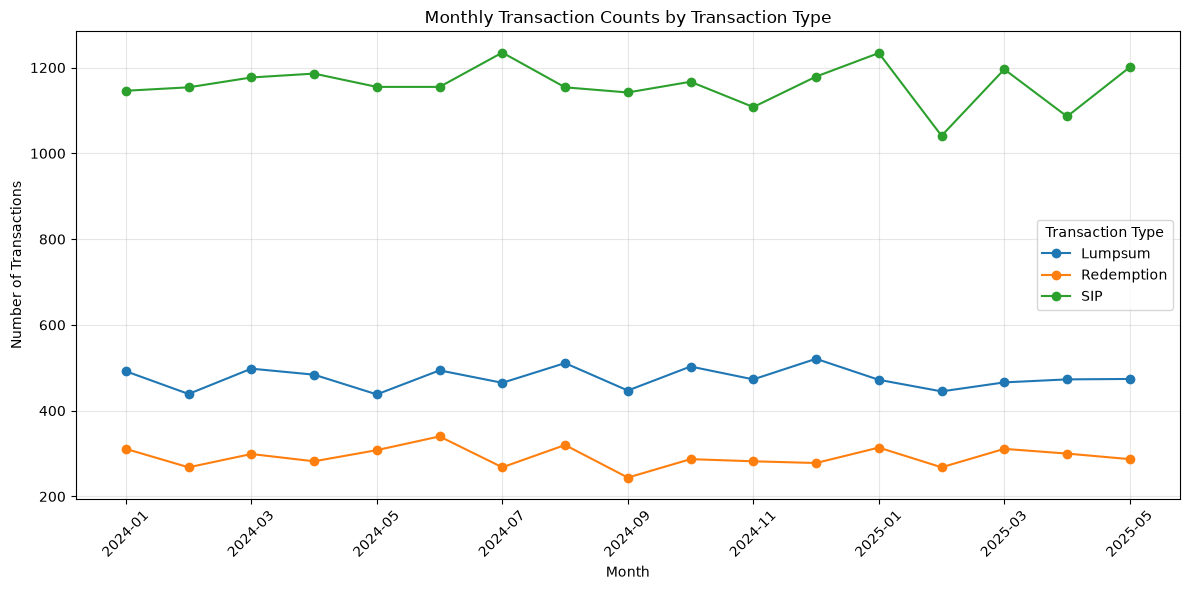

In [177]:
monthly_count_pivot = monthly_transactions.pivot(
    index="transaction_month",
    columns="transaction_type",
    values="transaction_count"
)

monthly_count_pivot.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title("Monthly Transaction Counts by Transaction Type")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.legend(title="Transaction Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Monthly Transaction Count Trends

Monthly transaction counts were analysed from January 2024 to May 2025 across SIP, Lumpsum and Redemption categories.

- SIP transactions were the most frequent, ranging from 1,041 to 1,235 records per month.
- Lumpsum transaction counts ranged from 438 to 521.
- Redemption counts ranged from 244 to 340.

The monthly series shows fluctuations without a clear sustained upward or downward trend across the observation period. These findings describe the supplied synthetic transaction dataset and should not be interpreted as actual market-wide investor activity.

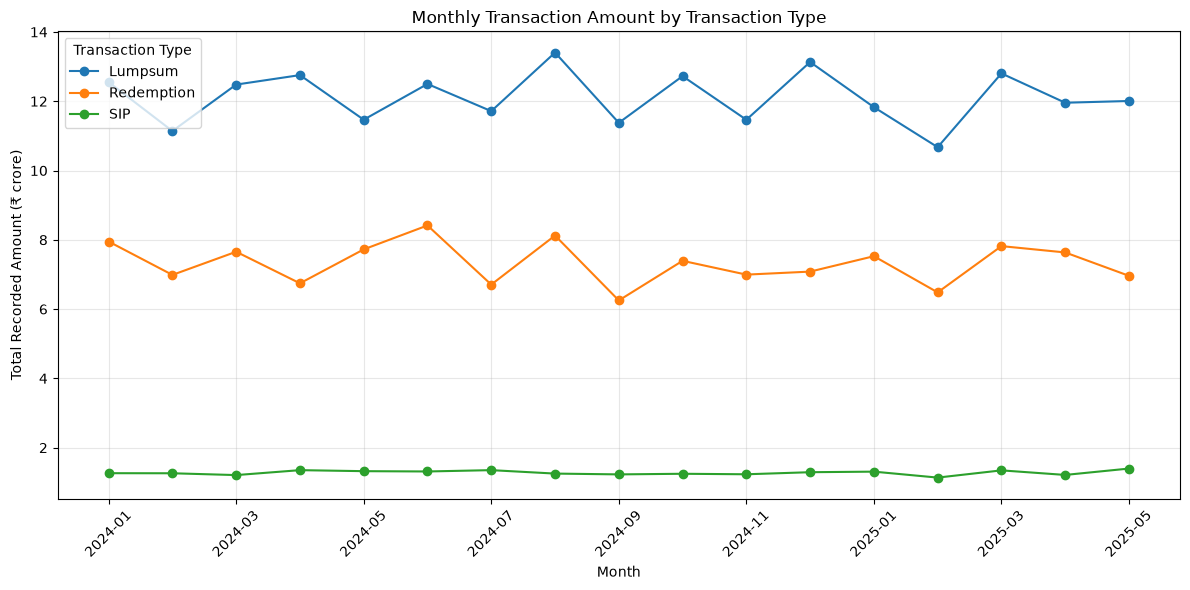

In [178]:
monthly_amount_pivot = monthly_transactions.pivot(
    index="transaction_month",
    columns="transaction_type",
    values="total_amount_inr"
)

monthly_amount_pivot = monthly_amount_pivot / 1e7  # Convert INR to crore

monthly_amount_pivot.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title("Monthly Transaction Amount by Transaction Type")
plt.xlabel("Month")
plt.ylabel("Total Recorded Amount (₹ crore)")
plt.xticks(rotation=45)
plt.legend(title="Transaction Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Monthly Transaction Amount Trends

Monthly recorded transaction amounts were compared across SIP, Lumpsum and Redemption categories from January 2024 to May 2025.

- Lumpsum recorded the highest monthly total, ranging from approximately ₹10.67 crore to ₹13.40 crore.
- Redemption totals ranged from approximately ₹6.25 crore to ₹8.41 crore, with the highest value in June 2024 and the lowest in September 2024.
- SIP recorded totals of approximately ₹1.14 crore to ₹1.40 crore, despite having the highest monthly transaction counts.

The count and amount charts together show that transaction frequency and recorded monetary value are different measures. The SIP amount scale is substantially lower than the other categories in the supplied data; this discrepancy is retained as a data-quality observation rather than corrected without evidence.

These are descriptive findings from synthetic transaction records, not estimates of actual mutual fund industry flows.

In [179]:
investor_summary = (
    transactions_df
    .groupby("investor_id")
    .agg(
        transaction_count=("amount_inr", "size"),
        total_recorded_amount_inr=("amount_inr", "sum"),
        average_transaction_amount_inr=("amount_inr", "mean")
    )
    .reset_index()
)

print("Unique investors:", investor_summary.shape[0])

print("\nTransactions per investor:")
display(investor_summary["transaction_count"].describe().to_frame())

print("\nTotal recorded amount per investor (INR):")
display(investor_summary["total_recorded_amount_inr"].describe().to_frame())

Unique investors: 5000

Transactions per investor:


,transaction_count
count,5000.000000
mean,6.555600
std,3.451506
min,1.000000
25%,4.000000
50%,7.000000
75%,10.000000
max,12.000000



Total recorded amount per investor (INR):


,total_recorded_amount_inr
count,5.000000e+03
mean,7.043161e+05
std,5.364292e+05
min,4.040000e+02
25%,2.881332e+05
50%,6.065640e+05
75%,1.051246e+06
max,3.480685e+06


### Investor-Level Transaction Activity

Investor-level summaries were calculated for 5,000 distinct investors in the supplied synthetic transaction dataset.

- Investors recorded between 1 and 12 transactions, with a mean of 6.56 and a median of 7 transactions per investor.
- The median total recorded transaction amount per investor was ₹6,06,564, compared with a mean of approximately ₹7,04,316.
- The maximum total recorded transaction amount for one investor was ₹34,80,685.

The difference between the mean and median suggests that recorded transaction activity is unevenly distributed across investors. Total recorded amounts combine SIP, Lumpsum and Redemption transactions and should not be interpreted as net investment, holdings or wealth.

In [180]:
top_active_investors = (
    investor_summary
    .sort_values(
        ["transaction_count", "total_recorded_amount_inr"],
        ascending=[False, False]
    )
    .head(10)
    .copy()
)

display(top_active_investors)

,investor_id,transaction_count,total_recorded_amount_inr,average_transaction_amount_inr
3287,INV003288,12,3480685,290057.083333
1998,INV001999,12,3179916,264993.000000
2552,INV002553,12,2668557,222379.750000
2244,INV002245,12,2623784,218648.666667
3731,INV003732,12,2556852,213071.000000
2249,INV002250,12,2556238,213019.833333
605,INV000606,12,2504294,208691.166667
4063,INV004064,12,2485177,207098.083333
2995,INV002996,12,2445043,203753.583333
670,INV000671,12,2333315,194442.916667


### Most Active Investors by Transaction Count

The top 10 investors were ranked by transaction count, using total recorded transaction amount as a secondary sorting criterion.

All 10 investors recorded 12 transactions, the maximum observed in the dataset. Their total recorded amounts ranged from approximately ₹23.33 lakh to ₹34.81 lakh. Investor `INV003288` had the highest recorded amount among these investors at ₹34,80,685.

This ranking describes transaction activity within the supplied synthetic dataset. It does not measure investor wealth, current holdings or investment performance.

In [181]:
print("Transactions by age group:")
display(
    transactions_df["age_group"]
    .value_counts(dropna=False)
    .rename_axis("age_group")
    .reset_index(name="transaction_count")
)

print("\nTransactions by gender:")
display(
    transactions_df["gender"]
    .value_counts(dropna=False)
    .rename_axis("gender")
    .reset_index(name="transaction_count")
)

print("\nTransactions by city tier:")
display(
    transactions_df["city_tier"]
    .value_counts(dropna=False)
    .rename_axis("city_tier")
    .reset_index(name="transaction_count")
)

Transactions by age group:


,age_group,transaction_count
0,26-35,13463
1,36-45,8146
2,18-25,4916
3,46-55,3779
4,56+,2474



Transactions by gender:


,gender,transaction_count
0,Male,21809
1,Female,10969



Transactions by city tier:


,city_tier,transaction_count
0,T30,21719
1,B30,11059


In [182]:
investor_demographics = (
    transactions_df[
        ["investor_id", "age_group", "gender", "city_tier"]
    ]
    .drop_duplicates(subset="investor_id")
)

print("Unique investors:", len(investor_demographics))

print("\nUnique investors by age group:")
display(
    investor_demographics["age_group"]
    .value_counts()
    .rename_axis("age_group")
    .reset_index(name="investor_count")
)

print("\nUnique investors by gender:")
display(
    investor_demographics["gender"]
    .value_counts()
    .rename_axis("gender")
    .reset_index(name="investor_count")
)

print("\nUnique investors by city tier:")
display(
    investor_demographics["city_tier"]
    .value_counts()
    .rename_axis("city_tier")
    .reset_index(name="investor_count")
)

Unique investors: 5000

Unique investors by age group:


,age_group,investor_count
0,26-35,2033
1,36-45,1237
2,18-25,753
3,46-55,589
4,56+,388



Unique investors by gender:


,gender,investor_count
0,Male,3337
1,Female,1663



Unique investors by city tier:


,city_tier,investor_count
0,T30,3335
1,B30,1665


### Unique-Investor Demographic Distribution

Demographic counts were recalculated using one record per investor across the 5,000 distinct investor IDs.

- The 26–35 age group contained 2,033 investors (40.66%), the largest age group.
- Male investors accounted for 3,337 records (66.74%), compared with 1,663 female investors (33.26%).
- T30 accounted for 3,335 investors (66.70%), while B30 accounted for 1,665 (33.30%).

The demographic distributions were similar to those observed at the transaction-record level. This suggests that the overall patterns are not explained solely by transaction frequency differences across demographic groups. These results describe the supplied synthetic dataset and should not be generalized to actual investors.

In [183]:
demographic_consistency = (
    transactions_df
    .groupby("investor_id")
    .agg(
        age_group_count=("age_group", "nunique"),
        gender_count=("gender", "nunique"),
        city_tier_count=("city_tier", "nunique")
    )
)

print("Investors with multiple age groups:",
      (demographic_consistency["age_group_count"] > 1).sum())

print("Investors with multiple gender values:",
      (demographic_consistency["gender_count"] > 1).sum())

print("Investors with multiple city tiers:",
      (demographic_consistency["city_tier_count"] > 1).sum())

Investors with multiple age groups: 0
Investors with multiple gender values: 0
Investors with multiple city tiers: 0


### Demographic Consistency Validation

Demographic consistency was checked across all transactions for each investor ID.

- No investor had multiple age-group values.
- No investor had multiple gender values.
- No investor had multiple city-tier values.

All 5,000 investors therefore had consistent values for these three demographic attributes across their transaction records. This supports the use of one record per investor for the corresponding demographic summaries.

In [184]:
investor_activity_by_age = (
    transactions_df
    .groupby(["investor_id", "age_group"])
    .size()
    .reset_index(name="transaction_count")
    .groupby("age_group")
    .agg(
        investor_count=("investor_id", "nunique"),
        avg_transactions=("transaction_count", "mean"),
        median_transactions=("transaction_count", "median"),
        max_transactions=("transaction_count", "max")
    )
    .sort_values("avg_transactions", ascending=False)
    .reset_index()
)

display(investor_activity_by_age.round(2))

,age_group,investor_count,avg_transactions,median_transactions,max_transactions
0,26-35,2033,6.62,7.0,12
1,36-45,1237,6.59,7.0,12
2,18-25,753,6.53,6.0,12
3,46-55,589,6.42,6.0,12
4,56+,388,6.38,7.0,12


### Transaction Frequency by Age Group

Transaction frequency was calculated per investor and summarised across age groups.

- The 26–35 age group had the highest average frequency at 6.62 transactions per investor.
- The 56+ age group had the lowest average at 6.38 transactions per investor.
- The difference between the highest and lowest group averages was only 0.24 transactions.
- Median transaction frequency ranged from 6 to 7 transactions across age groups.

Average transaction frequency was broadly similar across all five age groups. These descriptive findings relate only to the supplied synthetic dataset and do not establish meaningful differences in real-world investor behaviour.

In [185]:
investor_activity = (
    transactions_df
    .groupby("investor_id")
    .agg(
        gender=("gender", "first"),
        city_tier=("city_tier", "first"),
        transaction_count=("transaction_type", "size")
    )
    .reset_index()
)

print("Transaction frequency by gender:")
display(
    investor_activity
    .groupby("gender")["transaction_count"]
    .agg(["count", "mean", "median", "max"])
    .round(2)
)

print("\nTransaction frequency by city tier:")
display(
    investor_activity
    .groupby("city_tier")["transaction_count"]
    .agg(["count", "mean", "median", "max"])
    .round(2)
)

Transaction frequency by gender:


,count,mean,median,max
gender,,,,
Female,1663,6.60,7.0,12
Male,3337,6.54,7.0,12



Transaction frequency by city tier:


,count,mean,median,max
city_tier,,,,
B30,1665,6.64,7.0,12
T30,3335,6.51,7.0,12


### Transaction Frequency by Gender and City Tier

**Gender comparison**
- Female investors averaged 6.60 transactions, compared with 6.54 for male investors.
- Both groups had a median of 7 transactions.
- The difference in average frequency was only 0.06 transactions per investor.

**City-tier comparison**
- B30 investors averaged 6.64 transactions, compared with 6.51 for T30 investors.
- Both groups had a median of 7 transactions.
- The difference in average frequency was 0.13 transactions per investor.

Transaction frequency was broadly similar across both gender and city-tier groups. These are descriptive findings from the supplied synthetic dataset and should not be interpreted as evidence of causal relationships or real-world investor behaviour.

In [186]:
amount_by_age = (
    transactions_df
    .groupby("age_group")
    .agg(
        transaction_count=("amount_inr", "size"),
        total_amount_inr=("amount_inr", "sum"),
        average_amount_inr=("amount_inr", "mean"),
        median_amount_inr=("amount_inr", "median")
    )
    .reset_index()
    .sort_values("total_amount_inr", ascending=False)
)

display(amount_by_age.round(2))

,age_group,transaction_count,total_amount_inr,average_amount_inr,median_amount_inr
1,26-35,13463,1451600218,107821.45,18523.0
2,36-45,8146,871647528,107003.13,17457.0
0,18-25,4916,531639392,108144.71,17553.0
3,46-55,3779,405406469,107278.77,17425.0
4,56+,2474,261286823,105613.11,20396.5


### Transaction Amount Analysis by Age Group

- The 26–35 age group recorded the highest aggregate transaction amount at approximately ₹145.16 crore, across 13,463 transactions.
- The 36–45 age group followed with approximately ₹87.16 crore, while the 56+ group recorded the lowest total at approximately ₹26.13 crore.
- The 18–25 group had the highest average transaction amount at approximately ₹1,08,145.
- The 56+ group had the lowest average transaction amount at approximately ₹1,05,613.
- Average transaction amounts were relatively similar across all age groups, despite differences in transaction counts and aggregate amounts.

The larger aggregate amount for ages 26–35 coincided with a higher number of transactions. These figures represent recorded transaction amounts across SIPs, lumpsum investments and redemptions; they do not represent net investment, portfolio value or investor wealth. The dataset is synthetic, so these findings should not be generalised to real-world investors.

In [187]:
amount_by_demographic = (
    transactions_df
    .groupby(["gender", "city_tier"])
    .agg(
        transaction_count=("amount_inr", "size"),
        total_amount_inr=("amount_inr", "sum"),
        average_amount_inr=("amount_inr", "mean"),
        median_amount_inr=("amount_inr", "median")
    )
    .reset_index()
)

display(amount_by_demographic.round(2))

,gender,city_tier,transaction_count,total_amount_inr,average_amount_inr,median_amount_inr
0,Female,B30,3767,406742038,107975.06,17416.0
1,Female,T30,7202,769604663,106859.85,17543.5
2,Male,B30,7292,795583602,109103.62,20493.0
3,Male,T30,14517,1549650127,106747.27,17671.0


### Transaction Amounts by Gender and City Tier

- The Male–T30 group recorded the highest aggregate transaction amount at approximately ₹154.97 crore across 14,517 transactions.
- The Male–B30 group had the highest average transaction amount at approximately ₹1,09,104.
- The Female–B30 group recorded the lowest aggregate amount at approximately ₹40.67 crore across 3,767 transactions.
- Average transaction amounts were relatively similar across all four groups, ranging from approximately ₹1,06,747 to ₹1,09,104.

Aggregate amounts should be interpreted alongside transaction counts, as groups with more recorded transactions can naturally accumulate higher totals. The figures combine SIPs, lumpsum investments and redemptions and therefore do not represent net investment or investor wealth. These are descriptive findings from the supplied synthetic dataset, not evidence of real-world demographic behaviour.

In [188]:
kyc_summary = (
    transactions_df
    .groupby("kyc_status")
    .agg(
        transaction_count=("investor_id", "size"),
        unique_investors=("investor_id", "nunique"),
        total_amount_inr=("amount_inr", "sum"),
        average_amount_inr=("amount_inr", "mean")
    )
    .reset_index()
)

display(kyc_summary.round(2))

,kyc_status,transaction_count,unique_investors,total_amount_inr,average_amount_inr
0,Pending,2632,2013,287408049,109197.59
1,Verified,30146,4961,3234172381,107283.63


### Transaction Analysis by KYC Status

- Verified KYC records accounted for 30,146 transactions, while Pending KYC records accounted for 2,632.
- The total recorded transaction amount was approximately ₹323.42 crore for Verified records and ₹28.74 crore for Pending records.
- The average transaction amount was approximately ₹1,07,284 for Verified records and ₹1,09,198 for Pending records.
- The dataset contains 4,961 unique investors in the Verified group and 2,013 in the Pending group. These groups overlap, so their investor counts should not be added to estimate unique investors.

The results describe transaction activity by the recorded KYC status. They do not establish whether transactions were permitted, whether KYC status changed over time, or whether KYC status influenced transaction behaviour. The dataset is synthetic, and the findings should not be generalised to real-world investors.

In [189]:
kyc_consistency = (
    transactions_df
    .groupby("investor_id")
    .agg(
        kyc_status_count=("kyc_status", "nunique"),
        recorded_kyc_statuses=(
            "kyc_status",
            lambda x: ", ".join(sorted(x.unique()))
        )
    )
    .reset_index()
)

print("Investors with one KYC status:")
print((kyc_consistency["kyc_status_count"] == 1).sum())

print("\nInvestors with multiple KYC statuses:")
print((kyc_consistency["kyc_status_count"] > 1).sum())

print("\nInvestors with multiple statuses — sample:")
display(
    kyc_consistency[
        kyc_consistency["kyc_status_count"] > 1
    ].head(10)
)

Investors with one KYC status:
3026

Investors with multiple KYC statuses:
1974

Investors with multiple statuses — sample:


,investor_id,kyc_status_count,recorded_kyc_statuses
0,INV000001,2,"Pending, Verified"
4,INV000005,2,"Pending, Verified"
5,INV000006,2,"Pending, Verified"
6,INV000007,2,"Pending, Verified"
8,INV000009,2,"Pending, Verified"
10,INV000011,2,"Pending, Verified"
13,INV000014,2,"Pending, Verified"
16,INV000017,2,"Pending, Verified"
19,INV000020,2,"Pending, Verified"
20,INV000021,2,"Pending, Verified"


### KYC Status Consistency Check

KYC status consistency was checked by counting the distinct recorded statuses for each investor.

- 3,026 investors (60.52%) had one distinct KYC status.
- 1,974 investors (39.48%) had both Pending and Verified statuses recorded across their transactions.
- The results demonstrate that KYC status is not constant across all transaction records for a substantial subset of investors.

The supplied data does not establish whether these multiple statuses reflect legitimate changes over time or inconsistencies. Therefore, the records were retained unchanged, and no assumptions were made about the validity or timing of KYC transitions.

In [190]:
kyc_dates = (
    transactions_df
    .groupby(["investor_id", "kyc_status"])["transaction_date"]
    .min()
    .unstack()
    .reset_index()
)

kyc_dates = kyc_dates.dropna(
    subset=["Pending", "Verified"]
).copy()

kyc_dates["pending_date"] = pd.to_datetime(kyc_dates["Pending"])
kyc_dates["verified_date"] = pd.to_datetime(kyc_dates["Verified"])

kyc_dates["verified_after_pending"] = (
    kyc_dates["verified_date"] > kyc_dates["pending_date"]
)

print("Investors with both statuses:", len(kyc_dates))
print(
    "Verified date later than Pending date:",
    kyc_dates["verified_after_pending"].sum()
)
print(
    "Verified date same as or earlier than Pending date:",
    (~kyc_dates["verified_after_pending"]).sum()
)

display(
    kyc_dates[
        ["investor_id", "pending_date", "verified_date",
         "verified_after_pending"]
    ].head(10)
)

Investors with both statuses: 1974
Verified date later than Pending date: 352
Verified date same as or earlier than Pending date: 1622


kyc_status,investor_id,pending_date,verified_date,verified_after_pending
0,INV000001,2025-01-19,2024-11-04,False
4,INV000005,2024-10-11,2024-04-27,False
5,INV000006,2024-06-06,2024-01-02,False
6,INV000007,2024-11-25,2024-01-03,False
8,INV000009,2024-10-29,2024-01-10,False
10,INV000011,2024-11-28,2024-01-03,False
13,INV000014,2025-05-28,2024-02-12,False
16,INV000017,2025-01-26,2024-02-23,False
19,INV000020,2024-06-28,2024-07-10,True
20,INV000021,2024-06-06,2024-03-09,False


### KYC Status and Transaction-Date Comparison

Among the 1,974 investors with both Pending and Verified KYC statuses:

- 352 investors (17.83%) had their earliest Verified transaction after their earliest Pending transaction.
- 1,622 investors (82.17%) had their earliest Verified transaction on or before their earliest Pending transaction.

The transaction-date ordering does not establish when an investor's KYC status actually changed. Since the dataset does not provide KYC status-change timestamps or transition histories, these results are treated as a descriptive diagnostic rather than evidence of incorrect records or compliance issues. The supplied data was retained unchanged.

In [191]:
kyc_transaction_mix = pd.crosstab(
    transactions_df["kyc_status"],
    transactions_df["transaction_type"],
    normalize="index"
).mul(100).round(2)

print("Transaction-type distribution within each KYC status (%):")
display(kyc_transaction_mix)

Transaction-type distribution within each KYC status (%):


transaction_type,Lumpsum,Redemption,SIP
kyc_status,,,
Pending,25.42,14.36,60.22
Verified,24.63,15.22,60.14


In [192]:
amount_by_age_and_type = (
    transactions_df
    .groupby(["age_group", "transaction_type"])
    .agg(
        transaction_count=("amount_inr", "size"),
        average_amount_inr=("amount_inr", "mean"),
        median_amount_inr=("amount_inr", "median")
    )
    .reset_index()
    .sort_values(["transaction_type", "age_group"])
)

display(amount_by_age_and_type.round(2))

,age_group,transaction_type,transaction_count,average_amount_inr,median_amount_inr
0,18-25,Lumpsum,1205,255328.41,257512.0
3,26-35,Lumpsum,3372,255718.70,251950.5
6,36-45,Lumpsum,1976,252478.93,250679.0
9,46-55,Lumpsum,924,258080.54,264050.0
12,56+,Lumpsum,618,246767.73,233170.0
1,18-25,Redemption,762,251532.87,250002.5
4,26-35,Redemption,2028,246907.99,242469.0
7,36-45,Redemption,1244,256532.08,254454.0
10,46-55,Redemption,555,254640.54,260185.0
13,56+,Redemption,378,242530.76,233130.5


### Transaction Amounts by Age Group and Transaction Type

**Lumpsum**
- The 46–55 group recorded the highest average amount at approximately ₹2,58,081.
- The 56+ group had the lowest average at approximately ₹2,46,768.

**Redemption**
- The 36–45 group had the highest average redemption amount at approximately ₹2,56,532.
- The 56+ group had the lowest average at approximately ₹2,42,531.

**SIP**
- The 56+ group had the highest average SIP amount at approximately ₹11,575 and the highest median at ₹5,420.
- The 18–25 group had the lowest median SIP amount at ₹5,020.

Transaction amounts varied by age group, but the patterns differed across transaction types. Mean amounts generally exceeded median amounts, indicating that higher-value transactions may influence the averages. These findings describe the supplied synthetic dataset and do not establish causal relationships or real-world investor behaviour.

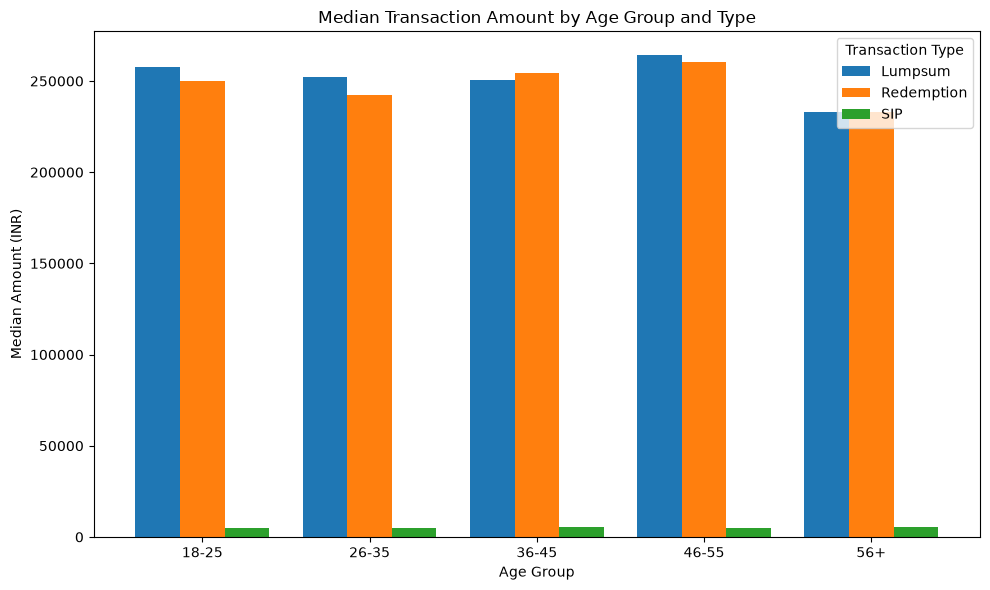

In [193]:
import matplotlib.pyplot as plt
import seaborn as sns

median_amounts = amount_by_age_and_type.pivot(
    index="age_group",
    columns="transaction_type",
    values="median_amount_inr"
)

median_amounts = median_amounts.reindex(
    ["18-25", "26-35", "36-45", "46-55", "56+"]
)

median_amounts.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Median Transaction Amount by Age Group and Type")
plt.xlabel("Age Group")
plt.ylabel("Median Amount (INR)")
plt.xticks(rotation=0)
plt.legend(title="Transaction Type")
plt.tight_layout()
plt.show()

### Median Transaction Amount Visualisation

The grouped bar chart compares median transaction amounts across five age groups and three transaction types.

- Median lumpsum and redemption amounts are substantially higher than median SIP amounts.
- The 46–55 age group has the highest median for both lumpsum (₹2,64,050) and redemption (₹2,60,185).
- The 56+ age group has the lowest median for lumpsum (₹2,33,170) and redemption (₹2,33,130).
- Median SIP amounts vary within a much narrower range, from ₹5,020 to ₹5,420.

Because the transaction types have very different amount scales, the SIP bars are visually compressed. Separate charts could improve readability when presenting these results. All findings relate to the supplied synthetic dataset.

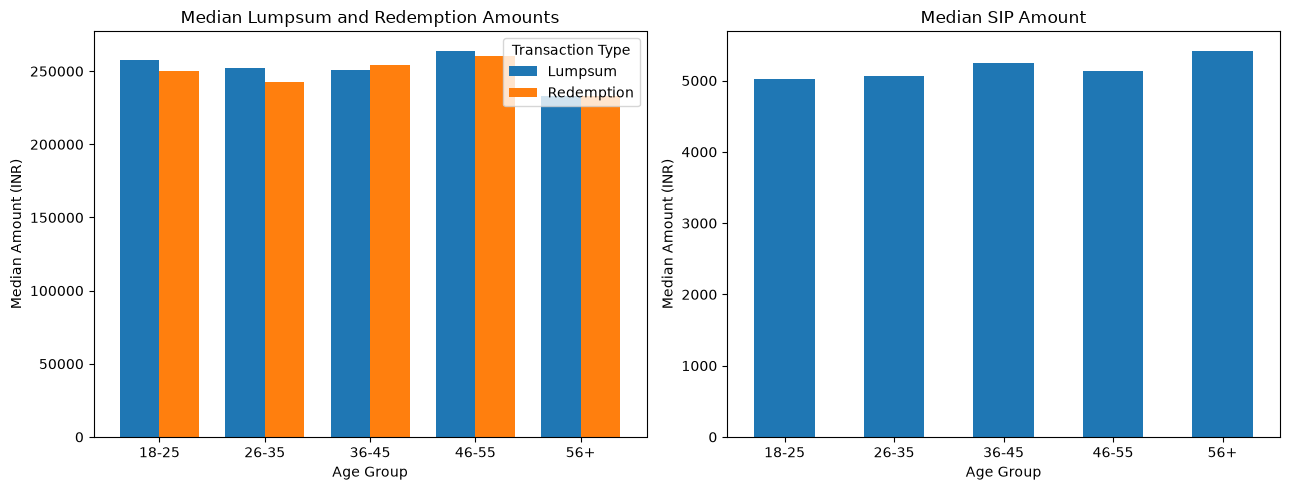

In [194]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: Lumpsum and Redemption
median_amounts[["Lumpsum", "Redemption"]].plot(
    kind="bar",
    ax=axes[0],
    width=0.75
)

axes[0].set_title("Median Lumpsum and Redemption Amounts")
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("Median Amount (INR)")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Transaction Type")

# Chart 2: SIP only
median_amounts[["SIP"]].plot(
    kind="bar",
    ax=axes[1],
    width=0.55,
    legend=False
)

axes[1].set_title("Median SIP Amount")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Median Amount (INR)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [195]:
payment_mode_summary = (
    transactions_df
    .groupby("payment_mode")
    .agg(
        transaction_count=("amount_inr", "size"),
        total_amount_inr=("amount_inr", "sum"),
        average_amount_inr=("amount_inr", "mean"),
        median_amount_inr=("amount_inr", "median")
    )
    .reset_index()
    .sort_values("transaction_count", ascending=False)
)

payment_mode_summary["transaction_share_pct"] = (
    payment_mode_summary["transaction_count"]
    / len(transactions_df) * 100
).round(2)

display(payment_mode_summary.round(2))

,payment_mode,transaction_count,total_amount_inr,average_amount_inr,median_amount_inr,transaction_share_pct
2,Net Banking,8250,893492623,108302.14,17916.5,25.17
0,Cheque,8228,892219218,108436.95,17641.0,25.10
3,UPI,8154,888241021,108933.16,20649.0,24.88
1,Mandate,8146,847627568,104054.45,16855.0,24.85


### Payment-Mode Analysis

- Net Banking recorded the highest transaction count at 8,250 (25.17%).
- Mandate recorded the lowest count at 8,146 (24.85%).
- Transaction shares were closely distributed across all four payment modes, with a maximum difference of 0.32 percentage points.
- UPI had the highest average transaction amount at approximately ₹1,08,933.
- Mandate had the lowest average transaction amount at approximately ₹1,04,054.
- Median transaction amounts ranged from ₹16,855 for Mandate to ₹20,649 for UPI.

Transaction frequency was almost evenly distributed across payment modes, while typical transaction amounts differed somewhat. These observations describe the supplied synthetic dataset and should not be generalised to real-world payment preferences.

In [196]:
payment_type_mix = pd.crosstab(
    transactions_df["transaction_type"],
    transactions_df["payment_mode"],
    normalize="index"
).mul(100).round(2)

print("Payment-mode distribution within each transaction type (%):")
display(payment_type_mix)

Payment-mode distribution within each transaction type (%):


payment_mode,Cheque,Mandate,Net Banking,UPI
transaction_type,,,,
Lumpsum,25.51,24.48,25.02,24.99
Redemption,24.24,24.64,25.69,25.43
SIP,25.15,25.06,25.10,24.69


### Payment-Mode Distribution by Transaction Type

- Lumpsum transactions had the highest Cheque share at 25.51%.
- Redemption transactions had the highest Net Banking share at 25.69%, followed by UPI at 25.43%.
- SIP transactions showed the most balanced distribution, with payment-mode shares ranging from 24.69% to 25.15%.
- Across all transaction types, each payment mode accounted for approximately one-quarter of transactions.

The payment-mode distribution remained broadly balanced when transactions were segmented by type. The largest difference within a transaction type was observed for redemptions, where Net Banking exceeded Cheque by 1.45 percentage points. These findings describe the supplied synthetic dataset and should not be generalised to actual investor payment behaviour.

In [197]:
payment_amount_by_type = (
    transactions_df
    .groupby(["transaction_type", "payment_mode"])
    .agg(
        transaction_count=("amount_inr", "size"),
        average_amount_inr=("amount_inr", "mean"),
        median_amount_inr=("amount_inr", "median")
    )
    .reset_index()
    .sort_values(["transaction_type", "median_amount_inr"],
                 ascending=[True, False])
)

display(payment_amount_by_type.round(2))

,transaction_type,payment_mode,transaction_count,average_amount_inr,median_amount_inr
0,Lumpsum,Cheque,2065,259853.88,262301.0
2,Lumpsum,Net Banking,2025,254833.63,254281.0
3,Lumpsum,UPI,2023,254042.15,249967.0
1,Lumpsum,Mandate,1982,248868.73,242586.5
7,Redemption,UPI,1263,253279.45,253111.0
4,Redemption,Cheque,1204,249901.25,245486.0
6,Redemption,Net Banking,1276,253037.31,244628.5
5,Redemption,Mandate,1224,245814.41,243437.5
10,SIP,Net Banking,4949,11028.27,5320.0
11,SIP,UPI,4868,11179.50,5128.5


### Transaction Amounts by Payment Mode and Transaction Type

**Lumpsum**
- Cheque had the highest median amount at ₹2,62,301.
- Mandate had the lowest median at ₹2,42,586.50.

**Redemption**
- UPI had the highest median amount at ₹2,53,111.
- Mandate had the lowest median at ₹2,43,437.50.

**SIP**
- Net Banking had the highest median amount at ₹5,320.
- Cheque had the lowest median at ₹5,050.
- UPI recorded the highest average SIP amount at approximately ₹11,180.

Median transaction amounts varied by payment mode within each transaction type. The differences were more pronounced for lumpsum transactions than for SIPs. Average SIP amounts exceeded their medians across all payment modes, suggesting that higher-value transactions may influence the averages. These findings describe the supplied synthetic dataset and do not establish causal relationships or actual investor payment preferences.

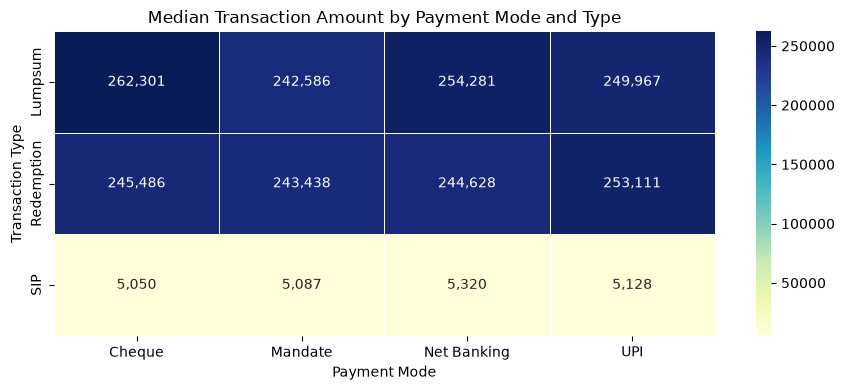

In [198]:
median_payment_heatmap = payment_amount_by_type.pivot(
    index="transaction_type",
    columns="payment_mode",
    values="median_amount_inr"
)

plt.figure(figsize=(9, 4))

sns.heatmap(
    median_payment_heatmap,
    annot=True,
    fmt=",.0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Median Transaction Amount by Payment Mode and Type")
plt.xlabel("Payment Mode")
plt.ylabel("Transaction Type")
plt.tight_layout()
plt.show()

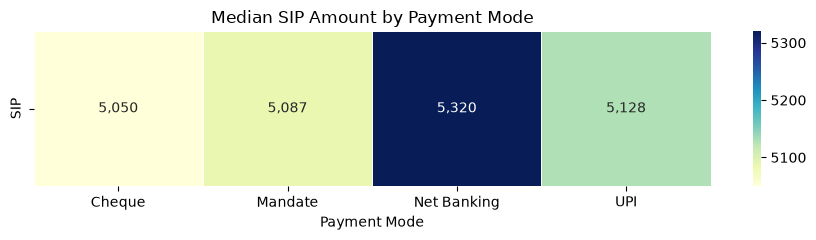

In [199]:
sip_medians = median_payment_heatmap.loc[["SIP"]]

plt.figure(figsize=(9, 2.5))

sns.heatmap(
    sip_medians,
    annot=True,
    fmt=",.0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Median SIP Amount by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Payment-Mode Analysis — Overall Conclusion

The supplied synthetic transaction dataset contains four payment modes: Cheque, Mandate, Net Banking and UPI. Their overall transaction shares were nearly equal, ranging from 24.85% to 25.17%.

When segmented by transaction type, payment-mode shares remained broadly balanced. Median transaction amounts varied more for lumpsum transactions than for SIPs:

- **Lumpsum:** Cheque had the highest median at ₹2,62,301, while Mandate had the lowest at ₹2,42,586.50.
- **Redemption:** UPI had the highest median at ₹2,53,111, while Mandate had the lowest at ₹2,43,437.50.
- **SIP:** Net Banking had the highest median at ₹5,320, while Cheque had the lowest at ₹5,050.

The results indicate a nearly uniform payment-mode distribution alongside some differences in typical transaction amounts. These are descriptive patterns in the supplied synthetic data and do not establish that payment mode causes differences in transaction amounts or represent actual investor preferences.

In [200]:
print("Annual income summary (in lakh INR):")

display(
    transactions_df["annual_income_lakh"]
    .describe()
    .round(2)
)

print("\nUnique annual income values:")
print(transactions_df["annual_income_lakh"].nunique())

print("\nMissing annual income values:")
print(transactions_df["annual_income_lakh"].isna().sum())

Annual income summary (in lakh INR):


count    32778.00
mean        26.18
std         20.81
min          3.00
25%         10.60
50%         19.70
75%         37.40
max         99.70
Name: annual_income_lakh, dtype: float64


Unique annual income values:
804

Missing annual income values:
0


In [201]:
income_consistency = (
    transactions_df
    .groupby("investor_id")
    .agg(
        income_value_count=("annual_income_lakh", "nunique"),
        min_income=("annual_income_lakh", "min"),
        max_income=("annual_income_lakh", "max")
    )
    .reset_index()
)

print(
    "Investors with one income value:",
    (income_consistency["income_value_count"] == 1).sum()
)

print(
    "Investors with multiple income values:",
    (income_consistency["income_value_count"] > 1).sum()
)

display(
    income_consistency[
        income_consistency["income_value_count"] > 1
    ].head(10)
)

Investors with one income value: 5000
Investors with multiple income values: 0


,investor_id,income_value_count,min_income,max_income


In [202]:
investor_income = (
    transactions_df[
        ["investor_id", "annual_income_lakh"]
    ]
    .drop_duplicates("investor_id")
    .copy()
)

income_bins = [0, 10, 20, 30, 50, float("inf")]
income_labels = [
    "Below 10L",
    "10–20L",
    "20–30L",
    "30–50L",
    "50L+"
]

investor_income["income_band"] = pd.cut(
    investor_income["annual_income_lakh"],
    bins=income_bins,
    labels=income_labels,
    right=False
)

income_distribution = (
    investor_income
    .groupby("income_band", observed=False)
    .agg(investor_count=("investor_id", "nunique"))
    .reset_index()
)

income_distribution["investor_share_pct"] = (
    income_distribution["investor_count"]
    / len(investor_income) * 100
).round(2)

display(income_distribution)

,income_band,investor_count,investor_share_pct
0,Below 10L,1178,23.56
1,10–20L,1342,26.84
2,20–30L,970,19.40
3,30–50L,741,14.82
4,50L+,769,15.38


### Investor Distribution by Annual Income

The 5,000 unique investors were grouped into five annual income bands.

- The ₹10–20 lakh band was the largest, with 1,342 investors (26.84%).
- The Below ₹10 lakh band contained 1,178 investors (23.56%).
- The ₹20–30 lakh band contained 970 investors (19.40%).
- The ₹30–50 lakh band contained 741 investors (14.82%).
- The ₹50 lakh+ band contained 769 investors (15.38%).

Investors earning below ₹20 lakh represented 50.40% of the dataset. Each investor had one consistent annual income value across their recorded transactions. These findings describe the supplied synthetic dataset and should not be generalised to the real-world investor population.

In [203]:
investor_income_activity = (
    transactions_df
    .groupby("investor_id")
    .agg(
        annual_income_lakh=("annual_income_lakh", "first"),
        transaction_count=("transaction_type", "size"),
        total_recorded_amount_inr=("amount_inr", "sum")
    )
    .reset_index()
)

investor_income_activity["income_band"] = pd.cut(
    investor_income_activity["annual_income_lakh"],
    bins=[0, 10, 20, 30, 50, float("inf")],
    labels=[
        "Below 10L",
        "10–20L",
        "20–30L",
        "30–50L",
        "50L+"
    ],
    right=False
)

income_activity_summary = (
    investor_income_activity
    .groupby("income_band", observed=False)
    .agg(
        investor_count=("investor_id", "nunique"),
        average_transactions=("transaction_count", "mean"),
        median_transactions=("transaction_count", "median"),
        average_recorded_amount=("total_recorded_amount_inr", "mean")
    )
    .reset_index()
)

display(income_activity_summary.round(2))

,income_band,investor_count,average_transactions,median_transactions,average_recorded_amount
0,Below 10L,1178,6.54,7.0,700943.41
1,10–20L,1342,6.64,7.0,713949.69
2,20–30L,970,6.46,6.0,700425.65
3,30–50L,741,6.63,7.0,720040.10
4,50L+,769,6.48,7.0,682426.55


### Transaction Activity by Annual Income Band

- The ₹10–20 lakh group had the highest average transaction frequency at 6.64 transactions per investor.
- The ₹30–50 lakh group had the highest average recorded transaction amount at approximately ₹7.20 lakh per investor.
- The ₹50 lakh+ group had the lowest average recorded transaction amount at approximately ₹6.82 lakh per investor.
- Average transaction frequency was broadly similar across income groups, ranging from 6.46 to 6.64 transactions per investor.
- Four of the five income groups had a median of 7 transactions per investor.

The results do not show a clear increasing relationship between annual income and transaction activity. Recorded amounts combine SIPs, lumpsum investments and redemptions and should not be interpreted as net investment, portfolio value or wealth. These findings describe the supplied synthetic dataset only.

In [204]:
transactions_income = transactions_df.merge(
    investor_income[["investor_id", "income_band"]],
    on="investor_id",
    how="left",
    validate="many_to_one"
)

income_amount_by_type = (
    transactions_income
    .groupby(["income_band", "transaction_type"], observed=False)
    .agg(
        transaction_count=("amount_inr", "size"),
        average_amount_inr=("amount_inr", "mean"),
        median_amount_inr=("amount_inr", "median")
    )
    .reset_index()
)

display(income_amount_by_type.round(2))

,income_band,transaction_type,transaction_count,average_amount_inr,median_amount_inr
0,Below 10L,Lumpsum,1920,253718.26,252282.5
1,Below 10L,Redemption,1172,245864.04,246676.5
2,Below 10L,SIP,4607,10944.13,5078.0
3,10–20L,Lumpsum,2263,252733.51,248003.0
4,10–20L,Redemption,1308,250545.43,242096.5
5,10–20L,SIP,5341,10947.60,5010.0
6,20–30L,Lumpsum,1537,259936.14,259738.0
7,20–30L,Redemption,944,251415.81,247204.5
8,20–30L,SIP,3790,11228.10,5254.5
9,30–50L,Lumpsum,1224,245018.08,240539.0


### Transaction Amounts by Income Band and Transaction Type

**Lumpsum**
- The ₹50 lakh+ group had the highest median amount at ₹2,65,220.
- The ₹30–50 lakh group had the lowest median at ₹2,40,539.

**Redemption**
- The ₹30–50 lakh group had the highest median amount at ₹2,58,817.50.
- The ₹50 lakh+ group had the lowest median at ₹2,41,812.

**SIP**
- The ₹30–50 lakh group had the highest median at ₹5,260.
- The ₹10–20 lakh group had the lowest median at ₹5,010.

Median transaction amounts varied across income bands, but the patterns differed by transaction type. There was no consistent increase in median transaction amount with increasing annual income. These findings describe the supplied synthetic dataset and do not establish causal relationships or real-world investor behaviour.

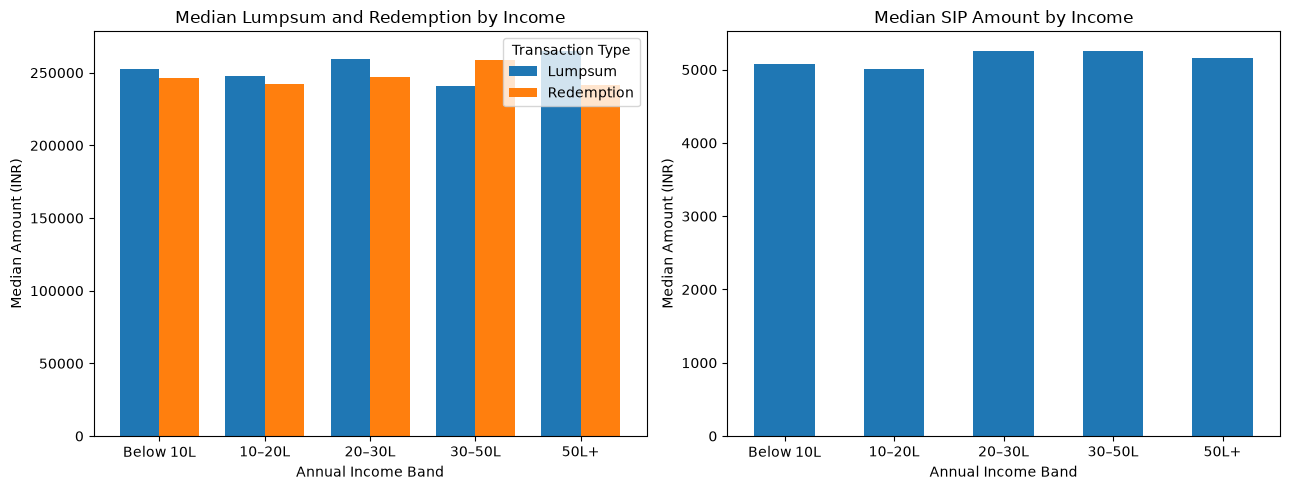

In [205]:
income_median_pivot = income_amount_by_type.pivot(
    index="income_band",
    columns="transaction_type",
    values="median_amount_inr"
)

income_median_pivot = income_median_pivot.reindex(
    ["Below 10L", "10–20L", "20–30L", "30–50L", "50L+"]
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

income_median_pivot[["Lumpsum", "Redemption"]].plot(
    kind="bar",
    ax=axes[0],
    width=0.75
)

axes[0].set_title("Median Lumpsum and Redemption by Income")
axes[0].set_xlabel("Annual Income Band")
axes[0].set_ylabel("Median Amount (INR)")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Transaction Type")

income_median_pivot[["SIP"]].plot(
    kind="bar",
    ax=axes[1],
    width=0.55,
    legend=False
)

axes[1].set_title("Median SIP Amount by Income")
axes[1].set_xlabel("Annual Income Band")
axes[1].set_ylabel("Median Amount (INR)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### Median Transaction Amounts by Income Band — Visualisation

The charts compare median lumpsum, redemption and SIP amounts across five annual income bands.

- The ₹50 lakh+ group had the highest median lumpsum amount at ₹2,65,220.
- The ₹30–50 lakh group had the highest median redemption amount at ₹2,58,817.50.
- The ₹30–50 lakh group also had the highest median SIP amount at ₹5,260.
- Median SIP amounts showed relatively little variation across income bands compared with lumpsum and redemption amounts.

There was no consistent increase in median transaction size as annual income increased. These descriptive patterns apply only to the supplied synthetic dataset and do not establish causal relationships.